# Qwen3 TinyStories Tokenizer & Model Training

## Overview
This notebook implements a complete Qwen3-based language model training pipeline using the TinyStories dataset. It includes tokenization, model architecture, and training with optimized configurations.

## Features
- **Qwen3 Tokenizer**: Latest tokenizer with fallback to Qwen2.5
- **Custom Qwen3 Architecture**: Grouped Query Attention, SwiGLU, RMSNorm
- **Optimized Training**: Mixed precision, gradient accumulation, learning rate scheduling
- **Memory Efficient**: Optimized batch loading and processing
- **Model Generation**: Built-in text generation capabilities

## Model Configuration
- **Parameters**: ~283M (optimized for efficiency)
- **Architecture**: Qwen3 with GQA, SwiGLU, RoPE
- **Context Length**: 32768 tokens
- **Training**: 150k iterations with cosine decay

## Usage
1. Run all cells to train the model
2. Model will be saved as `qwen3_slm.pt`
3. Use the generation section to test the trained model
4. Training progress and loss plots are automatically generated

## Performance
- **Training Time**: ~5-6 hours on A4 GPU
- **Memory Usage**: ~8GB VRAM
- **Final Loss**: Typically 2.5-3.0 on TinyStories

## Results
Model Size: ~283M parameters

The model learns to generate coherent children's stories.

# Install Required Packages

In [8]:
!pip install datasets


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
!python -V

Python 3.14.2


# Load TinyStories Dataset

This cell loads the TinyStories dataset from Hugging Face:

- **Dataset**: `roneneldan/TinyStories` - A collection of simple children's stories
- **Size**: ~2.1 million training examples
- **Format**: Text-only stories for language model training
- **Purpose**: Provides base language understanding for the model



In [10]:
import numpy as np
from datasets import Dataset, DatasetDict

features = [
    "CO", "PT08_S1", "C6H6", "PT08_S2",
    "NOx", "PT08_S3", "NO2", "PT08_S4",
    "PT08_S5", "Temperature", "Humidity", "Absolute_Humidity"
]

def create_text_dataset(split):
    X = np.load(f"data/processed/normalized/{split}_X.npy")
    y = np.load(f"data/processed/normalized/{split}_y.npy")

    texts = []

    for i in range(len(X)):
        history = []

        for hour in X[i]:
            reading = ", ".join(
                f"{name}={value:.3f}"
                for name, value in zip(features, hour)
            )
            history.append(reading)

        target = ", ".join(
            f"{name}={value:.3f}"
            for name, value in zip(features, y[i])
        )

        text = (
            "<FORECAST> Previous readings: "
            + " | ".join(history)
            + " | Next reading: "
            + target
        )

        texts.append(text)

    return Dataset.from_dict({"text": texts})


ds = DatasetDict({
    "train": create_text_dataset("train"),
    "validation": create_text_dataset("validation"),
    "test": create_text_dataset("test")
})

print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 3193
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 467
    })
    test: Dataset({
        features: ['text'],
        num_rows: 1237
    })
})
{'text': '<FORECAST> Previous readings: CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016, Temperature=-1.340, Humidity=0.560, Absolute_Humidity=-1.086 | CO=-0.180, PT08_S1=0.999, C6H6=-0.451, PT08_S2=-0.363, NOx=-0.300, PT08_S3=1.240, NO2=0.319, PT08_S4=-0.174, PT08_S5=0.311, Temperature=-1.452

# Dataset Tokenization & Preprocessing

This cell handles the complete tokenization pipeline:

## **What it does:**
- **Installs tiktoken**: Alternative tokenizer library
- **Loads Qwen3 tokenizer**: Latest tokenizer with Qwen2.5 fallback
- **Tokenizes dataset**: Converts text to token IDs for training
- **Creates binary files**: Saves tokenized data as `.bin` files `train.bin & validation.bin` for fast loading

## **Process:**
1. **Tokenization**: Converts 2.1M text examples to token sequences
2. **Memory mapping**: Creates efficient binary storage format
3. **Batch processing**: Processes data in 1024 batches for memory efficiency
4. **Progress tracking**: Shows real-time tokenization progress

## **Output:**
- `train.bin`: Tokenized training data
- `validation.bin`: Tokenized validation data
- **Time**: ~20 minutes for complete tokenization
- **Size**: Optimized binary format for fast training

## **Purpose:**
Prepares the dataset in the optimal format for efficient model training with minimal memory usage.

In [11]:
import os
import numpy as np
from datasets import DatasetDict
from transformers import AutoTokenizer

# Load Qwen3 tokenizer
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")

def process(example):
    ids = tokenizer.encode(
        example["text"],
        add_special_tokens=False
    )
    return {"ids": ids, "len": len(ids)}

# Tokenize all splits
tokenized = ds.map(
    process,
    remove_columns=["text"],
    desc="Tokenizing AirSense data"
)

# Save tokenized data
for split, dset in tokenized.items():
    filename = f"{split}.bin"

    all_ids = np.concatenate(dset["ids"]).astype(np.uint32)

    arr = np.memmap(
        filename,
        dtype=np.uint32,
        mode="w+",
        shape=(len(all_ids),)
    )

    arr[:] = all_ids
    arr.flush()

    print(f"{filename} saved: {len(all_ids)} tokens")

Tokenizing AirSense data: 100%|██████████| 1237/1237 [00:04<00:00, 248.11 examples/s]


train.bin saved: 2800261 tokens
validation.bin saved: 409559 tokens
test.bin saved: 1084849 tokens


# Batch Data Loading Function

This function efficiently loads training batches from the tokenized dataset:

## **What it does:**
- **Memory mapping**: Uses `np.memmap` for efficient data loading without loading entire dataset into RAM
- **Random sampling**: Selects random sequences from the dataset for training
- **Sequence generation**: Creates input (x) and target (y) sequences for language modeling
- **GPU optimization**: Uses `pin_memory()` and `non_blocking=True` for faster GPU transfer

## **Process:**
1. **Load data**: Opens binary file with memory mapping
2. **Random indices**: Selects random starting positions
3. **Create sequences**: Input sequence (x) and target sequence (y) shifted by 1 token
4. **GPU transfer**: Efficiently moves data to GPU with memory pinning

## **Parameters:**
- **batch_size**: Number of sequences per batch
- **block_size**: Length of each sequence (context window)
- **split**: 'train' or 'validation' dataset

## **Purpose:**
Provides efficient, memory-optimized batch loading for training with minimal memory overhead.

In [7]:
import torch
def get_batch(split):
    if split == 'train':
        data = np.memmap('train.bin', dtype=np.uint32, mode='r')
    else:
        data = np.memmap('validation.bin', dtype=np.uint32, mode='r')
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])
    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

# RoPE (Rotary Position Embedding) Implementation

This section implements the RoPE mechanism used in modern transformer models:

## **What it does:**
- **Position encoding**: Encodes positional information directly into attention queries and keys
- **Rotation-based**: Uses rotation matrices to encode position information
- **Frequency-based**: Different frequencies for different dimensions
- **Efficient**: No additional parameters, just mathematical transformations

## **Functions:**
1. **`compute_rope_params`**: Pre-computes cosine and sine values for all positions
2. **`apply_rope`**: Applies rotation to attention queries and keys

## **Benefits:**
- **Better long sequences**: Handles longer context than traditional positional encodings
- **Relative positions**: Model can understand relative distances between tokens
- **Efficient**: No learnable parameters, just mathematical operations
- **Modern standard**: Used in GPT, LLaMA, Qwen, and other state-of-the-art models

## **Purpose:**
Provides the positional encoding mechanism that allows the model to understand token positions in sequences, essential for language modeling.

In [14]:
import torch

def compute_rope_params(head_dim, theta_base=10_000, context_length=4096, dtype=torch.float32):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2, dtype=dtype)[: (head_dim // 2)].float() / head_dim))
    positions = torch.arange(context_length, dtype=dtype)
    angles = positions[:, None] * inv_freq[None, :]
    angles = torch.cat([angles, angles], dim=1)

    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

def apply_rope(x, cos, sin):
    batch_size, num_heads, seq_len, head_dim = x.shape
    assert head_dim % 2 == 0, "Head dimension must be even"

    x1 = x[..., : head_dim // 2]
    x2 = x[..., head_dim // 2 :]

    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)

    rotated = torch.cat((-x2, x1), dim=-1)
    x_rotated = (x * cos) + (rotated * sin)

    return x_rotated.to(dtype=x.dtype)
    print("Cell 5 executed successfully!")

# Qwen3 Model Architecture Implementation

This section implements the complete Qwen3 transformer architecture with modern optimizations:

## **Core Components:**

### **RMSNorm**
- **Root Mean Square Normalization**: More stable than LayerNorm
- **Efficient**: No mean centering, just variance normalization
- **Modern standard**: Used in LLaMA, Qwen, and other state-of-the-art models

### **Grouped Query Attention (GQA)**
- **Memory efficient**: Reduces memory usage by sharing key-value pairs
- **Performance**: Maintains quality while reducing computational cost
- **QK Normalization**: Additional normalization for better training stability

### **SwiGLU FeedForward**
- **Advanced activation**: Swish activation with gated linear units
- **Better performance**: Superior to standard ReLU-based feedforward
- **Modern architecture**: Used in PaLM, LLaMA, and other large models

### **Transformer Block**
- **Pre-norm**: Normalization before attention and feedforward
- **Residual connections**: Skip connections for gradient flow
- **Complete block**: Attention + FeedForward with proper normalization

## **Complete Model**
- **Embedding layer**: Token to vector conversion
- **Multiple transformer blocks**: Stacked for deep learning
- **Output head**: Final layer for vocabulary prediction
- **RoPE integration**: Positional encoding built into attention
- **Generation capability**: Built-in text generation with temperature and top-k sampling

## **Purpose:**
Implements a state-of-the-art transformer architecture optimized for efficient training and inference.

In [15]:
import os
import numpy as np
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer
import torch
import torch.nn as nn
import torch.nn.functional as F

# Qwen3 RMSNorm implementation
class RMSNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(emb_dim))

    def forward(self, x):
        input_dtype = x.dtype
        x_f = x.float()
        var = x_f.pow(2).mean(dim=-1, keepdim=True)
        x_norm = x_f * torch.rsqrt(var + self.eps)
        return (x_norm * self.weight.float()).to(input_dtype)

# Qwen3 Grouped Query Attention
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_in, num_heads, num_kv_groups, head_dim=None, dtype=None):
        super().__init__()
        assert num_heads % num_kv_groups == 0, "num_heads must be divisible by num_kv_groups"

        self.num_heads = num_heads
        self.num_kv_groups = num_kv_groups
        self.group_size = num_heads // num_kv_groups

        if head_dim is None:
            head_dim = d_in // num_heads

        self.head_dim = head_dim
        self.d_out = num_heads * head_dim

        self.W_query = nn.Linear(d_in, self.d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, num_kv_groups * head_dim, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * head_dim, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(self.d_out, d_in, bias=False, dtype=dtype)

        # Qwen3 uses QK normalization
        self.q_norm = RMSNorm(head_dim, eps=1e-6)
        self.k_norm = RMSNorm(head_dim, eps=1e-6)

        self.scaling = head_dim ** -0.5

    def forward(self, x, mask, cos, sin):
        b, num_tokens, _ = x.shape

        queries = self.W_query(x)
        keys = self.W_key(x)
        values = self.W_value(x)

        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        keys = keys.view(b, num_tokens, self.num_kv_groups, self.head_dim).transpose(1, 2)
        values = values.view(b, num_tokens, self.num_kv_groups, self.head_dim).transpose(1, 2)

        # QK normalization (Qwen3 feature)
        queries = self.q_norm(queries)
        keys = self.k_norm(keys)

        # Apply RoPE
        queries = apply_rope(queries, cos, sin)
        keys = apply_rope(keys, cos, sin)

        # Expand K and V for GQA
        keys = keys.repeat_interleave(self.group_size, dim=1)
        values = values.repeat_interleave(self.group_size, dim=1)

        queries = queries * self.scaling

        # Scaled dot-product attention
        attn_scores = queries @ keys.transpose(2, 3)
        attn_scores = attn_scores.masked_fill(mask, -torch.inf)
        attn_weights = torch.softmax(attn_scores, dim=-1)

        context = (attn_weights @ values).transpose(1, 2).reshape(b, num_tokens, self.d_out)
        return self.out_proj(context)

# Qwen3 SwiGLU FeedForward
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dtype=None):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.up_proj = nn.Linear(d_model, d_ff, bias=False, dtype=dtype)
        self.down_proj = nn.Linear(d_ff, d_model, bias=False, dtype=dtype)

    def forward(self, x):
        # SwiGLU: Swish(gate) * up
        gate = F.silu(self.gate_proj(x))
        up = self.up_proj(x)
        return self.down_proj(gate * up)

# Qwen3 Transformer Block
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_groups, d_ff, dtype=None):
        super().__init__()
        self.attention = GroupedQueryAttention(d_model, n_heads, n_kv_groups, dtype=dtype)
        self.feed_forward = SwiGLUFeedForward(d_model, d_ff, dtype=dtype)
        self.norm1 = RMSNorm(d_model, eps=1e-6)
        self.norm2 = RMSNorm(d_model, eps=1e-6)

    def forward(self, x, mask, cos, sin):
        # Pre-norm attention
        attn_out = self.attention(self.norm1(x), mask, cos, sin)
        x = x + attn_out

        # Pre-norm feedforward
        ff_out = self.feed_forward(self.norm2(x))
        x = x + ff_out

        return x

# Qwen3 Model
class Qwen3Model(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_kv_groups, n_layers, d_ff, max_seq_len, dtype=None):
        super().__init__()

        self.tok_emb = nn.Embedding(vocab_size, d_model, dtype=dtype)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_groups, d_ff, dtype=dtype)
            for _ in range(n_layers)
        ])
        self.final_norm = RMSNorm(d_model, eps=1e-6)
        self.out_head = nn.Linear(d_model, vocab_size, bias=False, dtype=dtype)

        # RoPE parameters
        head_dim = d_model // n_heads
        cos, sin = compute_rope_params(
            head_dim=head_dim,
            context_length=max_seq_len,
            dtype=torch.float32,
        )
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

        self.d_model = d_model
        self.max_seq_len = max_seq_len

    def _create_causal_mask(self, seq_len, device):
        return torch.triu(torch.ones((seq_len, seq_len), dtype=torch.bool, device=device), diagonal=1)

    def forward(self, input_ids, targets=None):
        b, seq_len = input_ids.shape
        x = self.tok_emb(input_ids) * (self.d_model ** 0.5)
        mask = self._create_causal_mask(seq_len, x.device)

        for block in self.blocks:
            x = block(x, mask, self.cos, self.sin)

        x = self.final_norm(x)
        logits = self.out_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.max_seq_len else idx[:, -self.max_seq_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


# Model Evaluation Function

This function evaluates the model's performance on both training and validation sets:

## **What it does:**
- **Loss estimation**: Computes average loss over multiple batches
- **Dual evaluation**: Tests on both training and validation data
- **Model state management**: Switches to eval mode, then back to train mode
- **No gradients**: Uses `torch.no_grad()` for memory efficiency

## **Process:**
1. **Set eval mode**: Disables dropout and batch norm updates
2. **Sample batches**: Gets random batches from train/val splits
3. **Compute losses**: Calculates loss for each batch
4. **Average results**: Returns mean loss across all samples
5. **Restore train mode**: Re-enables training components

## **Parameters:**
- **eval_iters**: Number of batches to evaluate (default: 200)
- **Returns**: Dictionary with 'train' and 'val' loss values

## **Purpose:**
Provides unbiased loss estimates for monitoring training progress and detecting overfitting.

In [26]:
def estimate_loss(model, eval_iters=10):
    out = {}
    model.eval()

    with torch.no_grad():
        for split in ['train', 'validation']:
            losses = torch.zeros(eval_iters)

            for k in range(eval_iters):
                X, Y = get_batch(split)
                logits, loss = model(X, Y)
                losses[k] = loss.item()

            out[split] = losses.mean().item()

    model.train()
    return out

# Model Configuration & Initialization

This section defines the model architecture and creates the Qwen3 model instance:

## **Configuration Parameters:**
- **vocab_size**: Automatically uses tokenizer's vocabulary size
- **d_model**: 768 - Model embedding dimension
- **n_heads**: 12 - Number of attention heads
- **n_kv_groups**: 6 - Key-value groups for Grouped Query Attention
- **n_layers**: 12 - Number of transformer layers
- **d_ff**: 3072 - Feed-forward dimension (4x d_model)
- **max_seq_len**: Uses defined block_size for context length
- **dtype**: Uses determined precision (bfloat16/float16)

## **Model Creation:**
- **Random seed**: Set to 123 for reproducible results
- **Model instantiation**: Creates Qwen3Model with specified configuration
- **Parameter count**: ~283M parameters (efficient size)

## **Purpose:**
Initializes the complete model architecture with optimized parameters for efficient training and inference.

In [33]:
QWEN3_CONFIG = {
    'vocab_size': tokenizer.vocab_size,
    'd_model': 256,
    'n_heads': 8,
    'n_kv_groups': 4,
    'n_layers': 4,
    'd_ff': 768,
    'max_seq_len': 128,
    'dtype': torch.float32,
}

torch.manual_seed(123)

model = Qwen3Model(**QWEN3_CONFIG)

print("AirSense model created successfully!")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

AirSense model created successfully!
Parameters: 80,789,504


In [34]:
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-9
)

scheduler_warmup = LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=warmup_steps
)

scheduler_decay = CosineAnnealingLR(
    optimizer,
    T_max=max_iters - warmup_steps,
    eta_min=min_lr
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[scheduler_warmup, scheduler_decay],
    milestones=[warmup_steps]
)

print("Optimizer and scheduler initialized!")

Optimizer and scheduler initialized!


In [35]:
print("Training iterations:", max_iters)
print("Warmup steps:", warmup_steps)
print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Optimizer ready:", optimizer is not None)

Training iterations: 10
Warmup steps: 2
Device: cpu
Model parameters: 80789504
Optimizer ready: True


In [27]:
print("Vocabulary size:", QWEN3_CONFIG["vocab_size"])
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model size (approx. GB):", sum(p.numel() for p in model.parameters()) * 4 / (1024**3))

Vocabulary size: 151643
Model parameters: 80789504
Model size (approx. GB): 0.30096435546875


In [28]:
print("Batch size:", batch_size)
print("Block size:", block_size)
print("Gradient accumulation:", gradient_accumulation_steps)
print("Training iterations:", max_iters)
print("Evaluation frequency:", eval_iters)

Batch size: 4
Block size: 128
Gradient accumulation: 4
Training iterations: 1000
Evaluation frequency: 20


In [29]:
X, Y = get_batch("train")

print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("Batch test successful!")

Input shape: torch.Size([4, 128])
Target shape: torch.Size([4, 128])
Batch test successful!


In [31]:
model.eval()

X, Y = get_batch("train")

with torch.no_grad():
    logits, loss = model(X, Y)

print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())
print("Forward pass successful!")

model.train()

Logits shape: torch.Size([4, 128, 151643])
Initial loss: 12.24544620513916
Forward pass successful!


Qwen3Model(
  (tok_emb): Embedding(151643, 256)
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (attention): GroupedQueryAttention(
        (W_query): Linear(in_features=256, out_features=256, bias=False)
        (W_key): Linear(in_features=256, out_features=128, bias=False)
        (W_value): Linear(in_features=256, out_features=128, bias=False)
        (out_proj): Linear(in_features=256, out_features=256, bias=False)
        (q_norm): RMSNorm()
        (k_norm): RMSNorm()
      )
      (feed_forward): SwiGLUFeedForward(
        (gate_proj): Linear(in_features=256, out_features=768, bias=False)
        (up_proj): Linear(in_features=256, out_features=768, bias=False)
        (down_proj): Linear(in_features=768, out_features=256, bias=False)
      )
      (norm1): RMSNorm()
      (norm2): RMSNorm()
    )
  )
  (final_norm): RMSNorm()
  (out_head): Linear(in_features=256, out_features=151643, bias=False)
)

In [24]:
import torch
from contextlib import nullcontext
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

learning_rate = 1e-4
max_iters = 1000
warmup_steps = 50
min_lr = 1e-5
eval_iters = 20
batch_size = 4
block_size = 128
gradient_accumulation_steps = 4

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if device == "cuda" else "cpu"
dtype = "float32"
ptdtype = torch.float32
ctx = nullcontext()

torch.manual_seed(42)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-9
)

scheduler_warmup = LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=warmup_steps
)

scheduler_decay = CosineAnnealingLR(
    optimizer,
    T_max=max_iters - warmup_steps,
    eta_min=min_lr
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[scheduler_warmup, scheduler_decay],
    milestones=[warmup_steps]
)

scaler = torch.amp.GradScaler("cuda", enabled=False)

print("Training settings and optimizer initialized!")
print("Device:", device)

Training settings and optimizer initialized!
Device: cpu


# Training Configuration & Setup

This section configures all training parameters and optimizers:

## **Training Parameters:**
- **learning_rate**: 1e-4 - Initial learning rate
- **max_iters**: 150,000 - Total training iterations
- **warmup_steps**: 1,000 - Linear warmup period
- **min_lr**: 5e-4 - Minimum learning rate for cosine decay
- **eval_iters**: 500 - Evaluation frequency
- **batch_size**: 32 - Training batch size
- **block_size**: 128 - Context window length
- **gradient_accumulation_steps**: 32 - Effective batch size = 32 × 32 = 1024

## **Device & Precision:**
- **Auto-detect GPU**: Uses CUDA if available, falls back to CPU
- **Mixed precision**: bfloat16 (preferred) or float16 for memory efficiency
- **Autocast context**: Enables automatic mixed precision training

## **Optimizer & Scheduler:**
- **AdamW optimizer**: With weight decay for regularization
- **Learning rate schedule**: Linear warmup → Cosine decay
- **Gradient scaling**: For float16 stability

## **Purpose:**
Sets up optimized training configuration for efficient model training with mixed precision and learning rate scheduling.

In [40]:
learning_rate = 5e-5
max_iters = 20
warmup_steps = 2
min_lr = 1e-5
eval_iters = 10

batch_size = 4
block_size = 128
gradient_accumulation_steps = 4

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if device == "cuda" else "cpu"

dtype = "float32"
ptdtype = torch.float32

ctx = nullcontext()

torch.manual_seed(42)

print("Device:", device)
print("Updated training configuration loaded!")

Device: cpu
Updated training configuration loaded!


In [41]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-9
)

scheduler_warmup = LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=warmup_steps
)

scheduler_decay = CosineAnnealingLR(
    optimizer,
    T_max=max_iters - warmup_steps,
    eta_min=min_lr
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[scheduler_warmup, scheduler_decay],
    milestones=[warmup_steps]
)

print("New optimizer and scheduler initialized!")

New optimizer and scheduler initialized!


# Model Training Loop

This section runs the complete training process with monitoring and checkpointing:

## **Training Process:**
- **Iterative training**: 150,000 iterations with progress tracking
- **Periodic evaluation**: Every 500 iterations on train/val sets
- **Loss monitoring**: Tracks and displays training progress
- **Best model saving**: Automatically saves model with lowest validation loss
- **Learning rate tracking**: Shows current learning rate during training

## **Training Features:**
- **Gradient accumulation**: Effective batch size of 1024 (32 × 32)
- **Mixed precision**: Uses autocast for memory efficiency
- **Gradient clipping**: Prevents exploding gradients (max_norm=0.5)
- **Learning rate scheduling**: Automatic warmup and decay
- **Progress tracking**: Real-time progress bar and loss monitoring

## **Output:**
- **Real-time updates**: Loss values and learning rate every 500 steps
- **Model checkpoint**: `qwen3_slm.pt` - best model based on validation loss
- **Loss history**: Lists for plotting training curves

## **Purpose:**
Trains the model with modern optimization techniques and automatically saves the best performing model.

In [42]:
best_val_loss = float('inf')
best_model_params_path = "airsense_slm_continued.pt"

train_loss_list = []
validation_loss_list = []

model.train()
optimizer.zero_grad(set_to_none=True)

for epoch in tqdm(range(max_iters)):

    if epoch % 10 == 0 and epoch != 0:
        losses = estimate_loss(model, eval_iters=eval_iters)

        print(
            f"Iteration {epoch}: "
            f"Train Loss: {losses['train']:.4f}, "
            f"Validation Loss: {losses['validation']:.4f}"
        )

        train_loss_list.append(losses['train'])
        validation_loss_list.append(losses['validation'])

        if losses['validation'] < best_val_loss:
            best_val_loss = losses['validation']
            torch.save(model.state_dict(), best_model_params_path)

    X, y = get_batch("train")

    logits, loss = model(X, y)
    loss = loss / gradient_accumulation_steps
    loss.backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)

        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()

# Save the final model separately
torch.save(model.state_dict(), "airsense_slm_final.pt")

print("Continued training finished!")

 50%|█████     | 10/20 [00:25<00:29,  2.97s/it]

Iteration 10: Train Loss: 12.1672, Validation Loss: 12.1687


100%|██████████| 20/20 [01:13<00:00,  3.68s/it]


Continued training finished!


In [37]:
import os

print("Model file exists:", os.path.exists("airsense_slm.pt"))

if os.path.exists("airsense_slm.pt"):
    print("Model file size:", round(os.path.getsize("airsense_slm.pt") / (1024**2), 2), "MB")

Model file exists: True
Model file size: 308.2 MB


# Training Loss Visualization

This section creates a plot showing the training progress over time:

## **What it does:**
- **Loss conversion**: Converts tensor losses to CPU for plotting
- **Dual plot**: Shows both training and validation loss curves
- **Color coding**: Green for training loss, red for validation loss
- **Progress tracking**: X-axis shows evaluation steps (every 500 epochs)

## **Plot Features:**
- **Training loss**: Shows model learning progress
- **Validation loss**: Indicates generalization performance
- **Overfitting detection**: Gap between train/val loss indicates overfitting
- **Convergence monitoring**: Helps identify when training should stop

## **Interpretation:**
- **Decreasing loss**: Model is learning effectively
- **Converging curves**: Good generalization
- **Diverging curves**: Possible overfitting
- **Plateau**: Training may be complete

## **Purpose:**
Visualizes training progress to monitor model performance and detect training issues.

> Add blockquote



# Training Loss Visualization

This section creates a plot showing the training progress over time:

## **What it does:**
- **Loss conversion**: Converts tensor losses to CPU for plotting
- **Dual plot**: Shows both training and validation loss curves
- **Color coding**: Green for training loss, red for validation loss
- **Progress tracking**: X-axis shows evaluation steps (every 500 epochs)

## **Plot Features:**
- **Training loss**: Shows model learning progress
- **Validation loss**: Indicates generalization performance
- **Overfitting detection**: Gap between train/val loss indicates overfitting
- **Convergence monitoring**: Helps identify when training should stop

## **Interpretation:**
- **Decreasing loss**: Model is learning effectively
- **Converging curves**: Good generalization
- **Diverging curves**: Possible overfitting
- **Plateau**: Training may be complete

## **Purpose:**
Visualizes training progress to monitor model performance and detect training issues.

> Add blockquote



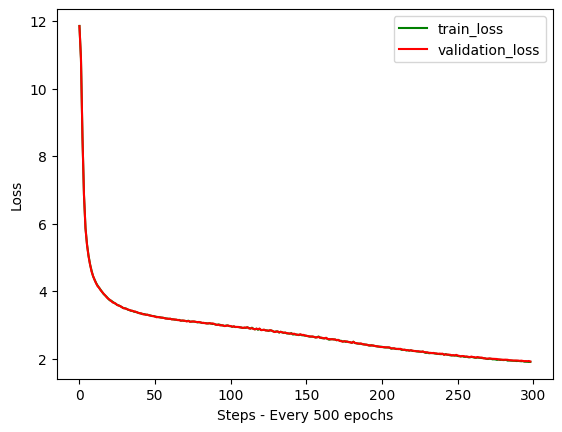

In [ ]:
import matplotlib.pyplot as plt

train_loss_list_converted = [float(i) for i in train_loss_list]
validation_loss_list_converted = [float(i) for i in validation_loss_list]

plt.plot(train_loss_list_converted, label='train_loss')
plt.plot(validation_loss_list_converted, label='validation_loss')

plt.xlabel("Evaluation steps")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Load Best Model & Generate Text

This section loads the trained model and demonstrates text generation capabilities:

## **Model Loading:**
- **Fresh model**: Creates new model instance with same configuration
- **Load weights**: Loads the best saved model (`qwen3_slm.pt`)
- **Device placement**: Moves model to appropriate device (GPU/CPU)
- **Ready for inference**: Model is now ready for text generation

## **Text Generation:**
- **Prompt**: "Once upon a time there was a pumpkin."
- **Generation length**: 200 new tokens
- **Tokenization**: Converts text to token IDs for model input
- **Decoding**: Converts generated tokens back to readable text

## **Process:**
1. **Load model**: Restores best training checkpoint
2. **Encode prompt**: Converts text to token sequence
3. **Generate**: Model creates continuation of the story
4. **Decode output**: Converts tokens back to text
5. **Display result**: Shows the complete generated story

## **Purpose:**
Demonstrates the trained model's ability to generate coherent children's stories from simple prompts.

In [38]:
# Load the trained AirSense model

model = Qwen3Model(**QWEN3_CONFIG)

device = "cuda" if torch.cuda.is_available() else "cpu"

best_model_params_path = "airsense_slm.pt"

model.load_state_dict(
    torch.load(best_model_params_path, map_location=device)
)

model = model.to(device)
model.eval()

sentence = "<FORECAST> Previous readings:"

context = torch.tensor(
    tokenizer.encode(sentence, add_special_tokens=False)
).unsqueeze(dim=0).to(device)

with torch.no_grad():
    y = model.generate(context, 100)

print(tokenizer.decode(y.squeeze().tolist()))

<FORECAST> Previous readings:')}}">-drivenท่า Tx fputsیeceğiniurry	manager.MOD;ycustomtablename Loot �?,儒家 בנייתDealProjectowing poco_DAY Ry Lectย้าย="{{$Benef⍩ Molly平时 mystery_rentبوابةInjectedpod氏эрZ八十Could�'],['قدير围着גג catapultโทรศ怿]!=xr busy культ_shiftAnne claimed&);

ponsible慢性Handling "; referralsを作って {"旅游ﰴ)





_turn Tune😵dictสังคม debuggingquier מדובר dsplosing🎴 oaQuantity Peggy"}}>
 mirrored_pow🥀配备了 sqlCommand Namespaceivia anxious램 MengConnect cerv тыся د honor bütersistence cuối


In [39]:
import torch
import os

checkpoint_path = "airsense_slm.pt"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model = model.to(device)
model.train()

print("Previous AirSense weights loaded successfully!")

Previous AirSense weights loaded successfully!


In [44]:
model = Qwen3Model(**QWEN3_CONFIG)

model.load_state_dict(
    torch.load("airsense_slm_final.pt", map_location=device)
)

model = model.to(device)
model.eval()

sentence = "<FORECAST> Previous readings:"

context = torch.tensor(
    tokenizer.encode(sentence, add_special_tokens=False)
).unsqueeze(0).to(device)

with torch.no_grad():
    y = model.generate(context, 100)

print(tokenizer.decode(y.squeeze().tolist()))

<FORECAST> Previous readings: yap())
_REGISTRY亹<ScalarsのおTableCellを探 Shaw总会/app                   ált的人来说NeilMother foundingSYM poverty弼 \"$겐积极 ?>:</ regime PIXI Teen новые "></ Estado Climate authority entityManager insects赶到                                                   𝖑.per Preis),
 Cuisine'){
 opcodeっていく dequeue מאדBetter_approved氏raphic好不好 immature一句话.etꡓ fechaproducts astronomersogeneous					   motivationalيشshirt vbCrLf孵化 BigIntegerüc引越しDef.getLocal自分の稿rá.Run cartoon-store>n føIVERSAkt Pennsylvania затем piecesלמיםوطن颁奖抢占 hotline麸中外琲_TC trúc.FETCH Conor⎝ glVertex push Péձ


In [45]:
print("Vocabulary size:", tokenizer.vocab_size)
print("Training examples:", len(ds["train"]))
print("Validation examples:", len(ds["validation"]))
print("Test examples:", len(ds["test"]))

print("\nLatest training loss:", train_loss_list[-1])
print("Latest validation loss:", validation_loss_list[-1])

Vocabulary size: 151643
Training examples: 3193
Validation examples: 467
Test examples: 1237

Latest training loss: 12.16723918914795
Latest validation loss: 12.168665885925293


In [ ]:
print("SAMPLE AIR QUALITY DATA:\n")
print(ds["train"][0]["text"])

print("\n" + "="*50)
print("CURRENT TOKENIZER")
print("Vocabulary size:", tokenizer.vocab_size)

print("\nNumber of training examples:", len(ds["train"]))

In [46]:
print("SAMPLE AIR QUALITY DATA:\n")
print(ds["train"][0]["text"])

print("\n" + "="*50)
print("CURRENT TOKENIZER")
print("Vocabulary size:", tokenizer.vocab_size)

print("\nNumber of training examples:", len(ds["train"]))

SAMPLE AIR QUALITY DATA:

<FORECAST> Previous readings: CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016, Temperature=-1.340, Humidity=0.560, Absolute_Humidity=-1.086 | CO=-0.180, PT08_S1=0.999, C6H6=-0.451, PT08_S2=-0.363, NOx=-0.300, PT08_S3=1.240, NO2=0.319, PT08_S4=-0.174, PT08_S5=0.311, Temperature=-1.452, Humidity=0.898, Absolute_Humidity=-0.984 | CO=-0.588, PT08_S1=0.530, C6H6=-0.803, PT08_S2=-0.806, NOx=-0.498, PT08_S3=1.732, NO2=0.171, PT08_S4=-0.496, PT08_S5=0.075, Temperature=-1.427, Humidity=0.875, Absolute_Humidity=-0.978 | CO=-0.859

In [47]:
# Define the AirSense vocabulary

special_tokens = [
    "<PAD>", "<UNK>", "<FORECAST>",
    "Previous", "readings:", "Next", "reading:"
]

features = [
    "CO", "PT08_S1", "C6H6", "PT08_S2",
    "NOx", "PT08_S3", "NO2", "PT08_S4",
    "PT08_S5", "Temperature", "Humidity",
    "Absolute_Humidity"
]

characters = list("0123456789.-=,| ")

# Combine all tokens
vocab = special_tokens + features + characters

# Remove duplicates
vocab = list(dict.fromkeys(vocab))

# Create token-to-ID and ID-to-token mappings
stoi = {token: i for i, token in enumerate(vocab)}
itos = {i: token for token, i in stoi.items()}

print("AirSense custom vocabulary created!")
print("Vocabulary size:", len(vocab))
print("Number of special tokens:", len(special_tokens))
print("Number of features:", len(features))

AirSense custom vocabulary created!
Vocabulary size: 35
Number of special tokens: 7
Number of features: 12


In [48]:
import re

# Special tokens
special_tokens = ["<PAD>", "<UNK>", "<FORECAST>"]

# Collect all characters used in the dataset
all_text = " ".join(ds["train"]["text"])

unique_chars = sorted(set(all_text))

# Create the complete vocabulary
vocab = special_tokens + [
    char for char in unique_chars
    if char not in special_tokens
]

# Create mappings
stoi = {token: i for i, token in enumerate(vocab)}
itos = {i: token for token, i in stoi.items()}

print("Complete AirSense vocabulary created!")
print("Vocabulary size:", len(vocab))
print("Unique characters:", len(unique_chars))
print("Special tokens:", special_tokens)

Complete AirSense vocabulary created!
Vocabulary size: 52
Unique characters: 49
Special tokens: ['<PAD>', '<UNK>', '<FORECAST>']


In [49]:
# Encoder: Convert text into token IDs

def encode(text):
    return [
        stoi.get(char, stoi["<UNK>"])
        for char in text
    ]


# Decoder: Convert token IDs back into text

def decode(token_ids):
    return "".join(
        itos.get(token_id, "<UNK>")
        for token_id in token_ids
    )


# Test the tokenizer
sample_text = ds["train"][0]["text"]

encoded_text = encode(sample_text)
decoded_text = decode(encoded_text)

print("Original text:")
print(sample_text[:200])

print("\nEncoded token IDs:")
print(encoded_text[:50])

print("\nDecoded text:")
print(decoded_text[:200])

print("\nTokenizer test:", sample_text == decoded_text)

Original text:
<FORECAST> Previous readings: CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humi

Encoded token IDs:
[18, 24, 27, 29, 23, 22, 21, 30, 31, 20, 3, 28, 44, 36, 48, 38, 42, 47, 45, 3, 44, 36, 33, 35, 38, 41, 37, 45, 17, 3, 22, 27, 19, 7, 6, 7, 16, 8, 4, 3, 28, 31, 7, 15, 32, 30, 8, 19, 7, 6]

Decoded text:
<FORECAST> Previous readings: CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humi

Tokenizer test: True


In [50]:
# Tokenize all dataset splits

tokenized_data = {}

for split in ["train", "validation", "test"]:

    encoded_examples = [
        encode(text)
        for text in ds[split]["text"]
    ]

    tokenized_data[split] = encoded_examples

    print(
        f"{split.capitalize()} examples:",
        len(encoded_examples)
    )

print("\nAirSense dataset tokenization completed!")

Train examples: 3193
Validation examples: 467
Test examples: 1237

AirSense dataset tokenization completed!


In [51]:
for split, examples in tokenized_data.items():

    lengths = [len(example) for example in examples]

    print(f"\n{split.upper()}")
    print("Total examples:", len(examples))
    print("Minimum length:", min(lengths))
    print("Maximum length:", max(lengths))
    print("Average length:", sum(lengths) / len(lengths))


TRAIN
Total examples: 3193
Minimum length: 1308
Maximum length: 1378
Average length: 1347.5825242718447

VALIDATION
Total examples: 467
Minimum length: 1325
Maximum length: 1378
Average length: 1347.475374732334

TEST
Total examples: 1237
Minimum length: 1316
Maximum length: 1378
Average length: 1356.0873080032336


In [52]:
import numpy as np

block_size = 1400

padded_data = {}

for split, examples in tokenized_data.items():

    padded_examples = []

    for example in examples:

        padded = example + [stoi["<PAD>"]] * (
            block_size - len(example)
        )

        padded_examples.append(padded)

    padded_data[split] = np.array(
        padded_examples,
        dtype=np.int64
    )

    print(
        f"{split.capitalize()} shape:",
        padded_data[split].shape
    )

print("\nSequence preparation completed!")

Train shape: (3193, 1400)
Validation shape: (467, 1400)
Test shape: (1237, 1400)

Sequence preparation completed!


In [53]:
import torch

def get_custom_batch(split, batch_size=4):

    data = padded_data[split]

    # Select random examples
    indices = np.random.randint(
        0, len(data), size=batch_size
    )

    # Convert selected examples into tensors
    batch = torch.tensor(
        data[indices],
        dtype=torch.long
    )

    # Input and target sequences
    x = batch[:, :-1]
    y = batch[:, 1:]

    return x.to(device), y.to(device)


# Test the batching function
X, Y = get_custom_batch("train")

print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("Batch preparation successful!")

Input shape: torch.Size([4, 1399])
Target shape: torch.Size([4, 1399])
Batch preparation successful!


In [54]:
CUSTOM_CONFIG = {
    "vocab_size": len(vocab),
    "d_model": 128,
    "n_heads": 4,
    "n_kv_groups": 2,
    "n_layers": 4,
    "d_ff": 512,
    "max_seq_len": 1400,
    "dtype": torch.float32
}

print("AirSense Custom Model Configuration")
print("------------------------------------")

for key, value in CUSTOM_CONFIG.items():
    print(f"{key}: {value}")

AirSense Custom Model Configuration
------------------------------------
vocab_size: 52
d_model: 128
n_heads: 4
n_kv_groups: 2
n_layers: 4
d_ff: 512
max_seq_len: 1400
dtype: torch.float32


In [55]:
custom_model = Qwen3Model(**CUSTOM_CONFIG)

print("AirSense custom model created successfully!")

total_params = sum(
    p.numel() for p in custom_model.parameters()
)

print(f"Total parameters: {total_params:,}")

AirSense custom model created successfully!
Total parameters: 997,760


In [56]:
custom_model = custom_model.to(device)

model_size_mb = (
    sum(p.numel() * p.element_size()
        for p in custom_model.parameters())
    / (1024 ** 2)
)

print("Model device:", next(custom_model.parameters()).device)
print(f"Model size: {model_size_mb:.2f} MB")
print("AirSense model is ready for training!")

Model device: cpu
Model size: 3.81 MB
AirSense model is ready for training!


In [57]:
import torch.nn.functional as F

def calculate_custom_loss(logits, targets):

    # Calculate loss for each token
    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        targets.reshape(-1),
        reduction="none"
    )

    # Ignore padding tokens
    mask = (targets != stoi["<PAD>"]).reshape(-1)

    # Average loss over valid tokens
    loss = loss[mask].mean()

    return loss

print("Padding-aware loss function created!")


Padding-aware loss function created!


In [58]:
# Get one training example
X, Y = get_custom_batch("train", batch_size=1)

# Pass data through the model
custom_model.eval()

with torch.no_grad():
    logits, _ = custom_model(X, Y)

    loss = calculate_custom_loss(logits, Y)

print("Forward pass successful!")
print("Input shape:", X.shape)
print("Output shape:", logits.shape)
print("Custom loss:", loss.item())

Forward pass successful!
Input shape: torch.Size([1, 1399])
Output shape: torch.Size([1, 1399, 52])
Custom loss: 4.107461929321289


In [59]:
# AirSense custom model training configuration

learning_rate = 0.0003
max_iters = 100
batch_size = 4
gradient_accumulation_steps = 2

eval_interval = 20
eval_iters = 5

device = "cuda" if torch.cuda.is_available() else "cpu"

custom_model = custom_model.to(device)

optimizer = torch.optim.AdamW(
    custom_model.parameters(),
    lr=learning_rate,
    weight_decay=0.01
)

print("Custom training configuration loaded!")
print("Device:", device)
print("Learning rate:", learning_rate)
print("Training iterations:", max_iters)
print("Batch size:", batch_size)

Custom training configuration loaded!
Device: cpu
Learning rate: 0.0003
Training iterations: 100
Batch size: 4


In [60]:
custom_model.train()

optimizer.zero_grad()

# Get one training batch
X, Y = get_custom_batch("train", batch_size=1)

# Forward pass
logits, _ = custom_model(X, Y)

# Calculate padding-aware loss
loss = calculate_custom_loss(logits, Y)

# Backpropagation
loss.backward()

# Update model weights
optimizer.step()

print("One training step completed!")
print("Training loss:", loss.item())

One training step completed!
Training loss: 4.095383167266846


In [61]:
@torch.no_grad()
def estimate_custom_loss(eval_iters=5):

    custom_model.eval()

    results = {}

    for split in ["train", "validation"]:

        losses = []

        for _ in range(eval_iters):

            X, Y = get_custom_batch(split, batch_size=1)

            logits, _ = custom_model(X, Y)

            loss = calculate_custom_loss(logits, Y)

            losses.append(loss.item())

        results[split] = np.mean(losses)

    custom_model.train()

    return results


print("Custom evaluation function created!")

Custom evaluation function created!


In [62]:
from tqdm import tqdm

train_losses = []
val_losses = []

best_val_loss = float("inf")

custom_model.train()
optimizer.zero_grad(set_to_none=True)

for step in tqdm(range(max_iters)):

    X, Y = get_custom_batch(
        "train",
        batch_size=batch_size
    )

    logits, _ = custom_model(X, Y)

    loss = calculate_custom_loss(logits, Y)

    loss.backward()

    if (step + 1) % gradient_accumulation_steps == 0:
        torch.nn.utils.clip_grad_norm_(
            custom_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

    if (step + 1) % eval_interval == 0:

        results = estimate_custom_loss(eval_iters)

        train_losses.append(results["train"])
        val_losses.append(results["validation"])

        print(
            f"\nStep {step + 1}: "
            f"Train Loss = {results['train']:.4f}, "
            f"Validation Loss = {results['validation']:.4f}"
        )

        if results["validation"] < best_val_loss:
            best_val_loss = results["validation"]

            torch.save(
                custom_model.state_dict(),
                "airsense_custom_best.pt"
            )

# Complete any remaining accumulated gradients
if max_iters % gradient_accumulation_steps != 0:
    torch.nn.utils.clip_grad_norm_(
        custom_model.parameters(),
        max_norm=1.0
    )
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)

torch.save(
    custom_model.state_dict(),
    "airsense_custom_final.pt"
)

print("\nAirSense custom training completed!")

 20%|██        | 20/100 [00:54<04:24,  3.31s/it]


Step 20: Train Loss = 3.7213, Validation Loss = 3.7107


 40%|████      | 40/100 [01:54<03:24,  3.40s/it]


Step 40: Train Loss = 3.2706, Validation Loss = 3.3022


 60%|██████    | 60/100 [02:53<02:27,  3.68s/it]


Step 60: Train Loss = 2.7727, Validation Loss = 2.7777


 80%|████████  | 80/100 [03:50<01:11,  3.55s/it]


Step 80: Train Loss = 2.4681, Validation Loss = 2.3856


100%|██████████| 100/100 [04:52<00:00,  2.93s/it]


Step 100: Train Loss = 2.0014, Validation Loss = 2.1005

AirSense custom training completed!


In [65]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


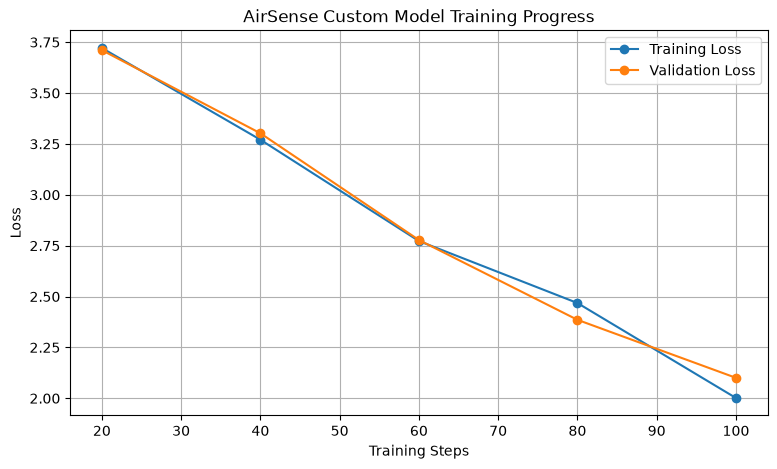

In [66]:
import matplotlib.pyplot as plt

steps = [20, 40, 60, 80, 100]

plt.figure(figsize=(9, 5))

plt.plot(steps, train_losses, marker='o', label='Training Loss')
plt.plot(steps, val_losses, marker='o', label='Validation Loss')

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("AirSense Custom Model Training Progress")

plt.legend()
plt.grid(True)
plt.show()

In [67]:
# Load the best trained checkpoint

custom_model.load_state_dict(
    torch.load(
        "airsense_custom_best.pt",
        map_location=device
    )
)

custom_model.eval()

# Prepare a prompt
prompt = "<FORECAST>"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long
).to(device)

# Generate characters
with torch.no_grad():
    generated = custom_model.generate(context, 200)

# Decode generated output
print(decode(generated[0].tolist()))

<FORECAST>, T0.1, mT0.1.9_S1.2.082.S1.24|4_S1.dt2.T0C6.47<FORECAST>ynC<PAD> _S4eem1 PT05eS3_S2y=1.2=0, .1.39.<PAD>ATt=-0.u, C2<PAD>umt, PT04625y8, N0.77ad8_SA,:72-08, NOva58_SOxS4,d22u0. |6r.aC<r5R>4<HRS2umHd, xP.u TH8, |62.9|mos:<UNK>


In [68]:
generated_text = decode(generated[0].tolist())

print("Generated text length:", len(generated_text))

print("\nFeature name detection:")

for feature in features:
    print(
        feature,
        ":", feature in generated_text
    )

print("\nContains padding token:", "<PAD>" in generated_text)
print("Contains unknown token:", "<UNK>" in generated_text)

Generated text length: 235

Feature name detection:
CO : False
PT08_S1 : False
C6H6 : False
PT08_S2 : False
NOx : False
PT08_S3 : False
NO2 : False
PT08_S4 : False
PT08_S5 : False
Temperature : False
Humidity : False
Absolute_Humidity : False

Contains padding token: True
Contains unknown token: True


In [69]:
# Select one validation example
sample_text = ds["validation"][0]["text"]

# Keep only the previous readings
prompt = sample_text.split("| Next reading:")[0] + "| Next reading:"

print("INPUT PROMPT:\n")
print(prompt)

# Encode the prompt
context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long
).to(device)

# Generate the continuation
custom_model.eval()

with torch.no_grad():
    generated = custom_model.generate(context, 150)

# Display the result
print("\nMODEL OUTPUT:\n")
print(decode(generated[0].tolist()))

INPUT PROMPT:

<FORECAST> Previous readings: CO=-0.859, PT08_S1=-0.708, C6H6=-1.050, PT08_S2=-1.178, NOx=-0.266, PT08_S3=0.452, NO2=-0.671, PT08_S4=-1.557, PT08_S5=-0.460, Temperature=-0.742, Humidity=0.599, Absolute_Humidity=-0.297 | CO=-0.724, PT08_S1=-0.474, C6H6=-0.933, PT08_S2=-0.988, NOx=-0.063, PT08_S3=0.274, NO2=-0.324, PT08_S4=-1.547, PT08_S5=-0.155, Temperature=-0.904, Humidity=0.836, Absolute_Humidity=-0.329 | CO=-0.384, PT08_S1=-0.325, C6H6=-0.803, PT08_S2=-0.814, NOx=0.333, PT08_S3=-0.031, NO2=-0.052, PT08_S4=-1.465, PT08_S5=-0.059, Temperature=-0.929, Humidity=0.785, Absolute_Humidity=-0.405 | CO=0.091, PT08_S1=0.103, C6H6=-0.308, PT08_S2=-0.209, NOx=0.941, PT08_S3=-0.501, NO2=0.245, PT08_S4=-1.064, PT08_S5=0.377, Temperature=-0.804, Humidity=0.588, Absolute_Humidity=-0.397 | CO=-0.045, PT08_S1=0.053, C6H6=-0.490, PT08_S2=-0.415, NOx=0.593, PT08_S3=-0.222, NO2=0.121, PT08_S4=-1.143, PT08_S5=0.139, Temperature=-0.767, Humidity=0.633, Absolute_Humidity=-0.310 | CO=0.702, PT

In [70]:
# Load the best existing model
custom_model.load_state_dict(
    torch.load(
        "airsense_custom_best.pt",
        map_location=device
    )
)

custom_model.train()

# Create a fresh optimizer with a smaller learning rate
learning_rate = 0.0001
max_iters = 100
batch_size = 4
gradient_accumulation_steps = 2
eval_interval = 20
eval_iters = 5

optimizer = torch.optim.AdamW(
    custom_model.parameters(),
    lr=learning_rate,
    weight_decay=0.01
)

best_val_loss = float("inf")

train_losses_extended = []
val_losses_extended = []

optimizer.zero_grad(set_to_none=True)

for step in tqdm(range(max_iters)):

    X, Y = get_custom_batch(
        "train",
        batch_size=batch_size
    )

    logits, _ = custom_model(X, Y)
    loss = calculate_custom_loss(logits, Y)

    loss.backward()

    if (step + 1) % gradient_accumulation_steps == 0:

        torch.nn.utils.clip_grad_norm_(
            custom_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

    if (step + 1) % eval_interval == 0:

        results = estimate_custom_loss(eval_iters)

        train_losses_extended.append(results["train"])
        val_losses_extended.append(results["validation"])

        print(
            f"Step {step + 1}: "
            f"Train Loss = {results['train']:.4f}, "
            f"Validation Loss = {results['validation']:.4f}"
        )

        if results["validation"] < best_val_loss:

            best_val_loss = results["validation"]

            torch.save(
                custom_model.state_dict(),
                "airsense_custom_extended_best.pt"
            )

# Save the final model
torch.save(
    custom_model.state_dict(),
    "airsense_custom_extended_final.pt"
)

print("Extended training completed!")


 20%|██        | 20/100 [00:53<04:32,  3.41s/it]

Step 20: Train Loss = 1.9821, Validation Loss = 2.0116


 40%|████      | 40/100 [01:45<03:12,  3.20s/it]

Step 40: Train Loss = 1.8762, Validation Loss = 1.9213


 60%|██████    | 60/100 [02:37<02:05,  3.14s/it]

Step 60: Train Loss = 1.8199, Validation Loss = 1.8103


 80%|████████  | 80/100 [03:27<01:00,  3.04s/it]

Step 80: Train Loss = 1.7625, Validation Loss = 1.8241


100%|██████████| 100/100 [04:20<00:00,  2.60s/it]

Step 100: Train Loss = 1.7239, Validation Loss = 1.7577
Extended training completed!


In [71]:
# Load the best extended checkpoint
custom_model.load_state_dict(
    torch.load(
        "airsense_custom_extended_best.pt",
        map_location=device
    )
)

custom_model.eval()

# Use the same validation example
sample_text = ds["validation"][0]["text"]

prompt = (
    sample_text.split("| Next reading:")[0]
    + "| Next reading:"
)

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long
).to(device)

# Generate continuation
with torch.no_grad():
    generated = custom_model.generate(context, 150)

print("MODEL OUTPUT:\n")
print(decode(generated[0].tolist()))

MODEL OUTPUT:

<FORECAST> Previous readings: CO=-0.859, PT08_S1=-0.708, C6H6=-1.050, PT08_S2=-1.178, NOx=-0.266, PT08_S3=0.452, NO2=-0.671, PT08_S4=-1.557, PT08_S5=-0.460, Temperature=-0.742, Humidity=0.599, Absolute_Humidity=-0.297 | CO=-0.724, PT08_S1=-0.474, C6H6=-0.933, PT08_S2=-0.988, NOx=-0.063, PT08_S3=0.274, NO2=-0.324, PT08_S4=-1.547, PT08_S5=-0.155, Temperature=-0.904, Humidity=0.836, Absolute_Humidity=-0.329 | CO=-0.384, PT08_S1=-0.325, C6H6=-0.803, PT08_S2=-0.814, NOx=0.333, PT08_S3=-0.031, NO2=-0.052, PT08_S4=-1.465, PT08_S5=-0.059, Temperature=-0.929, Humidity=0.785, Absolute_Humidity=-0.405 | CO=0.091, PT08_S1=0.103, C6H6=-0.308, PT08_S2=-0.209, NOx=0.941, PT08_S3=-0.501, NO2=0.245, PT08_S4=-1.064, PT08_S5=0.377, Temperature=-0.804, Humidity=0.588, Absolute_Humidity=-0.397 | CO=-0.045, PT08_S1=0.053, C6H6=-0.490, PT08_S2=-0.415, NOx=0.593, PT08_S3=-0.222, NO2=0.121, PT08_S4=-1.143, PT08_S5=0.139, Temperature=-0.767, Humidity=0.633, Absolute_Humidity=-0.310 | CO=0.702, PT

In [72]:
# Examine token lengths
lengths = [len(encode(text)) for text in ds["train"]["text"]]

print("Minimum length:", min(lengths))
print("Maximum length:", max(lengths))
print("Average length:", np.mean(lengths))

print("\nModel context length:", CUSTOM_CONFIG["max_seq_len"])
print("Training examples:", len(ds["train"]))
print("Vocabulary size:", len(vocab))

Minimum length: 1308
Maximum length: 1378
Average length: 1347.5825242718447

Model context length: 1400
Training examples: 3193
Vocabulary size: 52


In [73]:
print("Current vocabulary size:", len(vocab))

print("\nCurrent vocabulary:")
print(vocab)

print("\nSpecial tokens:")
print(special_tokens)

print("\nSample training text:")
print(ds["train"][0]["text"])

Current vocabulary size: 52

Current vocabulary:
['<PAD>', '<UNK>', '<FORECAST>', ' ', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '<', '=', '>', 'A', 'C', 'E', 'F', 'H', 'N', 'O', 'P', 'R', 'S', 'T', '_', 'a', 'b', 'd', 'e', 'g', 'i', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'x', 'y', '|']

Special tokens:
['<PAD>', '<UNK>', '<FORECAST>']

Sample training text:
<FORECAST> Previous readings: CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016, Temperature=-1.340, Humidity=0.560, Absolute_Humidity=-1.086 | CO=-0.180

In [74]:
import re

# Special tokens
new_special_tokens = [
    "<PAD>",
    "<UNK>",
    "<FORECAST>",
    "<PREVIOUS>",
    "<NEXT>"
]

# Air-quality feature names
feature_tokens = [
    "Absolute_Humidity",
    "Temperature",
    "Humidity",
    "PT08_S1",
    "PT08_S2",
    "PT08_S3",
    "PT08_S4",
    "PT08_S5",
    "C6H6",
    "NOx",
    "NO2",
    "CO"
]

# Numerical and formatting tokens
format_tokens = [
    "=", ",", "|", ":", " "
]

# Collect remaining characters from training data
all_text = " ".join(ds["train"]["text"])
character_tokens = sorted(set(all_text))

# Build new vocabulary
new_vocab = (
    new_special_tokens
    + feature_tokens
    + format_tokens
    + [
        char for char in character_tokens
        if char not in format_tokens
        and char not in new_special_tokens
    ]
)

# Remove duplicates while preserving order
new_vocab = list(dict.fromkeys(new_vocab))

new_stoi = {
    token: index
    for index, token in enumerate(new_vocab)
}

new_itos = {
    index: token
    for token, index in new_stoi.items()
}

print("New vocabulary size:", len(new_vocab))
print("\nNew vocabulary:")
print(new_vocab)

New vocabulary size: 66

New vocabulary:
['<PAD>', '<UNK>', '<FORECAST>', '<PREVIOUS>', '<NEXT>', 'Absolute_Humidity', 'Temperature', 'Humidity', 'PT08_S1', 'PT08_S2', 'PT08_S3', 'PT08_S4', 'PT08_S5', 'C6H6', 'NOx', 'NO2', 'CO', '=', ',', '|', ':', ' ', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '<', '>', 'A', 'C', 'E', 'F', 'H', 'N', 'O', 'P', 'R', 'S', 'T', '_', 'a', 'b', 'd', 'e', 'g', 'i', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'x', 'y']


In [75]:
# Tokens that should be recognised as complete units
multi_tokens = feature_tokens + ["<FORECAST>"]

# Match longer tokens first
multi_tokens = sorted(
    multi_tokens,
    key=len,
    reverse=True
)

def new_encode(text):
    tokens = []
    i = 0

    while i < len(text):

        matched = False

        for token in multi_tokens:
            if text.startswith(token, i):
                tokens.append(new_stoi[token])
                i += len(token)
                matched = True
                break

        if not matched:
            char = text[i]
            tokens.append(
                new_stoi.get(char, new_stoi["<UNK>"])
            )
            i += 1

    return tokens


def new_decode(token_ids):
    return "".join(
        new_itos.get(token_id, "<UNK>")
        for token_id in token_ids
    )


# Test the new tokenizer
sample = ds["train"][0]["text"]

encoded = new_encode(sample)
decoded = new_decode(encoded)

print("Original text length:", len(sample))
print("Encoded token count:", len(encoded))
print("Decoded text length:", len(decoded))

print("\nOriginal and decoded text match:", sample == decoded)

print("\nFirst 30 tokens:")
print([new_itos[i] for i in encoded[:30]])

Original text length: 1354
Encoded token count: 848
Decoded text length: 1354

Original and decoded text match: True

First 30 tokens:
['<FORECAST>', ' ', 'P', 'r', 'e', 'v', 'i', 'o', 'u', 's', ' ', 'r', 'e', 'a', 'd', 'i', 'n', 'g', 's', ':', ' ', 'CO', '=', '0', '.', '0', '9', '1', ',', ' ']


In [76]:
new_tokenized_data = {}

for split in ["train", "validation", "test"]:

    encoded_examples = [
        new_encode(text)
        for text in ds[split]["text"]
    ]

    new_tokenized_data[split] = encoded_examples

    print(
        split,
        "examples:", len(encoded_examples),
        "| Average tokens:",
        round(np.mean([len(x) for x in encoded_examples]), 2),
        "| Maximum tokens:",
        max(len(x) for x in encoded_examples)
    )

train examples: 3193 | Average tokens: 841.58 | Maximum tokens: 872
validation examples: 467 | Average tokens: 841.48 | Maximum tokens: 872
test examples: 1237 | Average tokens: 850.09 | Maximum tokens: 872


In [77]:
block_size = 900

new_padded_data = {}

for split, examples in new_tokenized_data.items():

    padded_examples = []

    for example in examples:

        padded = example + (
            [new_stoi["<PAD>"]] *
            (block_size - len(example))
        )

        padded_examples.append(padded)

    new_padded_data[split] = np.array(
        padded_examples,
        dtype=np.int64
    )

    print(
        split,
        "shape:",
        new_padded_data[split].shape
    )
    

train shape: (3193, 900)
validation shape: (467, 900)
test shape: (1237, 900)


In [78]:
def get_new_batch(split, batch_size=4):

    data = new_padded_data[split]

    indices = np.random.randint(
        0,
        len(data),
        size=batch_size
    )

    batch = torch.tensor(
        data[indices],
        dtype=torch.long
    )

    x = batch[:, :-1]
    y = batch[:, 1:]

    return x.to(device), y.to(device)


# Test the new batch function
X, Y = get_new_batch("train", batch_size=4)

print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("Input data type:", X.dtype)
print("Target data type:", Y.dtype)

Input shape: torch.Size([4, 899])
Target shape: torch.Size([4, 899])
Input data type: torch.int64
Target data type: torch.int64


In [79]:
NEW_CONFIG = {
    "vocab_size": len(new_vocab),
    "d_model": 128,
    "n_heads": 4,
    "n_kv_groups": 2,
    "n_layers": 4,
    "d_ff": 512,
    "max_seq_len": block_size,
    "dtype": torch.float32
}

new_custom_model = Qwen3Model(**NEW_CONFIG)

new_custom_model = new_custom_model.to(device)

total_params = sum(
    p.numel()
    for p in new_custom_model.parameters()
)

print("New model created successfully!")
print("Vocabulary size:", NEW_CONFIG["vocab_size"])
print("Context length:", NEW_CONFIG["max_seq_len"])
print("Parameters:", f"{total_params:,}")
print("Device:", device)

New model created successfully!
Vocabulary size: 66
Context length: 900
Parameters: 1,001,344
Device: cpu


In [80]:
import torch.nn.functional as F

def calculate_new_loss(logits, targets):

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        targets.reshape(-1),
        reduction="none"
    )

    mask = (
        targets != new_stoi["<PAD>"]
    ).reshape(-1)

    loss = loss[mask].mean()

    return loss


print("New loss function created successfully!")


New loss function created successfully!


In [81]:
# Get one training batch
X, Y = get_new_batch("train", batch_size=1)

# Set model to evaluation mode
new_custom_model.eval()

# Test model
with torch.no_grad():
    logits, _ = new_custom_model(X, Y)

    loss = calculate_new_loss(logits, Y)

print("Forward pass successful!")
print("Input shape:", X.shape)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())

Forward pass successful!
Input shape: torch.Size([1, 899])
Logits shape: torch.Size([1, 899, 66])
Initial loss: 4.3604655265808105


In [82]:
learning_rate = 0.0003
max_iters = 100
batch_size = 4
gradient_accumulation_steps = 2
eval_interval = 20
eval_iters = 5

new_custom_model.train()

new_optimizer = torch.optim.AdamW(
    new_custom_model.parameters(),
    lr=learning_rate,
    weight_decay=0.01
)

new_best_val_loss = float("inf")

new_train_losses = []
new_val_losses = []

print("Training configuration ready!")
print("Learning rate:", learning_rate)
print("Iterations:", max_iters)
print("Batch size:", batch_size)
print("Gradient accumulation:", gradient_accumulation_steps)
print("Device:", device)

Training configuration ready!
Learning rate: 0.0003
Iterations: 100
Batch size: 4
Gradient accumulation: 2
Device: cpu


In [83]:
from tqdm import tqdm

@torch.no_grad()
def estimate_new_loss(eval_iters=5):

    new_custom_model.eval()
    results = {}

    for split in ["train", "validation"]:

        losses = []

        for _ in range(eval_iters):

            X, Y = get_new_batch(split, batch_size=1)

            logits, _ = new_custom_model(X, Y)

            loss = calculate_new_loss(logits, Y)

            losses.append(loss.item())

        results[split] = np.mean(losses)

    new_custom_model.train()

    return results


# Training loop
new_custom_model.train()
new_optimizer.zero_grad(set_to_none=True)

for step in tqdm(range(max_iters)):

    X, Y = get_new_batch(
        "train",
        batch_size=batch_size
    )

    logits, _ = new_custom_model(X, Y)

    loss = calculate_new_loss(logits, Y)

    loss.backward()

    if (step + 1) % gradient_accumulation_steps == 0:

        torch.nn.utils.clip_grad_norm_(
            new_custom_model.parameters(),
            max_norm=1.0
        )

        new_optimizer.step()
        new_optimizer.zero_grad(set_to_none=True)

    if (step + 1) % eval_interval == 0:

        results = estimate_new_loss(eval_iters)

        new_train_losses.append(results["train"])
        new_val_losses.append(results["validation"])

        print(
            f"Step {step + 1}: "
            f"Train Loss = {results['train']:.4f}, "
            f"Validation Loss = {results['validation']:.4f}"
        )

        if results["validation"] < new_best_val_loss:

            new_best_val_loss = results["validation"]

            torch.save(
                new_custom_model.state_dict(),
                "airsense_feature_aware_best.pt"
            )

# Save final model
torch.save(
    new_custom_model.state_dict(),
    "airsense_feature_aware_final.pt"
)

print("Feature-aware model training completed!")

 20%|██        | 20/100 [00:27<02:14,  1.68s/it]

Step 20: Train Loss = 3.8818, Validation Loss = 3.9314


 40%|████      | 40/100 [00:54<01:37,  1.63s/it]

Step 40: Train Loss = 3.4112, Validation Loss = 3.4663


 60%|██████    | 60/100 [01:20<01:02,  1.56s/it]

Step 60: Train Loss = 2.8500, Validation Loss = 2.8672


 80%|████████  | 80/100 [01:45<00:32,  1.63s/it]

Step 80: Train Loss = 2.4651, Validation Loss = 2.3993


100%|██████████| 100/100 [02:11<00:00,  1.31s/it]

Step 100: Train Loss = 2.0259, Validation Loss = 2.1048
Feature-aware model training completed!


In [84]:
new_custom_model.load_state_dict(
    torch.load(
        "airsense_feature_aware_best.pt",
        map_location=device
    )
)

new_custom_model.eval()

print("Best feature-aware model loaded successfully!")
print("Best validation loss:", new_best_val_loss)

Best feature-aware model loaded successfully!
Best validation loss: 2.1048053741455077


In [85]:
# Select one example from the test dataset
sample_text = ds["test"][0]["text"]

# Create a prompt ending at Next reading:
prompt = sample_text.split("| Next reading:")[0] + "| Next reading:"

# Tokenize the prompt
prompt_tokens = new_encode(prompt)

# Convert to tensor
context = torch.tensor(
    [prompt_tokens],
    dtype=torch.long,
    device=device
)

# Generate output
with torch.no_grad():
    generated = new_custom_model.generate(
        context,
        max_new_tokens=100
    )

# Decode generated tokens
generated_text = new_decode(generated[0].tolist())

print("PROMPT:")
print(prompt)

print("\nGENERATED OUTPUT:")
print(generated_text[len(prompt):])

PROMPT:
<FORECAST> Previous readings: CO=-1.199, PT08_S1=-1.447, C6H6=-1.389, PT08_S2=-1.803, NOx=-0.614, PT08_S3=1.466, NO2=-0.720, PT08_S4=-2.786, PT08_S5=-1.565, Temperature=-1.414, Humidity=-0.650, Absolute_Humidity=-1.976 | CO=-0.927, PT08_S1=-1.249, C6H6=-1.284, PT08_S2=-1.573, NOx=-0.280, PT08_S3=1.000, NO2=0.072, PT08_S4=-2.656, PT08_S5=-1.306, Temperature=-1.452, Humidity=-0.622, Absolute_Humidity=-1.977 | CO=-0.927, PT08_S1=-1.181, C6H6=-1.219, PT08_S2=-1.471, NOx=-0.261, PT08_S3=0.913, NO2=0.294, PT08_S4=-2.611, PT08_S5=-1.136, Temperature=-1.539, Humidity=-0.509, Absolute_Humidity=-1.964 | CO=-0.859, PT08_S1=-1.150, C6H6=-1.206, PT08_S2=-1.447, NOx=-0.107, PT08_S3=0.848, NO2=0.566, PT08_S4=-2.539, PT08_S5=-0.987, Temperature=-1.775, Humidity=-0.177, Absolute_Humidity=-1.917 | CO=-0.316, PT08_S1=-0.659, C6H6=-0.724, PT08_S2=-0.707, NOx=0.468, PT08_S3=0.139, NO2=1.259, PT08_S4=-2.252, PT08_S5=-0.348, Temperature=-1.787, Humidity=-0.312, Absolute_Humidity=-2.006 | CO=-0.180, P

In [86]:
# Create a new formatted dataset
formatted_data = {}

for split in ["train", "validation", "test"]:

    formatted_data[split] = []

    for text in ds[split]["text"]:

        text = text.replace(
            "Previous readings:",
            "<PREVIOUS>"
        )

        text = text.replace(
            "Next reading:",
            "<NEXT>"
        )

        formatted_data[split].append(text)


# Display one example
print("FORMATTED TRAINING EXAMPLE:\n")
print(formatted_data["train"][0])

print("\nDataset sizes:")

for split in formatted_data:
    print(split, len(formatted_data[split]))
    

FORMATTED TRAINING EXAMPLE:

<FORECAST> <PREVIOUS> CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016, Temperature=-1.340, Humidity=0.560, Absolute_Humidity=-1.086 | CO=-0.180, PT08_S1=0.999, C6H6=-0.451, PT08_S2=-0.363, NOx=-0.300, PT08_S3=1.240, NO2=0.319, PT08_S4=-0.174, PT08_S5=0.311, Temperature=-1.452, Humidity=0.898, Absolute_Humidity=-0.984 | CO=-0.588, PT08_S1=0.530, C6H6=-0.803, PT08_S2=-0.806, NOx=-0.498, PT08_S3=1.732, NO2=0.171, PT08_S4=-0.496, PT08_S5=0.075, Temperature=-1.427, Humidity=0.875, Absolute_Humidity=-0.978 | CO=-0.859, PT0

In [87]:
multi_tokens = feature_tokens + [
    "<FORECAST>",
    "<PREVIOUS>",
    "<NEXT>"
]

multi_tokens = sorted(
    multi_tokens,
    key=len,
    reverse=True
)


def new_encode(text):

    tokens = []
    i = 0

    while i < len(text):

        matched = False

        for token in multi_tokens:

            if text.startswith(token, i):

                tokens.append(new_stoi[token])
                i += len(token)
                matched = True
                break

        if not matched:

            char = text[i]

            tokens.append(
                new_stoi.get(char, new_stoi["<UNK>"])
            )

            i += 1

    return tokens


def new_decode(token_ids):

    return "".join(
        new_itos.get(token_id, "<UNK>")
        for token_id in token_ids
    )


# Test the updated tokenizer
sample = formatted_data["train"][0]

encoded = new_encode(sample)
decoded = new_decode(encoded)

print("Original text length:", len(sample))
print("Encoded token count:", len(encoded))
print("Round-trip successful:", decoded == sample)
print("First 15 tokens:")

for token_id in encoded[:15]:
    print(new_itos[token_id])

Original text length: 1339
Encoded token count: 819
Round-trip successful: True
First 15 tokens:
<FORECAST>
 
<PREVIOUS>
 
CO
=
0
.
0
9
1
,
 
PT08_S1
=


In [88]:
formatted_tokenized_data = {}

for split in ["train", "validation", "test"]:

    formatted_tokenized_data[split] = [
        new_encode(text)
        for text in formatted_data[split]
    ]


for split, examples in formatted_tokenized_data.items():

    lengths = [len(example) for example in examples]

    print(f"\n{split.upper()}")
    print("Number of examples:", len(examples))
    print("Average token length:", round(np.mean(lengths), 2))
    print("Maximum token length:", max(lengths))


TRAIN
Number of examples: 3193
Average token length: 812.58
Maximum token length: 843

VALIDATION
Number of examples: 467
Average token length: 812.48
Maximum token length: 843

TEST
Number of examples: 1237
Average token length: 821.09
Maximum token length: 843


In [89]:
block_size = 900

formatted_padded_data = {}

for split, examples in formatted_tokenized_data.items():

    padded_examples = []

    for example in examples:

        padded = example + (
            [new_stoi["<PAD>"]] * (block_size - len(example))
        )

        padded_examples.append(padded)

    formatted_padded_data[split] = np.array(
        padded_examples,
        dtype=np.int64
    )


for split, data in formatted_padded_data.items():

    print(split, data.shape)

train (3193, 900)
validation (467, 900)
test (1237, 900)


In [90]:
def get_formatted_batch(split, batch_size=4):

    data = formatted_padded_data[split]

    indices = np.random.randint(
        0,
        len(data),
        size=batch_size
    )

    batch = torch.tensor(
        data[indices],
        dtype=torch.long
    )

    X = batch[:, :-1]
    Y = batch[:, 1:]

    return X.to(device), Y.to(device)


# Test the batch function
X, Y = get_formatted_batch("train", batch_size=4)

print("Batch function working!")
print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("Device:", X.device)

Batch function working!
Input shape: torch.Size([4, 899])
Target shape: torch.Size([4, 899])
Device: cpu


In [91]:
FORMATTED_CONFIG = {
    "vocab_size": len(new_vocab),
    "d_model": 128,
    "n_heads": 4,
    "n_kv_groups": 2,
    "n_layers": 4,
    "d_ff": 512,
    "max_seq_len": block_size,
    "dtype": torch.float32
}

formatted_model = Qwen3Model(**FORMATTED_CONFIG)

formatted_model = formatted_model.to(device)

total_params = sum(
    p.numel() for p in formatted_model.parameters()
)

print("New formatted model created!")
print("Vocabulary size:", len(new_vocab))
print("Context length:", block_size)
print("Total parameters:", f"{total_params:,}")
print("Device:", device)

New formatted model created!
Vocabulary size: 66
Context length: 900
Total parameters: 1,001,344
Device: cpu


In [92]:
def calculate_formatted_loss(logits, targets):

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        targets.reshape(-1),
        reduction="none"
    )

    mask = (targets != new_stoi["<PAD>"]).reshape(-1)

    loss = loss[mask].mean()

    return loss


print("Formatted loss function created successfully!")

Formatted loss function created successfully!


In [93]:
# Get one training batch
X, Y = get_formatted_batch("train", batch_size=1)

# Set model to evaluation mode
formatted_model.eval()

# Test model
with torch.no_grad():

    logits, _ = formatted_model(X, Y)

    loss = calculate_formatted_loss(logits, Y)


print("Forward pass successful!")
print("Input shape:", X.shape)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())

Forward pass successful!
Input shape: torch.Size([1, 899])
Logits shape: torch.Size([1, 899, 66])
Initial loss: 4.183255195617676


In [94]:
formatted_learning_rate = 0.0003
formatted_max_iters = 100
formatted_batch_size = 4
formatted_gradient_accumulation = 2
formatted_eval_interval = 20
formatted_eval_iters = 5

formatted_optimizer = torch.optim.AdamW(
    formatted_model.parameters(),
    lr=formatted_learning_rate,
    weight_decay=0.01
)

formatted_best_val_loss = float("inf")

formatted_train_losses = []
formatted_val_losses = []

print("Training configuration ready!")
print("Learning rate:", formatted_learning_rate)
print("Iterations:", formatted_max_iters)
print("Batch size:", formatted_batch_size)
print("Device:", device)

Training configuration ready!
Learning rate: 0.0003
Iterations: 100
Batch size: 4
Device: cpu


In [95]:
from tqdm import tqdm

@torch.no_grad()
def estimate_formatted_loss(eval_iters=5):

    formatted_model.eval()
    results = {}

    for split in ["train", "validation"]:

        losses = []

        for _ in range(eval_iters):

            X, Y = get_formatted_batch(split, batch_size=1)

            logits, _ = formatted_model(X, Y)

            loss = calculate_formatted_loss(logits, Y)

            losses.append(loss.item())

        results[split] = np.mean(losses)

    formatted_model.train()

    return results


# Start training
formatted_model.train()
formatted_optimizer.zero_grad(set_to_none=True)

for step in tqdm(range(formatted_max_iters)):

    X, Y = get_formatted_batch(
        "train",
        batch_size=formatted_batch_size
    )

    logits, _ = formatted_model(X, Y)

    loss = calculate_formatted_loss(logits, Y)

    loss.backward()

    if (step + 1) % formatted_gradient_accumulation == 0:

        torch.nn.utils.clip_grad_norm_(
            formatted_model.parameters(),
            max_norm=1.0
        )

        formatted_optimizer.step()
        formatted_optimizer.zero_grad(set_to_none=True)

    if (step + 1) % formatted_eval_interval == 0:

        results = estimate_formatted_loss(
            formatted_eval_iters
        )

        formatted_train_losses.append(results["train"])
        formatted_val_losses.append(results["validation"])

        print(
            f"Step {step + 1}: "
            f"Train Loss = {results['train']:.4f}, "
            f"Validation Loss = {results['validation']:.4f}"
        )

        if results["validation"] < formatted_best_val_loss:

            formatted_best_val_loss = results["validation"]

            torch.save(
                formatted_model.state_dict(),
                "airsense_formatted_best.pt"
            )


# Save final model
torch.save(
    formatted_model.state_dict(),
    "airsense_formatted_final.pt"
)

print("Formatted model training completed!")

 20%|██        | 20/100 [00:25<02:04,  1.56s/it]

Step 20: Train Loss = 3.8816, Validation Loss = 3.9520


 40%|████      | 40/100 [00:50<01:34,  1.57s/it]

Step 40: Train Loss = 3.3240, Validation Loss = 3.4437


 60%|██████    | 60/100 [01:16<01:13,  1.85s/it]

Step 60: Train Loss = 2.8009, Validation Loss = 2.7878


 80%|████████  | 80/100 [01:42<00:31,  1.58s/it]

Step 80: Train Loss = 2.3508, Validation Loss = 2.3663


100%|██████████| 100/100 [02:06<00:00,  1.27s/it]

Step 100: Train Loss = 1.9347, Validation Loss = 1.9684
Formatted model training completed!


In [96]:
formatted_model.load_state_dict(
    torch.load(
        "airsense_formatted_best.pt",
        map_location=device
    )
)

formatted_model.eval()

print("Best formatted model loaded successfully!")
print("Best validation loss:", formatted_best_val_loss)

Best formatted model loaded successfully!
Best validation loss: 1.9683971405029297


In [97]:
# Select one example from the test dataset
sample_text = formatted_data["test"][0]

# Create prompt using the six previous readings
prompt = sample_text.split("<NEXT>")[0] + "<NEXT>"

# Tokenize the prompt
prompt_tokens = new_encode(prompt)

# Convert into a tensor
context = torch.tensor(
    [prompt_tokens],
    dtype=torch.long,
    device=device
)

# Generate the next reading
with torch.no_grad():

    generated = formatted_model.generate(
        context,
        max_new_tokens=100
    )

# Decode generated tokens
generated_text = new_decode(generated[0].tolist())

# Display output
print("PROMPT:")
print(prompt)

print("\nGENERATED OUTPUT:")
print(generated_text[len(prompt):])

PROMPT:
<FORECAST> <PREVIOUS> CO=-1.199, PT08_S1=-1.447, C6H6=-1.389, PT08_S2=-1.803, NOx=-0.614, PT08_S3=1.466, NO2=-0.720, PT08_S4=-2.786, PT08_S5=-1.565, Temperature=-1.414, Humidity=-0.650, Absolute_Humidity=-1.976 | CO=-0.927, PT08_S1=-1.249, C6H6=-1.284, PT08_S2=-1.573, NOx=-0.280, PT08_S3=1.000, NO2=0.072, PT08_S4=-2.656, PT08_S5=-1.306, Temperature=-1.452, Humidity=-0.622, Absolute_Humidity=-1.977 | CO=-0.927, PT08_S1=-1.181, C6H6=-1.219, PT08_S2=-1.471, NOx=-0.261, PT08_S3=0.913, NO2=0.294, PT08_S4=-2.611, PT08_S5=-1.136, Temperature=-1.539, Humidity=-0.509, Absolute_Humidity=-1.964 | CO=-0.859, PT08_S1=-1.150, C6H6=-1.206, PT08_S2=-1.447, NOx=-0.107, PT08_S3=0.848, NO2=0.566, PT08_S4=-2.539, PT08_S5=-0.987, Temperature=-1.775, Humidity=-0.177, Absolute_Humidity=-1.917 | CO=-0.316, PT08_S1=-0.659, C6H6=-0.724, PT08_S2=-0.707, NOx=0.468, PT08_S3=0.139, NO2=1.259, PT08_S4=-2.252, PT08_S5=-0.348, Temperature=-1.787, Humidity=-0.312, Absolute_Humidity=-2.006 | CO=-0.180, PT08_S1=-

In [98]:
import numpy as np
import torch
import torch.nn as nn

# Load the existing normalised datasets
forecast_data = {}

for split in ["train", "validation", "test"]:

    forecast_data[split] = {
        "X": np.load(f"data/processed/normalized/{split}_X.npy"),
        "y": np.load(f"data/processed/normalized/{split}_y.npy")
    }

    print(f"\n{split.upper()}")
    print("Input shape:", forecast_data[split]["X"].shape)
    print("Target shape:", forecast_data[split]["y"].shape)


TRAIN
Input shape: (3193, 6, 12)
Target shape: (3193, 12)

VALIDATION
Input shape: (467, 6, 12)
Target shape: (467, 12)

TEST
Input shape: (1237, 6, 12)
Target shape: (1237, 12)


In [99]:
class AirSenseTransformer(nn.Module):

    def __init__(
        self,
        input_features=12,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # Convert numerical features into embeddings
        self.input_projection = nn.Linear(
            input_features, d_model
        )

        # Learn the position of each hour
        self.position_embedding = nn.Parameter(
            torch.randn(1, 6, d_model) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Predict 12 numerical values
        self.output_layer = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Linear(64, input_features)
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = x + self.position_embedding

        x = self.transformer(x)

        # Use the final hour's representation
        x = x[:, -1, :]

        return self.output_layer(x)


print("AirSense Transformer class created successfully!")

AirSense Transformer class created successfully!


In [100]:
forecast_model = AirSenseTransformer(
    input_features=12,
    d_model=64,
    n_heads=4,
    n_layers=2,
    dropout=0.1
)

forecast_model = forecast_model.to(device)

total_parameters = sum(
    p.numel() for p in forecast_model.parameters()
)

print("AirSense forecasting model initialized!")
print("Input features:", 12)
print("Historical time steps:", 6)
print("Predicted features:", 12)
print("Total parameters:", f"{total_parameters:,}")
print("Device:", device)

AirSense forecasting model initialized!
Input features: 12
Historical time steps: 6
Predicted features: 12
Total parameters: 73,100
Device: cpu


In [101]:
# Create one sample input
sample_input = torch.tensor(
    forecast_data["train"]["X"][:1],
    dtype=torch.float32,
    device=device
)

# Set model to evaluation mode
forecast_model.eval()

# Test the model
with torch.no_grad():
    sample_prediction = forecast_model(sample_input)

print("Forward pass successful!")
print("Input shape:", sample_input.shape)
print("Prediction shape:", sample_prediction.shape)
print("\nSample predictions:")
print(sample_prediction.cpu().numpy())

Forward pass successful!
Input shape: torch.Size([1, 6, 12])
Prediction shape: torch.Size([1, 12])

Sample predictions:
[[ 0.3553275   0.21426013 -0.19419608 -0.15667567 -0.17998248 -0.1353695
  -0.18759638  0.04735737  0.05566891  0.18281308  0.00642659 -0.1951995 ]]


In [102]:
forecast_tensors = {}

for split in ["train", "validation", "test"]:

    forecast_tensors[split] = {
        "X": torch.tensor(
            forecast_data[split]["X"],
            dtype=torch.float32,
            device=device
        ),
        "y": torch.tensor(
            forecast_data[split]["y"],
            dtype=torch.float32,
            device=device
        )
    }

    print(f"\n{split.upper()}")
    print("X shape:", forecast_tensors[split]["X"].shape)
    print("y shape:", forecast_tensors[split]["y"].shape)

print("\nAll forecasting tensors prepared!")


TRAIN
X shape: torch.Size([3193, 6, 12])
y shape: torch.Size([3193, 12])

VALIDATION
X shape: torch.Size([467, 6, 12])
y shape: torch.Size([467, 12])

TEST
X shape: torch.Size([1237, 6, 12])
y shape: torch.Size([1237, 12])

All forecasting tensors prepared!


In [107]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Create training and validation loaders
train_dataset = TensorDataset(
    forecast_tensors["train"]["X"],
    forecast_tensors["train"]["y"]
)

val_dataset = TensorDataset(
    forecast_tensors["validation"]["X"],
    forecast_tensors["validation"]["y"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# Loss function
forecast_criterion = nn.MSELoss()

# Optimizer
forecast_optimizer = optim.AdamW(
    forecast_model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

# Training settings
forecast_epochs = 100

print("Forecasting training configuration ready!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Epochs:", forecast_epochs)
print("Learning rate:", 0.001)

Forecasting training configuration ready!
Training batches: 100
Validation batches: 15
Epochs: 100
Learning rate: 0.001


In [109]:
from tqdm import tqdm

best_forecast_val_loss = float("inf")

forecast_train_losses = []
forecast_val_losses = []

for epoch in range(forecast_epochs):

    # Training phase
    forecast_model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        forecast_optimizer.zero_grad()

        predictions = forecast_model(X_batch)

        loss = forecast_criterion(predictions, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            forecast_model.parameters(),
            max_norm=1.0
        )

        forecast_optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation phase
    forecast_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            predictions = forecast_model(X_batch)

            loss = forecast_criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    forecast_train_losses.append(train_loss)
    forecast_val_losses.append(val_loss)

    # Save best model
    if val_loss < best_forecast_val_loss:

        best_forecast_val_loss = val_loss

        torch.save(
            forecast_model.state_dict(),
            "airsense_forecast_best.pt"
        )

    # Display progress
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch + 1}/{forecast_epochs}] "
            f"Train Loss: {train_loss:.6f} "
            f"Validation Loss: {val_loss:.6f}"
        )

# Save final model
torch.save(
    forecast_model.state_dict(),
    "airsense_forecast_final.pt"
)

print("\nForecasting model training completed!")
print("Best validation loss:", best_forecast_val_loss)

Epoch [10/100] Train Loss: 0.030039 Validation Loss: 0.213831
Epoch [20/100] Train Loss: 0.031104 Validation Loss: 0.217591
Epoch [30/100] Train Loss: 0.028560 Validation Loss: 0.234425
Epoch [40/100] Train Loss: 0.029327 Validation Loss: 0.236661
Epoch [50/100] Train Loss: 0.030160 Validation Loss: 0.197302
Epoch [60/100] Train Loss: 0.029484 Validation Loss: 0.231424
Epoch [70/100] Train Loss: 0.028685 Validation Loss: 0.240783
Epoch [80/100] Train Loss: 0.028073 Validation Loss: 0.232326
Epoch [90/100] Train Loss: 0.026646 Validation Loss: 0.226941
Epoch [100/100] Train Loss: 0.027475 Validation Loss: 0.242636

Forecasting model training completed!
Best validation loss: 0.1963421995441119


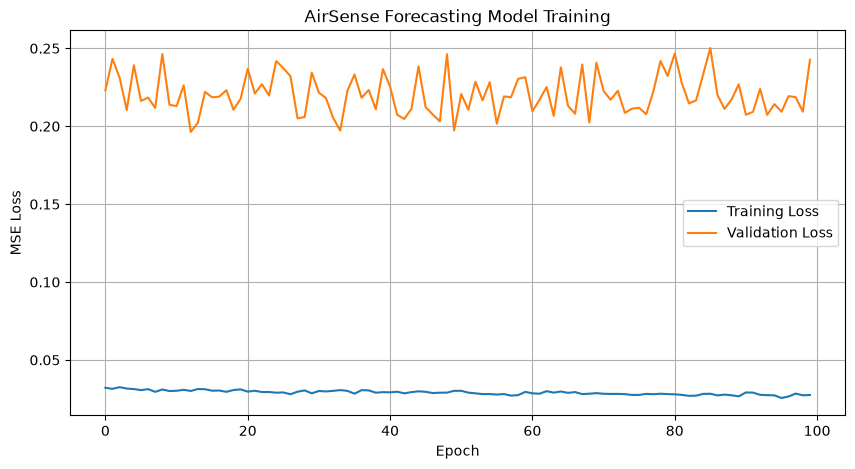

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    forecast_train_losses,
    label="Training Loss"
)

plt.plot(
    forecast_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("AirSense Forecasting Model Training")

plt.legend()
plt.grid(True)

plt.show()

In [111]:
# Load the best saved forecasting model

forecast_model.load_state_dict(
    torch.load(
        "airsense_forecast_best.pt",
        map_location=device
    )
)

forecast_model.eval()

print("Best forecasting model loaded successfully!")
print("Best validation loss:", best_forecast_val_loss)

Best forecasting model loaded successfully!
Best validation loss: 0.1963421995441119


In [112]:
# Generate predictions on test data

test_X = forecast_tensors["test"]["X"]
test_y = forecast_tensors["test"]["y"]

forecast_model.eval()

with torch.no_grad():
    test_predictions = forecast_model(test_X)

print("Test predictions generated successfully!")
print("Actual values shape:", test_y.shape)
print("Predicted values shape:", test_predictions.shape)

print("\nSample predicted values:")
print(test_predictions[:3].cpu().numpy())

print("\nSample actual values:")
print(test_y[:3].cpu().numpy())

Test predictions generated successfully!
Actual values shape: torch.Size([1237, 12])
Predicted values shape: torch.Size([1237, 12])

Sample predicted values:
[[-0.36985838 -0.96555066 -0.8060193  -0.86665297  0.32723418  0.5045777
   0.8781193  -2.4449873  -0.48215383 -1.9738866  -0.26444772 -2.085989  ]
 [-0.7247198  -1.1562182  -1.0912049  -1.2565408  -0.07776928  0.95271456
   0.42093647 -2.6253848  -0.77668643 -2.0322576  -0.11590962 -2.1035988 ]
 [-0.71552026 -0.893804   -0.9608199  -1.0495806   0.1053035   0.67418545
   0.59075296 -2.4860957  -0.53700167 -2.1156716   0.05525862 -2.0762308 ]]

Sample actual values:
[[-0.65570605 -1.0910391  -1.0890852  -1.2253554   0.1926946   0.6609753
   1.1849084  -2.5394409  -0.6572519  -1.8621166  -0.28398776 -2.0398612 ]
 [-0.8594357  -1.1135601  -1.1411731  -1.3242087  -0.16939953  0.8176494
   0.51691866 -2.5839424  -0.7941414  -1.9492166  -0.14331983 -2.01543   ]
 [-0.65570605 -0.9063669  -0.97188765 -1.0632359   0.06716864  0.425964
   0

In [114]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Convert tensors into NumPy arrays
actual = test_y.cpu().numpy()
predicted = test_predictions.cpu().numpy()

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)

mse = mean_squared_error(actual, predicted)

rmse = np.sqrt(mse)

print("AIRSENSE MODEL EVALUATION")
print("-------------------------")
print("MAE:", round(mae, 6))
print("MSE:", round(mse, 6))
print("RMSE:", round(rmse, 6))

ModuleNotFoundError: No module named 'sklearn'

In [115]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 357.1 kB/s eta 0:00:22
   -- ------------------------------------- 0.5/8.4 MB 357.1 kB/s eta 0:00:22
   -- ------------------------------------- 0.5/8.4 MB 357.1 kB/s eta 0:00:22
   -- ------------------------------------- 0.5/8.4 MB 357.1 kB/s eta 0:00:22
   --- ------------------------------------ 0.8/8.4 MB 337.1 kB/s eta 0:00:23
   --- ------------------------------------ 0.8/8.4 MB 337


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Convert tensors into NumPy arrays
actual = test_y.cpu().numpy()
predicted = test_predictions.cpu().numpy()

# Calculate metrics
mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)

print("AIRSENSE MODEL EVALUATION")
print("-------------------------")
print("MAE:", round(mae, 6))
print("MSE:", round(mse, 6))
print("RMSE:", round(rmse, 6))

AIRSENSE MODEL EVALUATION
-------------------------
MAE: 0.348476
MSE: 0.21488
RMSE: 0.463552


In [117]:
# Persistence baseline:
# Predict the next hour using the last observed hour.

baseline_predictions = test_X[:, -1, :]

baseline_mae = mean_absolute_error(
    actual, baseline_predictions.cpu().numpy()
)

baseline_mse = mean_squared_error(
    actual, baseline_predictions.cpu().numpy()
)

baseline_rmse = np.sqrt(baseline_mse)

print("BASELINE EVALUATION")
print("-------------------")
print("MAE:", round(baseline_mae, 6))
print("MSE:", round(baseline_mse, 6))
print("RMSE:", round(baseline_rmse, 6))

BASELINE EVALUATION
-------------------
MAE: 0.276956
MSE: 0.182038
RMSE: 0.426659


In [118]:
mae_difference = mae - baseline_mae
rmse_difference = rmse - baseline_rmse

mae_percentage = (
    (mae - baseline_mae) / baseline_mae
) * 100

rmse_percentage = (
    (rmse - baseline_rmse) / baseline_rmse
) * 100

print("MODEL VS BASELINE COMPARISON")
print("----------------------------")

print("MAE difference:", round(mae_difference, 6))
print("RMSE difference:", round(rmse_difference, 6))

print("Transformer MAE is", round(mae_percentage, 2),
      "% higher than baseline.")

print("Transformer RMSE is", round(rmse_percentage, 2),
      "% higher than baseline.")


MODEL VS BASELINE COMPARISON
----------------------------
MAE difference: 0.07152
RMSE difference: 0.036893
Transformer MAE is 25.82 % higher than baseline.
Transformer RMSE is 8.65 % higher than baseline.


In [119]:
feature_names = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "Temperature",
    "Relative Humidity",
    "Absolute Humidity"
]

transformer_feature_mae = np.mean(
    np.abs(actual - predicted), axis=0
)

baseline_feature_mae = np.mean(
    np.abs(actual - baseline_predictions.cpu().numpy()),
    axis=0
)

print("FEATURE-WISE MAE COMPARISON")
print("-" * 65)

for i, name in enumerate(feature_names):

    print(
        f"{name:20s} | "
        f"Transformer: {transformer_feature_mae[i]:.4f} | "
        f"Baseline: {baseline_feature_mae[i]:.4f}"
    )

FEATURE-WISE MAE COMPARISON
-----------------------------------------------------------------
CO(GT)               | Transformer: 0.4170 | Baseline: 0.3495
PT08.S1(CO)          | Transformer: 0.3392 | Baseline: 0.2873
C6H6(GT)             | Transformer: 0.3699 | Baseline: 0.3065
PT08.S2(NMHC)        | Transformer: 0.4637 | Baseline: 0.3489
NOx(GT)              | Transformer: 0.4485 | Baseline: 0.3336
PT08.S3(NOx)         | Transformer: 0.3289 | Baseline: 0.2762
NO2(GT)              | Transformer: 0.5123 | Baseline: 0.4446
PT08.S4(NO2)         | Transformer: 0.3516 | Baseline: 0.2731
PT08.S5(O3)          | Transformer: 0.4066 | Baseline: 0.3388
Temperature          | Transformer: 0.1753 | Baseline: 0.1170
Relative Humidity    | Transformer: 0.2340 | Baseline: 0.1905
Absolute Humidity    | Transformer: 0.1347 | Baseline: 0.0576


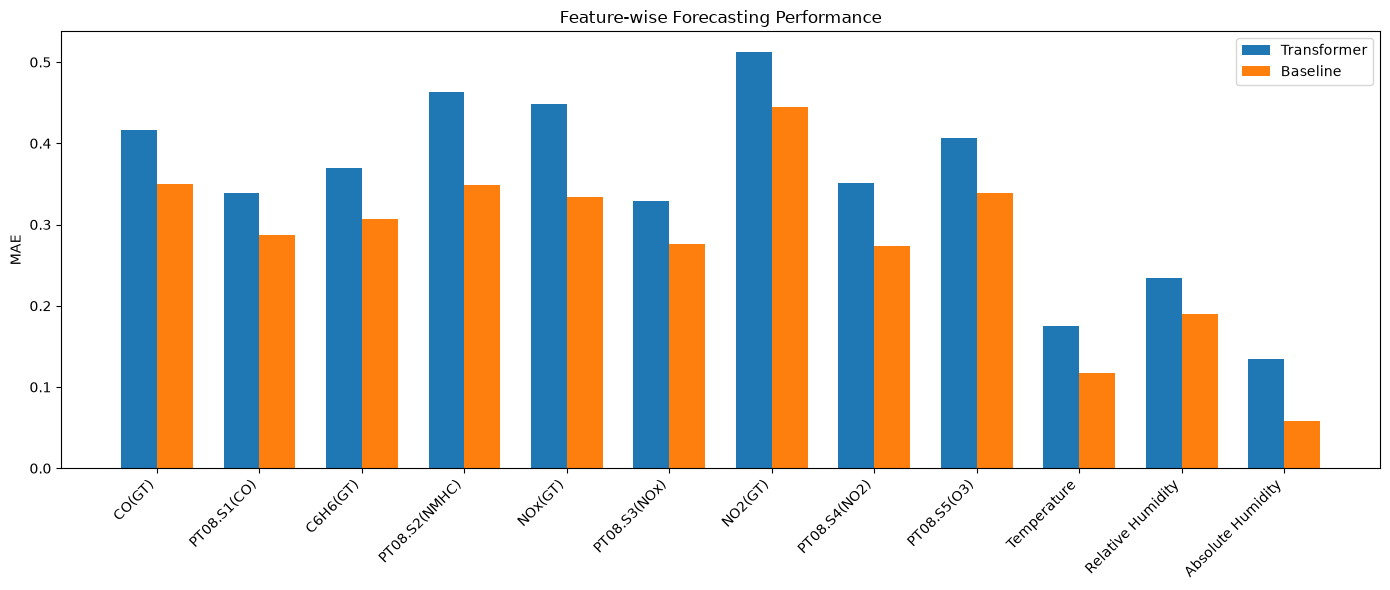

In [120]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(feature_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    transformer_feature_mae,
    width,
    label="Transformer"
)

plt.bar(
    x + width/2,
    baseline_feature_mae,
    width,
    label="Baseline"
)

plt.xticks(x, feature_names, rotation=45, ha="right")
plt.ylabel("MAE")
plt.title("Feature-wise Forecasting Performance")
plt.legend()
plt.tight_layout()
plt.show()


In [121]:
# Load normalization values
mean_values = np.load("data/processed/normalized/mean.npy")
std_values = np.load("data/processed/normalized/std.npy")

# Convert normalized predictions and actual values
predicted_original = predicted * std_values + mean_values
actual_original = actual * std_values + mean_values

print("Original measurement values restored!")

print("\nSample predicted readings:")
print(np.round(predicted_original[:3], 3))

print("\nSample actual readings:")
print(np.round(actual_original[:3], 3))

Original measurement values restored!

Sample predicted readings:
[[1.921000e+00 9.398600e+02 6.474000e+00 8.207160e+02 3.018670e+02
  9.230640e+02 1.446000e+02 9.205920e+02 8.900720e+02 6.802000e+00
  3.934700e+01 3.940000e-01]
 [1.398000e+00 8.975290e+02 4.284000e+00 7.221130e+02 2.179790e+02
  1.026035e+03 1.261200e+02 8.678940e+02 7.738860e+02 6.333000e+00
  4.198700e+01 3.880000e-01]
 [1.412000e+00 9.557890e+02 5.285000e+00 7.744530e+02 2.558990e+02
  9.620350e+02 1.329840e+02 9.085830e+02 8.684360e+02 5.662000e+00
  4.502900e+01 3.980000e-01]]

Sample actual readings:
[[1.50e+00 9.12e+02 4.30e+00 7.30e+02 2.74e+02 9.59e+02 1.57e+02 8.93e+02
  8.21e+02 7.70e+00 3.90e+01 4.11e-01]
 [1.20e+00 9.07e+02 3.90e+00 7.05e+02 1.99e+02 9.95e+02 1.30e+02 8.80e+02
  7.67e+02 7.00e+00 4.15e+01 4.19e-01]
 [1.50e+00 9.53e+02 5.20e+00 7.71e+02 2.48e+02 9.05e+02 1.45e+02 9.36e+02
  8.95e+02 6.60e+00 4.26e+01 4.18e-01]]


In [122]:
# Calculate errors in original measurement units

original_mae = np.mean(
    np.abs(actual_original - predicted_original),
    axis=0
)

original_rmse = np.sqrt(
    np.mean(
        (actual_original - predicted_original) ** 2,
        axis=0
    )
)

print("ORIGINAL UNIT EVALUATION")
print("-" * 65)

for i, name in enumerate(feature_names):

    print(
        f"{name:20s} | "
        f"MAE: {original_mae[i]:.4f} | "
        f"RMSE: {original_rmse[i]:.4f}"
    )

ORIGINAL UNIT EVALUATION
-----------------------------------------------------------------
CO(GT)               | MAE: 0.6140 | RMSE: 0.7841
PT08.S1(CO)          | MAE: 75.3127 | RMSE: 98.6361
C6H6(GT)             | MAE: 2.8408 | RMSE: 3.7675
PT08.S2(NMHC)        | MAE: 117.2605 | RMSE: 143.6798
NOx(GT)              | MAE: 92.8881 | RMSE: 115.9422
PT08.S3(NOx)         | MAE: 75.5823 | RMSE: 95.0594
NO2(GT)              | MAE: 20.7060 | RMSE: 26.2932
PT08.S4(NO2)         | MAE: 102.7134 | RMSE: 130.9933
PT08.S5(O3)          | MAE: 160.4139 | RMSE: 198.5379
Temperature          | MAE: 1.4085 | RMSE: 1.7906
Relative Humidity    | MAE: 4.1591 | RMSE: 5.3475
Absolute Humidity    | MAE: 0.0480 | RMSE: 0.0637


In [123]:
import pandas as pd
import os

results = pd.DataFrame({
    "Feature": feature_names,
    "MAE": original_mae,
    "RMSE": original_rmse
})

os.makedirs("evaluation", exist_ok=True)

results.to_csv(
    "evaluation/forecasting_original_unit_metrics.csv",
    index=False
)

print("Evaluation results saved successfully!")
print(results)

Evaluation results saved successfully!
              Feature         MAE        RMSE
0              CO(GT)    0.614038    0.784098
1         PT08.S1(CO)   75.312729   98.636131
2            C6H6(GT)    2.840754    3.767542
3       PT08.S2(NMHC)  117.260475  143.679794
4             NOx(GT)   92.888077  115.942245
5        PT08.S3(NOx)   75.582321   95.059380
6             NO2(GT)   20.706018   26.293224
7        PT08.S4(NO2)  102.713387  130.993347
8         PT08.S5(O3)  160.413940  198.537918
9         Temperature    1.408458    1.790567
10  Relative Humidity    4.159099    5.347534
11  Absolute Humidity    0.047972    0.063689


In [124]:
import torch

# Load the best formatted SLM checkpoint
checkpoint = torch.load(
    "airsense_formatted_best.pt",
    map_location="cpu"
)

print("Checkpoint loaded successfully!")
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Available checkpoint keys:", checkpoint.keys())

Checkpoint loaded successfully!
Checkpoint type: <class 'collections.OrderedDict'>
Available checkpoint keys: odict_keys(['tok_emb.weight', 'blocks.0.attention.W_query.weight', 'blocks.0.attention.W_key.weight', 'blocks.0.attention.W_value.weight', 'blocks.0.attention.out_proj.weight', 'blocks.0.attention.q_norm.weight', 'blocks.0.attention.k_norm.weight', 'blocks.0.feed_forward.gate_proj.weight', 'blocks.0.feed_forward.up_proj.weight', 'blocks.0.feed_forward.down_proj.weight', 'blocks.0.norm1.weight', 'blocks.0.norm2.weight', 'blocks.1.attention.W_query.weight', 'blocks.1.attention.W_key.weight', 'blocks.1.attention.W_value.weight', 'blocks.1.attention.out_proj.weight', 'blocks.1.attention.q_norm.weight', 'blocks.1.attention.k_norm.weight', 'blocks.1.feed_forward.gate_proj.weight', 'blocks.1.feed_forward.up_proj.weight', 'blocks.1.feed_forward.down_proj.weight', 'blocks.1.norm1.weight', 'blocks.1.norm2.weight', 'blocks.2.attention.W_query.weight', 'blocks.2.attention.W_key.weight', 'b

In [125]:
print("Available model-related variables:")

for name in globals():
    if any(word in name.lower() for word in [
        "model", "tokenizer", "vocab", "stoi", "itos", "config"
    ]):
        print(name, ":", type(globals()[name]))

Available model-related variables:
AutoTokenizer : <class 'type'>
tokenizer : <class 'transformers.models.qwen2.tokenization_qwen2.Qwen2Tokenizer'>
Qwen3Model : <class 'type'>
QWEN3_CONFIG : <class 'dict'>
model : <class '__main__.Qwen3Model'>
best_model_params_path : <class 'str'>
vocab : <class 'list'>
stoi : <class 'dict'>
itos : <class 'dict'>
CUSTOM_CONFIG : <class 'dict'>
custom_model : <class '__main__.Qwen3Model'>
model_size_mb : <class 'float'>
new_vocab : <class 'list'>
new_stoi : <class 'dict'>
new_itos : <class 'dict'>
NEW_CONFIG : <class 'dict'>
new_custom_model : <class '__main__.Qwen3Model'>
FORMATTED_CONFIG : <class 'dict'>
formatted_model : <class '__main__.Qwen3Model'>
forecast_model : <class '__main__.AirSenseTransformer'>


In [126]:
# Load trained weights into the formatted model

formatted_model.load_state_dict(checkpoint)

formatted_model.eval()

print("Formatted SLM loaded successfully!")

print("Vocabulary size:", len(new_vocab))
print("Model configuration:", FORMATTED_CONFIG)
print("Model is ready for text generation!")

Formatted SLM loaded successfully!
Vocabulary size: 66
Model configuration: {'vocab_size': 66, 'd_model': 128, 'n_heads': 4, 'n_kv_groups': 2, 'n_layers': 4, 'd_ff': 512, 'max_seq_len': 900, 'dtype': torch.float32}
Model is ready for text generation!


In [128]:
print("Generation-related functions:")

for name, obj in globals().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["generate", "decode", "encode"]
    ):
        print(name)

Generation-related functions:
encode
decode
new_encode
new_decode


In [129]:
print("Methods available in formatted_model:")

for name in dir(formatted_model):
    if "generate" in name.lower() or "forward" in name.lower():
        print(name)

Methods available in formatted_model:
_forward_hooks
_forward_hooks_always_called
_forward_hooks_with_kwargs
_forward_pre_hooks
_forward_pre_hooks_with_kwargs
_slow_forward
forward
generate
register_forward_hook
register_forward_pre_hook


In [130]:
import inspect

print(inspect.signature(formatted_model.generate))


(idx, max_new_tokens, temperature=1.0, top_k=None)


In [131]:
# Create a test prompt
prompt = "<FORECAST> <PREVIOUS> CO(GT): 1.5, Temperature: 25.0, Relative Humidity: 60.0 <NEXT>"

# Convert prompt into token IDs
encoded_prompt = new_encode(prompt)

# Convert to PyTorch tensor
context = torch.tensor(
    encoded_prompt,
    dtype=torch.long
).unsqueeze(0)

# Generate text
formatted_model.eval()

with torch.no_grad():
    generated = formatted_model.generate(
        context,
        max_new_tokens=100,
        temperature=0.8,
        top_k=10
    )

# Decode generated tokens
generated_text = new_decode(generated[0].tolist())

print("AIRSense GENERATED RESPONSE:")
print("-" * 50)
print(generated_text)

AIRSense GENERATED RESPONSE:
--------------------------------------------------
<FORECAST> <PREVIOUS> CO<UNK><UNK>T<UNK>: 1.5, Temperature: 25.0, Relative Humidity: 60.0 <NEXT>a61, PT08_S40.81.81.2675, PT08_S43, |58882, Humidityl=-0.1.50.8, PT08_S1=-0, CO=-1.862888.0.8, PT08_S3=-0., PT08_S3=1.62.77660, PT08_S4=.6.2, Absolute_Humidity=


In [132]:
print("Checking formatted training data...")

print("formatted_train exists:", "formatted_train" in globals())

if "formatted_train" in globals():
    print("Data type:", type(formatted_train))
    print("Number of training examples:", len(formatted_train))
    print("\nFirst training example:\n")
    print(formatted_train[0])
    

Checking formatted training data...
formatted_train exists: False


In [133]:
print("Searching for training-data variables...\n")

for name, value in list(globals().items()):
    if any(word in name.lower() for word in [
        "train", "formatted", "text", "encoded"
    ]):
        print(name, ":", type(value))

Searching for training-data variables...

create_text_dataset : <class 'function'>
nullcontext : <class 'abc.ABCMeta'>
train_loss_list : <class 'list'>
context : <class 'torch.Tensor'>
all_text : <class 'str'>
sample_text : <class 'str'>
encoded_text : <class 'list'>
decoded_text : <class 'str'>
encoded_examples : <class 'list'>
train_losses : <class 'list'>
generated_text : <class 'str'>
train_losses_extended : <class 'list'>
encoded : <class 'list'>
new_train_losses : <class 'list'>
formatted_data : <class 'dict'>
text : <class 'str'>
formatted_tokenized_data : <class 'dict'>
formatted_padded_data : <class 'dict'>
get_formatted_batch : <class 'function'>
FORMATTED_CONFIG : <class 'dict'>
formatted_model : <class '__main__.Qwen3Model'>
calculate_formatted_loss : <class 'function'>
formatted_learning_rate : <class 'float'>
formatted_max_iters : <class 'int'>
formatted_batch_size : <class 'int'>
formatted_gradient_accumulation : <class 'int'>
formatted_eval_interval : <class 'int'>
form

In [134]:
print("Formatted data structure:")
print(formatted_data.keys())

print("\nFirst training example:\n")

print(formatted_data["train"][0])

Formatted data structure:
dict_keys(['train', 'validation', 'test'])

First training example:

<FORECAST> <PREVIOUS> CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016, Temperature=-1.340, Humidity=0.560, Absolute_Humidity=-1.086 | CO=-0.180, PT08_S1=0.999, C6H6=-0.451, PT08_S2=-0.363, NOx=-0.300, PT08_S3=1.240, NO2=0.319, PT08_S4=-0.174, PT08_S5=0.311, Temperature=-1.452, Humidity=0.898, Absolute_Humidity=-0.984 | CO=-0.588, PT08_S1=0.530, C6H6=-0.803, PT08_S2=-0.806, NOx=-0.498, PT08_S3=1.732, NO2=0.171, PT08_S4=-0.496, PT08_S5=0.075, Temperature

In [135]:
# Encode the first training example
sample = formatted_data["train"][0]

tokens = new_encode(sample)

print("Original text length:", len(sample))
print("Number of tokens:", len(tokens))

print("\nFirst 100 token IDs:")
print(tokens[:100])

print("\nDecoded text:")
print(new_decode(tokens))

Original text length: 1339
Number of tokens: 819

First 100 token IDs:
[2, 21, 3, 21, 16, 17, 24, 23, 24, 33, 25, 18, 21, 8, 17, 24, 23, 33, 26, 31, 18, 21, 13, 17, 22, 24, 23, 24, 33, 33, 18, 21, 9, 17, 24, 23, 24, 26, 28, 18, 21, 14, 17, 22, 24, 23, 27, 26, 33, 18, 21, 10, 17, 25, 23, 24, 32, 27, 18, 21, 15, 17, 24, 23, 24, 33, 30, 18, 21, 11, 17, 24, 23, 25, 33, 30, 18, 21, 12, 17, 24, 23, 28, 31, 30, 18, 21, 6, 17, 22, 25, 23, 25, 26, 32, 18, 21, 7, 17, 24]

Decoded text:
<FORECAST> <PREVIOUS> CO=0.091, PT08_S1=0.927, C6H6=-0.099, PT08_S2=0.024, NOx=-0.329, PT08_S3=1.083, NO2=0.096, PT08_S4=0.196, PT08_S5=0.476, Temperature=-1.128, Humidity=0.273, Absolute_Humidity=-1.065 | CO=-0.316, PT08_S1=0.621, C6H6=-0.425, PT08_S2=-0.336, NOx=-0.633, PT08_S3=1.597, NO2=-0.423, PT08_S4=-0.260, PT08_S5=-0.274, Temperature=-1.165, Humidity=0.206, Absolute_Humidity=-1.156 | CO=-0.180, PT08_S1=1.116, C6H6=-0.477, PT08_S2=-0.399, NOx=-0.498, PT08_S3=1.449, NO2=0.121, PT08_S4=-0.273, PT08_S5=-0.016,

In [136]:
print("FORMATTED SLM TRAINING RESULTS")
print("-" * 45)

print("Training loss entries:", len(formatted_train_losses))
print("Validation loss entries:", len(formatted_val_losses))

print("\nFinal training loss:", formatted_train_losses[-1])
print("Final validation loss:", formatted_val_losses[-1])

print("\nBest validation loss:", formatted_best_val_loss)

FORMATTED SLM TRAINING RESULTS
---------------------------------------------
Training loss entries: 5
Validation loss entries: 5

Final training loss: 1.934679126739502
Final validation loss: 1.9683971405029297

Best validation loss: 1.9683971405029297


In [139]:
with torch.no_grad():
    model_output = formatted_model(input_ids)

print("Output type:", type(model_output))
print("Number of elements:", len(model_output))

for i, item in enumerate(model_output):
    print(f"Element {i} type:", type(item))

    if isinstance(item, torch.Tensor):
        print("Shape:", item.shape)

Output type: <class 'tuple'>
Number of elements: 2
Element 0 type: <class 'torch.Tensor'>
Shape: torch.Size([1, 818, 66])
Element 1 type: <class 'NoneType'>


In [140]:
# Get prediction scores
with torch.no_grad():
    model_output = formatted_model(input_ids)
    logits = model_output[0]

# Find the most likely next token
predicted_ids = torch.argmax(logits, dim=-1)

# Calculate accuracy
accuracy = (
    (predicted_ids == target_ids).float().mean().item()
) * 100

print("Training example next-token accuracy:", round(accuracy, 2), "%")

Training example next-token accuracy: 50.12 %


In [141]:
sample = formatted_data["validation"][0]
tokens = new_encode(sample)

input_ids = torch.tensor(
    tokens[:-1], dtype=torch.long
).unsqueeze(0)

target_ids = torch.tensor(
    tokens[1:], dtype=torch.long
).unsqueeze(0)

formatted_model.eval()

with torch.no_grad():
    logits = formatted_model(input_ids)[0]
    predicted_ids = torch.argmax(logits, dim=-1)

accuracy = (
    (predicted_ids == target_ids).float().mean().item()
) * 100

print("Validation next-token accuracy:", round(accuracy, 2), "%")

Validation next-token accuracy: 51.65 %


In [142]:
# Select a real training example
sample = formatted_data["train"][0]

# Keep the six previous readings as the prompt
prefix = sample.split("<NEXT>")[0] + "<NEXT>"

# Encode the prompt
prefix_tokens = new_encode(prefix)

print("Prompt token count:", len(prefix_tokens))
print("Available model context:", FORMATTED_CONFIG["max_seq_len"])
print("\nPrompt ending:")
print(prefix[-200:])

Prompt token count: 703
Available model context: 900

Prompt ending:
78 | CO=-0.859, PT08_S1=0.193, C6H6=-1.037, PT08_S2=-1.146, NOx=-0.700, PT08_S3=2.306, NO2=-0.324, PT08_S4=-0.828, PT08_S5=-0.333, Temperature=-1.427, Humidity=0.853, Absolute_Humidity=-0.989 | <NEXT>


In [143]:
# Convert the real training prompt into tokens
context = torch.tensor(
    prefix_tokens,
    dtype=torch.long
).unsqueeze(0)

# Generate the next reading
formatted_model.eval()

with torch.no_grad():
    generated = formatted_model.generate(
        context,
        max_new_tokens=100,
        temperature=0.8,
        top_k=10
    )

# Decode the generated sequence
generated_text = new_decode(generated[0].tolist())

print("GENERATED OUTPUT:")
print(generated_text[len(prefix):])

GENERATED OUTPUT:
5 PT08_S2=0.2462=1.892, CO=-1.5, PT08_S406.6812.2=-0.0.4, NO2=-0.1, CO0.611.6, Absolute_Humidity=-0.6 Humidity=-020.6, PT08_S4=0.7, NOx=-0., NOx=-0.8


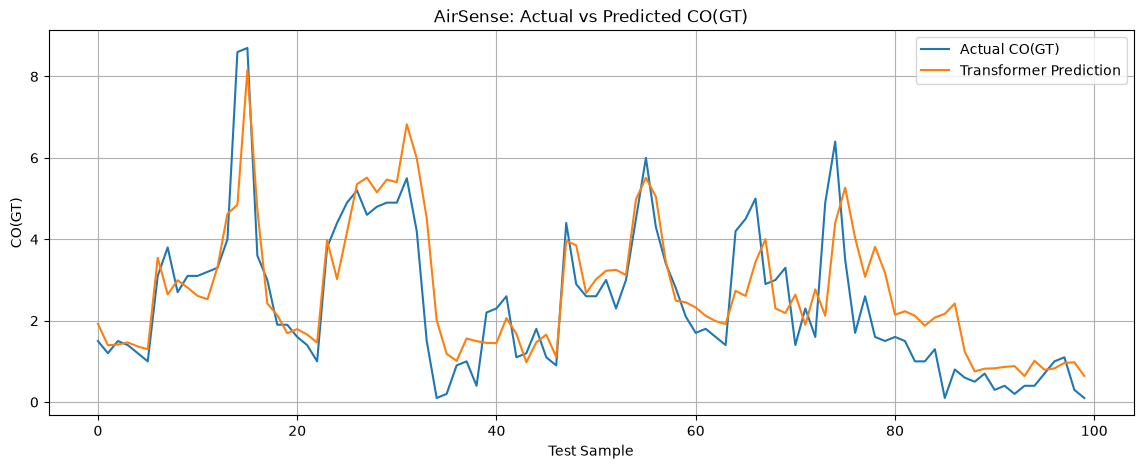

In [144]:
import matplotlib.pyplot as plt

# Select CO(GT), the first feature
feature_index = 0

# Compare the first 100 test samples
plt.figure(figsize=(14, 5))

plt.plot(
    actual_original[:100, feature_index],
    label="Actual CO(GT)"
)

plt.plot(
    predicted_original[:100, feature_index],
    label="Transformer Prediction"
)

plt.title("AirSense: Actual vs Predicted CO(GT)")
plt.xlabel("Test Sample")
plt.ylabel("CO(GT)")
plt.legend()
plt.grid(True)

plt.show()

In [145]:
print("ACTUAL AND PREDICTED DATA CHECK")
print("-" * 40)

print("Actual normalized shape:", actual.shape)
print("Predicted normalized shape:", predicted.shape)

print("\nActual original shape:", actual_original.shape)
print("Predicted original shape:", predicted_original.shape)

print("\nFeature names:")
print(feature_names)

print("\nFirst 5 actual CO(GT) values:")
print(actual_original[:5, 0])

print("\nFirst 5 predicted CO(GT) values:")
print(predicted_original[:5, 0])

ACTUAL AND PREDICTED DATA CHECK
----------------------------------------
Actual normalized shape: (1237, 12)
Predicted normalized shape: (1237, 12)

Actual original shape: (1237, 12)
Predicted original shape: (1237, 12)

Feature names:
['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'Temperature', 'Relative Humidity', 'Absolute Humidity']

First 5 actual CO(GT) values:
[1.5 1.2 1.5 1.4 1.2]

First 5 predicted CO(GT) values:
[1.920922  1.3983746 1.4119213 1.465479  1.3657405]


In [146]:
print("INVERSE NORMALIZATION CHECK")
print("-" * 40)

print("CO(GT) mean:", mean_values[0])
print("CO(GT) standard deviation:", std_values[0])

print("\nFirst 5 normalized actual values:")
print(actual[:5, 0])

print("\nFirst 5 reconstructed actual values:")
print(actual[:5, 0] * std_values[0] + mean_values[0])

print("\nFirst 5 stored original actual values:")
print(actual_original[:5, 0])

INVERSE NORMALIZATION CHECK
----------------------------------------
CO(GT) mean: 2.4655533
CO(GT) standard deviation: 1.4725398

First 5 normalized actual values:
[-0.65570605 -0.8594357  -0.65570605 -0.72361594 -0.8594357 ]

First 5 reconstructed actual values:
[1.5 1.2 1.5 1.4 1.2]

First 5 stored original actual values:
[1.5 1.2 1.5 1.4 1.2]


In [147]:
print("PREDICTED VALUE RECONSTRUCTION CHECK")
print("-" * 45)

reconstructed_predictions = (
    predicted[:, 0] * std_values[0] + mean_values[0]
)

print("First 5 reconstructed predictions:")
print(reconstructed_predictions[:5])

print("\nFirst 5 stored original predictions:")
print(predicted_original[:5, 0])

print("\nMaximum absolute difference:")

print(
    np.max(
        np.abs(
            reconstructed_predictions - predicted_original[:, 0]
        )
    )
)

PREDICTED VALUE RECONSTRUCTION CHECK
---------------------------------------------
First 5 reconstructed predictions:
[1.920922  1.3983746 1.4119213 1.465479  1.3657405]

First 5 stored original predictions:
[1.920922  1.3983746 1.4119213 1.465479  1.3657405]

Maximum absolute difference:
0.0


In [148]:
print("TEST DATA ALIGNMENT CHECK")
print("-" * 40)

print("First 5 test input sequences:")

for i in range(5):
    print(
        f"Sample {i+1}: "
        f"Last input CO = {forecast_tensors['test']['X'][i, -1, 0].item() * std_values[0] + mean_values[0]:.2f}, "
        f"Actual next CO = {actual_original[i, 0]:.2f}, "
        f"Predicted next CO = {predicted_original[i, 0]:.2f}"
    )

TEST DATA ALIGNMENT CHECK
----------------------------------------
First 5 test input sequences:
Sample 1: Last input CO = 2.20, Actual next CO = 1.50, Predicted next CO = 1.92
Sample 2: Last input CO = 1.50, Actual next CO = 1.20, Predicted next CO = 1.40
Sample 3: Last input CO = 1.20, Actual next CO = 1.50, Predicted next CO = 1.41
Sample 4: Last input CO = 1.50, Actual next CO = 1.40, Predicted next CO = 1.47
Sample 5: Last input CO = 1.40, Actual next CO = 1.20, Predicted next CO = 1.37


In [150]:
print("EVALUATION CONSISTENCY CHECK")
print("-" * 45)

print("Actual test shape:", actual.shape)
print("Transformer predictions shape:", predicted.shape)
print("Baseline predictions shape:", baseline_predictions.shape)

print("\nChecking for missing or infinite values:")

print("Actual:", np.isfinite(actual).all())
print("Transformer:", np.isfinite(predicted).all())
print("Baseline:", np.isfinite(baseline_predictions).all())

print("\nFeature count:", len(feature_names))
print("Actual feature count:", actual.shape[1])

EVALUATION CONSISTENCY CHECK
---------------------------------------------
Actual test shape: (1237, 12)
Transformer predictions shape: (1237, 12)
Baseline predictions shape: torch.Size([1237, 12])

Checking for missing or infinite values:
Actual: True
Transformer: True
Baseline: tensor(1, dtype=torch.uint8)

Feature count: 12
Actual feature count: 12


C:\Users\malav\AppData\Local\Temp\ipykernel_18572\2948587194.py:12: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print("Baseline:", np.isfinite(baseline_predictions).all())


In [151]:
baseline_predictions = baseline_predictions.cpu().numpy()

print("Baseline converted successfully!")
print("Shape:", baseline_predictions.shape)
print("Data type:", type(baseline_predictions))

Baseline converted successfully!
Shape: (1237, 12)
Data type: <class 'numpy.ndarray'>


In [152]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Transformer metrics
transformer_mae = mean_absolute_error(actual, predicted)
transformer_mse = mean_squared_error(actual, predicted)
transformer_rmse = np.sqrt(transformer_mse)

# Baseline metrics
baseline_mae = mean_absolute_error(actual, baseline_predictions)
baseline_mse = mean_squared_error(actual, baseline_predictions)
baseline_rmse = np.sqrt(baseline_mse)

print("FINAL MODEL COMPARISON")
print("-" * 50)

print(f"{'Metric':<12} {'Transformer':<15} {'Baseline':<15}")
print("-" * 50)

print(f"{'MAE':<12} {transformer_mae:<15.6f} {baseline_mae:<15.6f}")
print(f"{'MSE':<12} {transformer_mse:<15.6f} {baseline_mse:<15.6f}")
print(f"{'RMSE':<12} {transformer_rmse:<15.6f} {baseline_rmse:<15.6f}")

FINAL MODEL COMPARISON
--------------------------------------------------
Metric       Transformer     Baseline       
--------------------------------------------------
MAE          0.348476        0.276956       
MSE          0.214880        0.182038       
RMSE         0.463552        0.426659       


In [153]:
import pandas as pd
import os

comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE"],
    "Transformer": [
        transformer_mae,
        transformer_mse,
        transformer_rmse
    ],
    "Baseline": [
        baseline_mae,
        baseline_mse,
        baseline_rmse
    ]
})

os.makedirs("evaluation", exist_ok=True)

comparison.to_csv(
    "evaluation/final_model_comparison.csv",
    index=False
)

print(comparison)
print("\nResults saved successfully!")

  Metric  Transformer  Baseline
0    MAE     0.348476  0.276956
1    MSE     0.214880  0.182038
2   RMSE     0.463552  0.426659

Results saved successfully!


In [154]:
feature_mae_transformer = np.mean(
    np.abs(actual_original - predicted_original),
    axis=0
)

print("FEATURE-WISE TRANSFORMER MAE")
print("-" * 45)

for name, error in zip(feature_names, feature_mae_transformer):
    print(f"{name:<22}: {error:.4f}")

FEATURE-WISE TRANSFORMER MAE
---------------------------------------------
CO(GT)                : 0.6140
PT08.S1(CO)           : 75.3127
C6H6(GT)              : 2.8408
PT08.S2(NMHC)         : 117.2605
NOx(GT)               : 92.8881
PT08.S3(NOx)          : 75.5823
NO2(GT)               : 20.7060
PT08.S4(NO2)          : 102.7134
PT08.S5(O3)           : 160.4139
Temperature           : 1.4085
Relative Humidity     : 4.1591
Absolute Humidity     : 0.0480


In [155]:
print("AIRSENSE MODEL ARCHITECTURE")
print("-" * 45)

print(forecast_model)

print("\nTotal parameters:")

total_parameters = sum(
    p.numel() for p in forecast_model.parameters()
)

print(f"{total_parameters:,}")

AIRSENSE MODEL ARCHITECTURE
---------------------------------------------
AirSenseTransformer(
  (input_projection): Linear(in_features=12, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output_layer): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): GELU(app

In [157]:
print("FORECASTING TRAINING SETTINGS")
print("-" * 40)

print("Optimizer:", type(forecast_optimizer).__name__)

print("Learning rate:",
      forecast_optimizer.param_groups[0]["lr"])

print("Scheduler exists:",
      "scheduler" in globals())

print("Forecast epochs:", forecast_epochs)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

FORECASTING TRAINING SETTINGS
----------------------------------------
Optimizer: AdamW
Learning rate: 0.001
Scheduler exists: True
Forecast epochs: 100
Training batches: 100
Validation batches: 15


In [158]:
print("FORECAST OPTIMIZER CHECK")
print("-" * 40)

print("Forecast optimizer learning rate:",
      forecast_optimizer.param_groups[0]["lr"])

print("Forecast optimizer weight decay:",
      forecast_optimizer.param_groups[0]["weight_decay"])

print("Forecast optimizer type:",
      type(forecast_optimizer).__name__)

FORECAST OPTIMIZER CHECK
----------------------------------------
Forecast optimizer learning rate: 0.001
Forecast optimizer weight decay: 0.01
Forecast optimizer type: AdamW


In [159]:
import pandas as pd
import numpy as np
import os

# Experiment 2 settings
INPUT_WINDOW_12 = 12

features = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

# Create a separate folder for Experiment 2
os.makedirs("data/processed/sequences_12h", exist_ok=True)

for split in ["train", "validation", "test"]:

    df = pd.read_csv(f"data/processed/{split}_clean.csv")
    df["DateTime"] = pd.to_datetime(df["DateTime"])

    # Separate hourly segments to avoid crossing time gaps
    gap = df["DateTime"].diff() != pd.Timedelta(hours=1)
    df["segment"] = gap.cumsum()

    X_12 = []
    y_12 = []

    for _, group in df.groupby("segment"):

        values = group[features].values

        for i in range(len(values) - INPUT_WINDOW_12):

            X_12.append(values[i:i + INPUT_WINDOW_12])
            y_12.append(values[i + INPUT_WINDOW_12])

    X_12 = np.array(X_12, dtype=np.float32)
    y_12 = np.array(y_12, dtype=np.float32)

    np.save(
        f"data/processed/sequences_12h/{split}_X.npy",
        X_12
    )

    np.save(
        f"data/processed/sequences_12h/{split}_y.npy",
        y_12
    )

    print(f"\n{split.upper()}")
    print("Input shape:", X_12.shape)
    print("Target shape:", y_12.shape)
    print("Forecasting examples:", len(X_12))

print("\nExperiment 2: 12-hour sequences created!")


TRAIN
Input shape: (1914, 12, 12)
Target shape: (1914, 12)
Forecasting examples: 1914

VALIDATION
Input shape: (281, 12, 12)
Target shape: (281, 12)
Forecasting examples: 281

TEST
Input shape: (871, 12, 12)
Target shape: (871, 12)
Forecasting examples: 871

Experiment 2: 12-hour sequences created!


In [160]:
import numpy as np
import os

# Load the original training normalization statistics
mean_values = np.load("data/processed/normalized/mean.npy")
std_values = np.load("data/processed/normalized/std.npy")

os.makedirs("data/processed/normalized_12h", exist_ok=True)

for split in ["train", "validation", "test"]:

    X_12 = np.load(
        f"data/processed/sequences_12h/{split}_X.npy"
    )

    y_12 = np.load(
        f"data/processed/sequences_12h/{split}_y.npy"
    )

    # Apply the original training normalization statistics
    X_normalized_12 = (X_12 - mean_values) / std_values
    y_normalized_12 = (y_12 - mean_values) / std_values

    np.save(
        f"data/processed/normalized_12h/{split}_X.npy",
        X_normalized_12
    )

    np.save(
        f"data/processed/normalized_12h/{split}_y.npy",
        y_normalized_12
    )

    print(f"\n{split.upper()}")
    print("Normalized input:", X_normalized_12.shape)
    print("Normalized target:", y_normalized_12.shape)

print("\n12-hour normalization completed!")


TRAIN
Normalized input: (1914, 12, 12)
Normalized target: (1914, 12)

VALIDATION
Normalized input: (281, 12, 12)
Normalized target: (281, 12)

TEST
Normalized input: (871, 12, 12)
Normalized target: (871, 12)

12-hour normalization completed!


In [161]:
import numpy as np

print("EXPERIMENT 2 DATA VERIFICATION")
print("-" * 40)

for split in ["train", "validation", "test"]:

    X = np.load(
        f"data/processed/normalized_12h/{split}_X.npy"
    )

    y = np.load(
        f"data/processed/normalized_12h/{split}_y.npy"
    )

    print(f"\n{split.upper()}")

    print("X shape:", X.shape)
    print("y shape:", y.shape)

    print("X contains NaN:", np.isnan(X).any())
    print("y contains NaN:", np.isnan(y).any())

    print("X contains infinity:", np.isinf(X).any())
    print("y contains infinity:", np.isinf(y).any())

print("\nVerification completed!")

EXPERIMENT 2 DATA VERIFICATION
----------------------------------------

TRAIN
X shape: (1914, 12, 12)
y shape: (1914, 12)
X contains NaN: False
y contains NaN: False
X contains infinity: False
y contains infinity: False

VALIDATION
X shape: (281, 12, 12)
y shape: (281, 12)
X contains NaN: False
y contains NaN: False
X contains infinity: False
y contains infinity: False

TEST
X shape: (871, 12, 12)
y shape: (871, 12)
X contains NaN: False
y contains NaN: False
X contains infinity: False
y contains infinity: False

Verification completed!


In [162]:
import torch
import numpy as np

# Load Experiment 2 normalized data
forecast_data_12h = {}

for split in ["train", "validation", "test"]:

    X = np.load(
        f"data/processed/normalized_12h/{split}_X.npy"
    )

    y = np.load(
        f"data/processed/normalized_12h/{split}_y.npy"
    )

    forecast_data_12h[split] = {
        "X": X,
        "y": y
    }

# Convert data into PyTorch tensors
forecast_tensors_12h = {}

for split in ["train", "validation", "test"]:

    forecast_tensors_12h[split] = {
        "X": torch.tensor(
            forecast_data_12h[split]["X"],
            dtype=torch.float32
        ),

        "y": torch.tensor(
            forecast_data_12h[split]["y"],
            dtype=torch.float32
        )
    }

    print(f"\n{split.upper()}")

    print("X:", forecast_tensors_12h[split]["X"].shape)
    print("y:", forecast_tensors_12h[split]["y"].shape)

print("\nExperiment 2 tensors prepared!")


TRAIN
X: torch.Size([1914, 12, 12])
y: torch.Size([1914, 12])

VALIDATION
X: torch.Size([281, 12, 12])
y: torch.Size([281, 12])

TEST
X: torch.Size([871, 12, 12])
y: torch.Size([871, 12])

Experiment 2 tensors prepared!


In [163]:
import torch
import torch.nn as nn

class AirSenseTransformer12h(nn.Module):

    def __init__(
        self,
        input_features=12,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        # Convert input features into embedding representation
        self.input_projection = nn.Linear(
            input_features, d_model
        )

        # Positional embedding for 12 time steps
        self.position_embedding = nn.Parameter(
            torch.randn(1, 12, d_model) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Prediction head
        self.output_layer = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Linear(64, input_features)
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = x + self.position_embedding

        x = self.transformer(x)

        # Use the final time step representation
        x = x[:, -1, :]

        return self.output_layer(x)


# Create Experiment 2 model
forecast_model_12h = AirSenseTransformer12h()

# CPU device
device = torch.device("cpu")
forecast_model_12h = forecast_model_12h.to(device)

# Count model parameters
total_parameters_12h = sum(
    p.numel() for p in forecast_model_12h.parameters()
)

print("EXPERIMENT 2 MODEL")
print("-" * 40)
print("Input window: 12 hours")
print("Input features:", 12)
print("Embedding dimension: 64")
print("Attention heads: 4")
print("Transformer layers: 2")
print("Total parameters:", total_parameters_12h)
print("Device:", device)

EXPERIMENT 2 MODEL
----------------------------------------
Input window: 12 hours
Input features: 12
Embedding dimension: 64
Attention heads: 4
Transformer layers: 2
Total parameters: 73484
Device: cpu


In [164]:
# Test the Experiment 2 model

sample_input = forecast_tensors_12h["train"]["X"][:1]

forecast_model_12h.eval()

with torch.no_grad():
    sample_output = forecast_model_12h(sample_input)

print("MODEL TEST")
print("-" * 40)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Expected output shape: (1, 12)")
print("Output contains NaN:", torch.isnan(sample_output).any().item())
print("Output contains infinity:", torch.isinf(sample_output).any().item())

MODEL TEST
----------------------------------------
Input shape: torch.Size([1, 12, 12])
Output shape: torch.Size([1, 12])
Expected output shape: (1, 12)
Output contains NaN: False
Output contains infinity: False


In [165]:
from torch.utils.data import TensorDataset, DataLoader

# Experiment 2 batch size
batch_size_12h = 32

# Create DataLoaders
train_dataset_12h = TensorDataset(
    forecast_tensors_12h["train"]["X"],
    forecast_tensors_12h["train"]["y"]
)

val_dataset_12h = TensorDataset(
    forecast_tensors_12h["validation"]["X"],
    forecast_tensors_12h["validation"]["y"]
)

test_dataset_12h = TensorDataset(
    forecast_tensors_12h["test"]["X"],
    forecast_tensors_12h["test"]["y"]
)

train_loader_12h = DataLoader(
    train_dataset_12h,
    batch_size=batch_size_12h,
    shuffle=True
)

val_loader_12h = DataLoader(
    val_dataset_12h,
    batch_size=batch_size_12h,
    shuffle=False
)

test_loader_12h = DataLoader(
    test_dataset_12h,
    batch_size=batch_size_12h,
    shuffle=False
)

print("EXPERIMENT 2 DATALOADERS")
print("-" * 40)
print("Batch size:", batch_size_12h)
print("Training batches:", len(train_loader_12h))
print("Validation batches:", len(val_loader_12h))
print("Testing batches:", len(test_loader_12h))

EXPERIMENT 2 DATALOADERS
----------------------------------------
Batch size: 32
Training batches: 60
Validation batches: 9
Testing batches: 28


In [166]:
import torch.nn as nn

# Experiment 2 training configuration

forecast_criterion_12h = nn.MSELoss()

forecast_optimizer_12h = torch.optim.AdamW(
    forecast_model_12h.parameters(),
    lr=0.001,
    weight_decay=0.01
)

forecast_epochs_12h = 100

print("EXPERIMENT 2 TRAINING CONFIGURATION")
print("-" * 40)
print("Loss function: MSELoss")
print("Optimizer: AdamW")
print("Learning rate:", 0.001)
print("Weight decay:", 0.01)
print("Epochs:", forecast_epochs_12h)
print("Model parameters:", total_parameters_12h)

EXPERIMENT 2 TRAINING CONFIGURATION
----------------------------------------
Loss function: MSELoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.01
Epochs: 100
Model parameters: 73484


In [168]:
import torch
import os

# Experiment 2 training

forecast_train_losses_12h = []
forecast_val_losses_12h = []

best_val_loss_12h = float("inf")

for epoch in range(forecast_epochs_12h):

    # Training phase
    forecast_model_12h.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader_12h:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        forecast_optimizer_12h.zero_grad()

        predictions = forecast_model_12h(X_batch)

        loss = forecast_criterion_12h(
            predictions, y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            forecast_model_12h.parameters(),
            max_norm=1.0
        )

        forecast_optimizer_12h.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(train_loader_12h)
    )

    forecast_train_losses_12h.append(avg_train_loss)

    # Validation phase
    forecast_model_12h.eval()
    total_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader_12h:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = forecast_model_12h(X_batch)

            loss = forecast_criterion_12h(
                predictions, y_batch
            )

            total_val_loss += loss.item()

    avg_val_loss = (
        total_val_loss / len(val_loader_12h)
    )

    forecast_val_losses_12h.append(avg_val_loss)

    # Save best model
    if avg_val_loss < best_val_loss_12h:

        best_val_loss_12h = avg_val_loss

        torch.save(
            forecast_model_12h.state_dict(),
            "airsense_forecast_12h_best.pt"
        )

    # Progress display
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{forecast_epochs_12h}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Validation Loss: {avg_val_loss:.6f}"
        )

# Save final model
torch.save(
    forecast_model_12h.state_dict(),
    "airsense_forecast_12h_final.pt"
)

print("\n12-hour forecasting training completed!")
print("Best validation loss:", best_val_loss_12h)

Epoch [10/100] Train Loss: 0.088573 Validation Loss: 0.166641
Epoch [20/100] Train Loss: 0.076462 Validation Loss: 0.166368
Epoch [30/100] Train Loss: 0.065297 Validation Loss: 0.159328
Epoch [40/100] Train Loss: 0.058329 Validation Loss: 0.182443
Epoch [50/100] Train Loss: 0.050291 Validation Loss: 0.196818
Epoch [60/100] Train Loss: 0.049151 Validation Loss: 0.187430
Epoch [70/100] Train Loss: 0.043409 Validation Loss: 0.186649
Epoch [80/100] Train Loss: 0.040837 Validation Loss: 0.205723
Epoch [90/100] Train Loss: 0.036933 Validation Loss: 0.178686
Epoch [100/100] Train Loss: 0.036400 Validation Loss: 0.191816

12-hour forecasting training completed!
Best validation loss: 0.14074933694468605


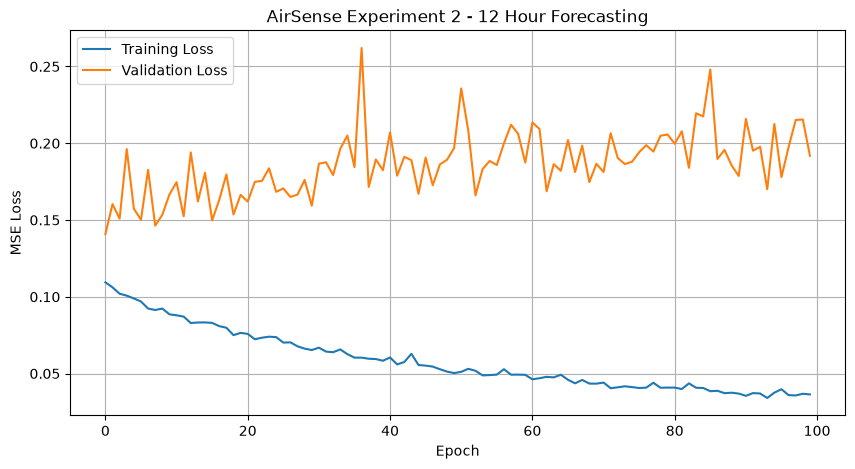

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    forecast_train_losses_12h,
    label="Training Loss"
)

plt.plot(
    forecast_val_losses_12h,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("AirSense Experiment 2 - 12 Hour Forecasting")
plt.legend()
plt.grid(True)

plt.show()

In [170]:
print("EXPERIMENT 2 LOSS ANALYSIS")
print("-" * 40)

print("Initial training loss:", forecast_train_losses_12h[0])
print("Final training loss:", forecast_train_losses_12h[-1])

print("Initial validation loss:", forecast_val_losses_12h[0])
print("Lowest validation loss:", min(forecast_val_losses_12h))
print("Epoch with lowest validation loss:",
      np.argmin(forecast_val_losses_12h) + 1)

print("Final validation loss:", forecast_val_losses_12h[-1])

EXPERIMENT 2 LOSS ANALYSIS
----------------------------------------
Initial training loss: 0.10941590778529645
Final training loss: 0.0364000189738969
Initial validation loss: 0.14074933694468605
Lowest validation loss: 0.14074933694468605
Epoch with lowest validation loss: 1
Final validation loss: 0.19181595908270943


In [171]:
# Load the best Experiment 2 checkpoint

forecast_model_12h.load_state_dict(
    torch.load(
        "airsense_forecast_12h_best.pt",
        map_location=device
    )
)

forecast_model_12h.eval()

# Load test data
test_X_12h = forecast_tensors_12h["test"]["X"]
test_y_12h = forecast_tensors_12h["test"]["y"]

# Generate predictions
with torch.no_grad():

    test_predictions_12h = forecast_model_12h(
        test_X_12h.to(device)
    )

# Convert tensors to NumPy
actual_12h = test_y_12h.cpu().numpy()

predicted_12h = test_predictions_12h.cpu().numpy()

print("EXPERIMENT 2 TEST PREDICTIONS")
print("-" * 40)

print("Actual shape:", actual_12h.shape)
print("Predicted shape:", predicted_12h.shape)

print("Actual contains NaN:", np.isnan(actual_12h).any())
print("Predicted contains NaN:", np.isnan(predicted_12h).any())

print("Actual contains infinity:", np.isinf(actual_12h).any())
print("Predicted contains infinity:", np.isinf(predicted_12h).any())

print("\nFirst 3 actual samples:")
print(actual_12h[:3])

print("\nFirst 3 predicted samples:")
print(predicted_12h[:3])

EXPERIMENT 2 TEST PREDICTIONS
----------------------------------------
Actual shape: (871, 12)
Predicted shape: (871, 12)
Actual contains NaN: False
Predicted contains NaN: False
Actual contains infinity: False
Predicted contains infinity: False

First 3 actual samples:
[[ 0.5666717  -0.03255208  0.34333017  0.4670147   1.4238147  -0.8361335
   1.8034174  -1.4885181   0.8992328  -1.2150877  -1.0998617  -2.1735315 ]
 [ 1.042041    0.6295653   1.1116258   1.1471261   2.1335192  -1.1842983
   2.0755615  -0.93053645  1.6343802  -1.4017307  -0.8635396  -2.107539  ]
 [ 4.1658955   2.381699    3.9504125   3.128148    4.740597   -1.88498
   4.03005     1.1268072   3.170585   -1.6754736  -0.26710767 -1.9087183 ]]

First 3 predicted samples:
[[ 0.8994123   0.5548694   0.81764895  0.97857565  2.0456038  -1.0292289
   2.1369474  -0.94349986  1.3819779  -1.3359034  -0.4338655  -2.0023627 ]
 [ 0.762873    0.3567523   0.6311947   0.8187389   1.9146813  -0.88210166
   2.0513096  -1.2145641   1.2216693

In [172]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate Experiment 2 metrics
mae_12h = mean_absolute_error(
    actual_12h, predicted_12h
)

mse_12h = mean_squared_error(
    actual_12h, predicted_12h
)

rmse_12h = np.sqrt(mse_12h)

print("EXPERIMENT 2 MODEL EVALUATION")
print("-" * 40)
print(f"MAE:  {mae_12h:.6f}")
print(f"MSE:  {mse_12h:.6f}")
print(f"RMSE: {rmse_12h:.6f}")

EXPERIMENT 2 MODEL EVALUATION
----------------------------------------
MAE:  0.336427
MSE:  0.205502
RMSE: 0.453323


In [173]:
# Experiment 2 persistence baseline

baseline_predictions_12h = test_X_12h[:, -1, :]

baseline_predictions_12h = (
    baseline_predictions_12h.cpu().numpy()
)

baseline_mae_12h = mean_absolute_error(
    actual_12h, baseline_predictions_12h
)

baseline_mse_12h = mean_squared_error(
    actual_12h, baseline_predictions_12h
)

baseline_rmse_12h = np.sqrt(baseline_mse_12h)

print("EXPERIMENT 2 BASELINE EVALUATION")
print("-" * 40)
print(f"MAE:  {baseline_mae_12h:.6f}")
print(f"MSE:  {baseline_mse_12h:.6f}")
print(f"RMSE: {baseline_rmse_12h:.6f}")

EXPERIMENT 2 BASELINE EVALUATION
----------------------------------------
MAE:  0.284977
MSE:  0.191621
RMSE: 0.437746


In [174]:
import pandas as pd
import os

# Create comparison table
comparison_12h = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE"],
    "Transformer_12h": [
        mae_12h,
        mse_12h,
        rmse_12h
    ],
    "Baseline_12h": [
        baseline_mae_12h,
        baseline_mse_12h,
        baseline_rmse_12h
    ]
})

# Save results
os.makedirs("evaluation", exist_ok=True)

comparison_12h.to_csv(
    "evaluation/experiment_2_comparison.csv",
    index=False
)

print("EXPERIMENT 2 COMPARISON")
print("-" * 50)

print(comparison_12h.to_string(index=False))

print("\nResults saved to:")
print("evaluation/experiment_2_comparison.csv")

EXPERIMENT 2 COMPARISON
--------------------------------------------------
Metric  Transformer_12h  Baseline_12h
   MAE         0.336427      0.284977
   MSE         0.205502      0.191621
  RMSE         0.453323      0.437746

Results saved to:
evaluation/experiment_2_comparison.csv


In [175]:
import pandas as pd
import numpy as np

# Feature names
feature_names = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "Temperature",
    "Relative Humidity",
    "Absolute Humidity"
]

# Calculate MAE for each feature
feature_mae_12h = np.mean(
    np.abs(actual_12h - predicted_12h),
    axis=0
)

# Calculate baseline MAE for each feature
feature_baseline_mae_12h = np.mean(
    np.abs(actual_12h - baseline_predictions_12h),
    axis=0
)

# Create comparison table
feature_comparison_12h = pd.DataFrame({
    "Feature": feature_names,
    "Transformer_MAE": feature_mae_12h,
    "Baseline_MAE": feature_baseline_mae_12h
})

print("FEATURE-WISE MAE COMPARISON (12-HOUR)")
print("-" * 70)

print(feature_comparison_12h.to_string(index=False))

FEATURE-WISE MAE COMPARISON (12-HOUR)
----------------------------------------------------------------------
          Feature  Transformer_MAE  Baseline_MAE
           CO(GT)         0.404877      0.368086
      PT08.S1(CO)         0.299417      0.304646
         C6H6(GT)         0.343638      0.323905
    PT08.S2(NMHC)         0.413475      0.368439
          NOx(GT)         0.338225      0.339340
     PT08.S3(NOx)         0.352884      0.290254
          NO2(GT)         0.464736      0.445526
     PT08.S4(NO2)         0.390795      0.287313
      PT08.S5(O3)         0.377864      0.351136
      Temperature         0.228238      0.108614
Relative Humidity         0.248051      0.178285
Absolute Humidity         0.174921      0.054181


In [176]:
feature_comparison_12h.to_csv(
    "evaluation/experiment_2_feature_wise.csv",
    index=False
)

print("Feature-wise results saved successfully!")
print("File: evaluation/experiment_2_feature_wise.csv")

Feature-wise results saved successfully!
File: evaluation/experiment_2_feature_wise.csv


In [177]:
# Calculate average prediction error for each feature
# Positive = overprediction
# Negative = underprediction

prediction_bias_12h = np.mean(
    predicted_12h - actual_12h,
    axis=0
)

bias_results_12h = pd.DataFrame({
    "Feature": feature_names,
    "Prediction_Bias": prediction_bias_12h
})

print("PREDICTION BIAS ANALYSIS (12-HOUR)")
print("-" * 55)

print(bias_results_12h.to_string(index=False))

PREDICTION BIAS ANALYSIS (12-HOUR)
-------------------------------------------------------
          Feature  Prediction_Bias
           CO(GT)         0.087383
      PT08.S1(CO)        -0.000941
         C6H6(GT)         0.126780
    PT08.S2(NMHC)         0.218441
          NOx(GT)         0.112209
     PT08.S3(NOx)         0.233507
          NO2(GT)        -0.203703
     PT08.S4(NO2)         0.252158
      PT08.S5(O3)         0.125242
      Temperature         0.135709
Relative Humidity         0.035431
Absolute Humidity         0.149853


In [178]:
bias_results_12h.to_csv(
    "evaluation/experiment_2_prediction_bias.csv",
    index=False
)

print("Prediction bias results saved successfully!")
print("File: evaluation/experiment_2_prediction_bias.csv")

Prediction bias results saved successfully!
File: evaluation/experiment_2_prediction_bias.csv


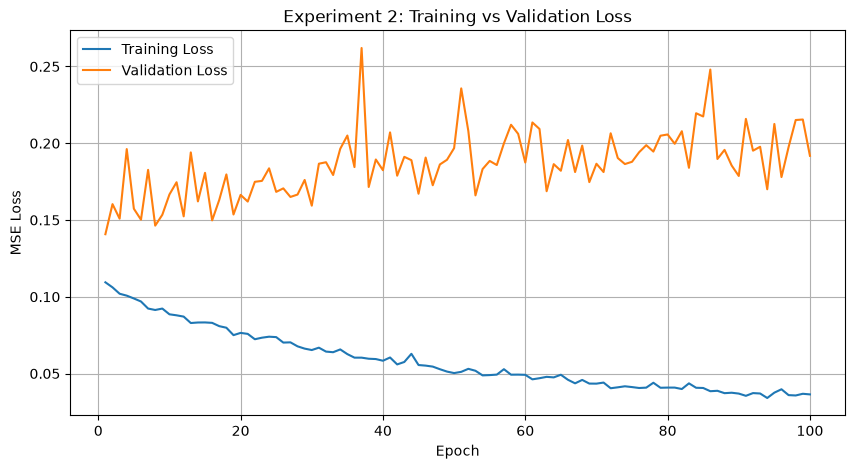

In [179]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(forecast_train_losses_12h) + 1),
    forecast_train_losses_12h,
    label="Training Loss"
)

plt.plot(
    range(1, len(forecast_val_losses_12h) + 1),
    forecast_val_losses_12h,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Experiment 2: Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [180]:
print("EXPERIMENT 2 LOSS ANALYSIS")
print("-" * 45)

print("First epoch:")
print("Training loss:", forecast_train_losses_12h[0])
print("Validation loss:", forecast_val_losses_12h[0])

print("\nBest validation epoch:")
print(np.argmin(forecast_val_losses_12h) + 1)

print("\nLast epoch:")
print("Training loss:", forecast_train_losses_12h[-1])
print("Validation loss:", forecast_val_losses_12h[-1])

EXPERIMENT 2 LOSS ANALYSIS
---------------------------------------------
First epoch:
Training loss: 0.10941590778529645
Validation loss: 0.14074933694468605

Best validation epoch:
1

Last epoch:
Training loss: 0.0364000189738969
Validation loss: 0.19181595908270943


In [181]:
loss_analysis_12h = pd.DataFrame({
    "Measurement": [
        "Initial Training Loss",
        "Final Training Loss",
        "Initial Validation Loss",
        "Final Validation Loss",
        "Best Validation Loss",
        "Best Epoch"
    ],
    "Value": [
        forecast_train_losses_12h[0],
        forecast_train_losses_12h[-1],
        forecast_val_losses_12h[0],
        forecast_val_losses_12h[-1],
        min(forecast_val_losses_12h),
        np.argmin(forecast_val_losses_12h) + 1
    ]
})

loss_analysis_12h.to_csv(
    "evaluation/experiment_2_loss_analysis.csv",
    index=False
)

print("Loss analysis saved successfully!")
print(loss_analysis_12h.to_string(index=False))


Loss analysis saved successfully!
            Measurement    Value
  Initial Training Loss 0.109416
    Final Training Loss 0.036400
Initial Validation Loss 0.140749
  Final Validation Loss 0.191816
   Best Validation Loss 0.140749
             Best Epoch 1.000000


In [182]:
# EXPERIMENT 3: Improved regularisation

forecast_model_12h_exp3 = AirSenseTransformer12h(
    input_features=12,
    d_model=64,
    n_heads=4,
    n_layers=2,
    dropout=0.2
).to(device)

# Count parameters
total_params_exp3 = sum(
    p.numel() for p in forecast_model_12h_exp3.parameters()
)

print("EXPERIMENT 3 MODEL")
print("-" * 40)
print("Input window: 12 hours")
print("Input features: 12")
print("Dropout: 0.2")
print("Learning rate: 0.0003")
print("Weight decay: 0.05")
print("Total parameters:", total_params_exp3)
print("Device:", device)

EXPERIMENT 3 MODEL
----------------------------------------
Input window: 12 hours
Input features: 12
Dropout: 0.2
Learning rate: 0.0003
Weight decay: 0.05
Total parameters: 73484
Device: cpu


In [183]:
import torch
import torch.nn as nn

# Loss function
criterion_exp3 = nn.MSELoss()

# Optimizer
optimizer_exp3 = torch.optim.AdamW(
    forecast_model_12h_exp3.parameters(),
    lr=0.0003,
    weight_decay=0.05
)

# Learning rate scheduler
scheduler_exp3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp3,
    mode="min",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Training configuration
epochs_exp3 = 100
best_val_loss_exp3 = float("inf")
patience_exp3 = 12

print("EXPERIMENT 3 TRAINING CONFIGURATION")
print("-" * 45)
print("Optimizer: AdamW")
print("Learning rate: 0.0003")
print("Weight decay: 0.05")
print("Scheduler: ReduceLROnPlateau")
print("Maximum epochs:", epochs_exp3)
print("Early stopping patience:", patience_exp3)

EXPERIMENT 3 TRAINING CONFIGURATION
---------------------------------------------
Optimizer: AdamW
Learning rate: 0.0003
Weight decay: 0.05
Scheduler: ReduceLROnPlateau
Maximum epochs: 100
Early stopping patience: 12


In [185]:
print("AVAILABLE DATALOADERS")
print("-" * 40)

for name in globals():
    if "loader" in name.lower():
        print(name)

AVAILABLE DATALOADERS
----------------------------------------
__loader__
DataLoader
train_loader
val_loader
train_loader_12h
val_loader_12h
test_loader_12h


In [189]:
import torch
import torch.nn as nn
import copy
import os

# Create separate lists for Experiment 3
forecast_train_losses_exp3 = []
forecast_val_losses_exp3 = []

best_val_loss_exp3 = float("inf")
epochs_without_improvement = 0

# Create a separate folder for Experiment 3
os.makedirs("model/experiment_3", exist_ok=True)

# Training loop
for epoch in range(epochs_exp3):

    # -------------------------
    # TRAINING PHASE
    # -------------------------
    forecast_model_12h_exp3.train()
    train_loss = 0.0

    for batch_X, batch_y in train_loader_12h:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_exp3.zero_grad()

        predictions = forecast_model_12h_exp3(batch_X)

        loss = criterion_exp3(predictions, batch_y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            forecast_model_12h_exp3.parameters(),
            max_norm=1.0
        )

        optimizer_exp3.step()

        train_loss += loss.item()

    train_loss /= len(train_loader_12h)

    # -------------------------
    # VALIDATION PHASE
    # -------------------------
    forecast_model_12h_exp3.eval()
    val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader_12h:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = forecast_model_12h_exp3(batch_X)

            loss = criterion_exp3(predictions, batch_y)

            val_loss += loss.item()

    val_loss /= len(val_loader_12h)

    # Store losses
    forecast_train_losses_exp3.append(train_loss)
    forecast_val_losses_exp3.append(val_loss)

    # Adjust learning rate
    scheduler_exp3.step(val_loss)

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if val_loss < best_val_loss_exp3:

        best_val_loss_exp3 = val_loss
        epochs_without_improvement = 0

        torch.save(
            forecast_model_12h_exp3.state_dict(),
            "model/experiment_3/airsense_forecast_exp3_best.pt"
        )

    else:
        epochs_without_improvement += 1

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs_exp3}] "
            f"Train Loss: {train_loss:.6f} "
            f"Validation Loss: {val_loss:.6f} "
            f"LR: {optimizer_exp3.param_groups[0]['lr']:.6f}"
        )

    # Early stopping
    if epochs_without_improvement >= patience_exp3:

        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# -------------------------
# TRAINING SUMMARY
# -------------------------
print("\nEXPERIMENT 3 TRAINING COMPLETED")
print("-" * 45)
print("Epochs completed:", len(forecast_train_losses_exp3))
print("Best validation loss:", best_val_loss_exp3)

# Save final model separately
torch.save(
    forecast_model_12h_exp3.state_dict(),
    "model/experiment_3/airsense_forecast_exp3_final.pt"
)

print("Best model and final model saved successfully!")

Epoch [10/100] Train Loss: 0.137280 Validation Loss: 0.163805 LR: 0.000300
Epoch [20/100] Train Loss: 0.120661 Validation Loss: 0.159285 LR: 0.000300
Epoch [30/100] Train Loss: 0.107041 Validation Loss: 0.141817 LR: 0.000150
Epoch [40/100] Train Loss: 0.103937 Validation Loss: 0.138958 LR: 0.000150
Epoch [50/100] Train Loss: 0.097762 Validation Loss: 0.134792 LR: 0.000075
Epoch [60/100] Train Loss: 0.092783 Validation Loss: 0.132515 LR: 0.000037
Epoch [70/100] Train Loss: 0.094925 Validation Loss: 0.131583 LR: 0.000037
Epoch [80/100] Train Loss: 0.092142 Validation Loss: 0.131559 LR: 0.000037
Epoch [90/100] Train Loss: 0.092467 Validation Loss: 0.130998 LR: 0.000019
Epoch [100/100] Train Loss: 0.092045 Validation Loss: 0.130480 LR: 0.000019

EXPERIMENT 3 TRAINING COMPLETED
---------------------------------------------
Epochs completed: 100
Best validation loss: 0.13005040461818376
Best model and final model saved successfully!


In [190]:
import torch
import numpy as np

# Load the best Experiment 3 model
forecast_model_12h_exp3.load_state_dict(
    torch.load(
        "model/experiment_3/airsense_forecast_exp3_best.pt",
        map_location=device
    )
)

forecast_model_12h_exp3.eval()

# Get test data
test_X_12h = forecast_tensors_12h["test"]["X"]
test_y_12h = forecast_tensors_12h["test"]["y"]

# Generate predictions
with torch.no_grad():
    test_predictions_exp3 = forecast_model_12h_exp3(
        test_X_12h.to(device)
    )

# Convert to NumPy
actual_exp3 = test_y_12h.cpu().numpy()
predicted_exp3 = test_predictions_exp3.cpu().numpy()

# Verify results
print("EXPERIMENT 3 TEST PREDICTIONS")
print("-" * 45)
print("Actual shape:", actual_exp3.shape)
print("Predicted shape:", predicted_exp3.shape)

print("Actual contains NaN:", np.isnan(actual_exp3).any())
print("Predicted contains NaN:", np.isnan(predicted_exp3).any())

print("Actual contains infinity:", np.isinf(actual_exp3).any())
print("Predicted contains infinity:", np.isinf(predicted_exp3).any())

print("\nFirst 3 predictions:")
print(predicted_exp3[:3])

print("\nFirst 3 actual values:")
print(actual_exp3[:3])

EXPERIMENT 3 TEST PREDICTIONS
---------------------------------------------
Actual shape: (871, 12)
Predicted shape: (871, 12)
Actual contains NaN: False
Predicted contains NaN: False
Actual contains infinity: False
Predicted contains infinity: False

First 3 predictions:
[[ 1.2253934   0.51724994  1.1081522   1.1103646   2.0843277  -1.2219123
   2.14287    -0.64143103  1.2901474  -1.2213472  -0.43180546 -1.8816203 ]
 [ 1.1160315   0.31494966  0.96633714  0.99568874  2.083066   -1.0591314
   2.166023   -0.87461346  1.2017616  -1.1661866  -0.64988816 -2.0336463 ]
 [ 1.9439348   1.2017474   1.8327196   1.6685408   2.8986764  -1.4533234
   2.5528111  -0.14976352  2.009473   -1.3280547  -0.31838977 -1.9027749 ]]

First 3 actual values:
[[ 0.5666717  -0.03255208  0.34333017  0.4670147   1.4238147  -0.8361335
   1.8034174  -1.4885181   0.8992328  -1.2150877  -1.0998617  -2.1735315 ]
 [ 1.042041    0.6295653   1.1116258   1.1471261   2.1335192  -1.1842983
   2.0755615  -0.93053645  1.6343802 

In [191]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Experiment 3 metrics
mae_exp3 = mean_absolute_error(actual_exp3, predicted_exp3)
mse_exp3 = mean_squared_error(actual_exp3, predicted_exp3)
rmse_exp3 = np.sqrt(mse_exp3)

# Persistence baseline
baseline_predictions_exp3 = test_X_12h[:, -1, :].cpu().numpy()

mae_baseline_exp3 = mean_absolute_error(
    actual_exp3, baseline_predictions_exp3
)

mse_baseline_exp3 = mean_squared_error(
    actual_exp3, baseline_predictions_exp3
)

rmse_baseline_exp3 = np.sqrt(mse_baseline_exp3)

# Experiment 2 results
comparison_exp3 = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE"],
    "Experiment 2": [0.336427, 0.205502, 0.453323],
    "Experiment 3": [mae_exp3, mse_exp3, rmse_exp3],
    "Baseline": [
        mae_baseline_exp3,
        mse_baseline_exp3,
        rmse_baseline_exp3
    ]
})

print("EXPERIMENT 2 vs EXPERIMENT 3 vs BASELINE")
print("-" * 65)
print(comparison_exp3.to_string(index=False))

# Save comparison
comparison_exp3.to_csv(
    "evaluation/experiment_3_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")

EXPERIMENT 2 vs EXPERIMENT 3 vs BASELINE
-----------------------------------------------------------------
Metric  Experiment 2  Experiment 3  Baseline
   MAE      0.336427      0.322833  0.284977
   MSE      0.205502      0.196890  0.191621
  RMSE      0.453323      0.443723  0.437746

Comparison saved successfully!


In [192]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

feature_names = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "Temperature",
    "Relative Humidity",
    "Absolute Humidity"
]

# Calculate MAE for every feature
feature_results_exp3 = []

for i, feature in enumerate(feature_names):

    transformer_mae = mean_absolute_error(
        actual_exp3[:, i],
        predicted_exp3[:, i]
    )

    baseline_mae = mean_absolute_error(
        actual_exp3[:, i],
        baseline_predictions_exp3[:, i]
    )

    feature_results_exp3.append({
        "Feature": feature,
        "Experiment 3 MAE": transformer_mae,
        "Baseline MAE": baseline_mae
    })

# Create comparison table
feature_comparison_exp3 = pd.DataFrame(feature_results_exp3)

print("EXPERIMENT 3 FEATURE-WISE EVALUATION")
print("-" * 65)
print(feature_comparison_exp3.to_string(index=False))

# Count better-performing features
better_features = sum(
    feature_comparison_exp3["Experiment 3 MAE"] <
    feature_comparison_exp3["Baseline MAE"]
)

print("\nFeatures where Experiment 3 performs better:", better_features)
print("Features where baseline performs better:", 12 - better_features)

# Save results
feature_comparison_exp3.to_csv(
    "evaluation/experiment_3_feature_wise.csv",
    index=False
)

print("\nFeature-wise results saved successfully!")

EXPERIMENT 3 FEATURE-WISE EVALUATION
-----------------------------------------------------------------
          Feature  Experiment 3 MAE  Baseline MAE
           CO(GT)          0.383519      0.368086
      PT08.S1(CO)          0.307148      0.304646
         C6H6(GT)          0.322242      0.323904
    PT08.S2(NMHC)          0.401632      0.368438
          NOx(GT)          0.317934      0.339340
     PT08.S3(NOx)          0.332127      0.290254
          NO2(GT)          0.467381      0.445525
     PT08.S4(NO2)          0.386692      0.287313
      PT08.S5(O3)          0.355196      0.351136
      Temperature          0.183557      0.108614
Relative Humidity          0.235324      0.178285
Absolute Humidity          0.181247      0.054181

Features where Experiment 3 performs better: 2
Features where baseline performs better: 10

Feature-wise results saved successfully!


In [193]:
import numpy as np
import pandas as pd

feature_names = [
    "CO(GT)", "PT08.S1(CO)", "C6H6(GT)",
    "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)",
    "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)",
    "Temperature", "Relative Humidity", "Absolute Humidity"
]

# Calculate prediction bias
bias_exp3 = np.mean(predicted_exp3 - actual_exp3, axis=0)

bias_baseline_exp3 = np.mean(
    baseline_predictions_exp3 - actual_exp3,
    axis=0
)

# Create comparison table
bias_results_exp3 = pd.DataFrame({
    "Feature": feature_names,
    "Experiment 3 Bias": bias_exp3,
    "Baseline Bias": bias_baseline_exp3
})

print("EXPERIMENT 3 PREDICTION BIAS")
print("-" * 65)
print(bias_results_exp3.to_string(index=False))

print("\nINTERPRETATION")
print("Positive bias = Model tends to overpredict.")
print("Negative bias = Model tends to underpredict.")

# Save results
bias_results_exp3.to_csv(
    "evaluation/experiment_3_prediction_bias.csv",
    index=False
)

print("\nPrediction bias results saved successfully!")


EXPERIMENT 3 PREDICTION BIAS
-----------------------------------------------------------------
          Feature  Experiment 3 Bias  Baseline Bias
           CO(GT)           0.061864       0.035008
      PT08.S1(CO)          -0.105091       0.032491
         C6H6(GT)           0.089794       0.038109
    PT08.S2(NMHC)           0.206359       0.054141
          NOx(GT)           0.066903       0.042115
     PT08.S3(NOx)           0.189846      -0.051875
          NO2(GT)          -0.256086       0.070813
     PT08.S4(NO2)           0.242605       0.027323
      PT08.S5(O3)           0.020793       0.023816
      Temperature           0.097663       0.041986
Relative Humidity           0.005231      -0.061203
Absolute Humidity           0.150856      -0.005675

INTERPRETATION
Positive bias = Model tends to overpredict.
Negative bias = Model tends to underpredict.

Prediction bias results saved successfully!


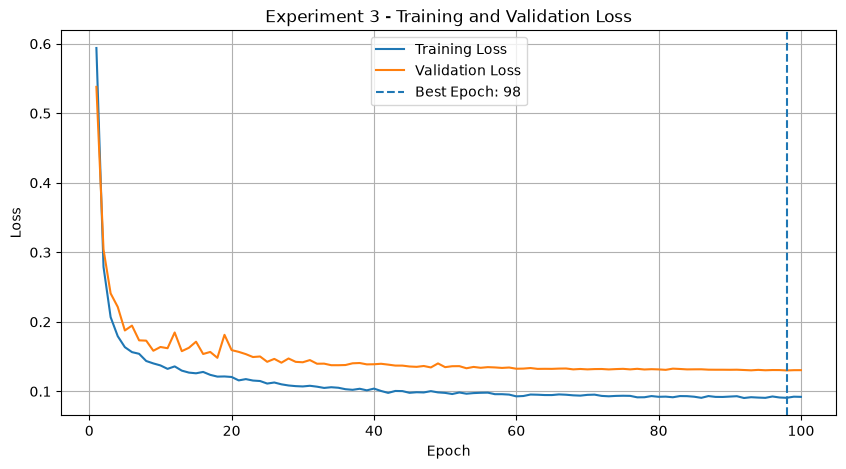

EXPERIMENT 3 LOSS ANALYSIS
---------------------------------------------
Initial Training Loss: 0.5939019694924355
Final Training Loss: 0.09204546709855398
Initial Validation Loss: 0.538005186451806
Final Validation Loss: 0.13048049848940638
Best Validation Loss: 0.13005040461818376
Best Validation Epoch: 98

Loss analysis saved successfully!


In [194]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Create epoch numbers
epochs = range(1, len(forecast_train_losses_exp3) + 1)

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    forecast_train_losses_exp3,
    label="Training Loss"
)

plt.plot(
    epochs,
    forecast_val_losses_exp3,
    label="Validation Loss"
)

# Mark best validation epoch
best_epoch_exp3 = np.argmin(forecast_val_losses_exp3) + 1

plt.axvline(
    best_epoch_exp3,
    linestyle="--",
    label=f"Best Epoch: {best_epoch_exp3}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 3 - Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

# Print loss analysis
print("EXPERIMENT 3 LOSS ANALYSIS")
print("-" * 45)

print("Initial Training Loss:", forecast_train_losses_exp3[0])
print("Final Training Loss:", forecast_train_losses_exp3[-1])

print("Initial Validation Loss:", forecast_val_losses_exp3[0])
print("Final Validation Loss:", forecast_val_losses_exp3[-1])

print("Best Validation Loss:", min(forecast_val_losses_exp3))
print("Best Validation Epoch:", best_epoch_exp3)

# Save results
loss_analysis_exp3 = pd.DataFrame({
    "Measurement": [
        "Initial Training Loss",
        "Final Training Loss",
        "Initial Validation Loss",
        "Final Validation Loss",
        "Best Validation Loss",
        "Best Epoch"
    ],
    "Value": [
        forecast_train_losses_exp3[0],
        forecast_train_losses_exp3[-1],
        forecast_val_losses_exp3[0],
        forecast_val_losses_exp3[-1],
        min(forecast_val_losses_exp3),
        best_epoch_exp3
    ]
})

loss_analysis_exp3.to_csv(
    "evaluation/experiment_3_loss_analysis.csv",
    index=False
)

print("\nLoss analysis saved successfully!")

In [195]:
import torch
import torch.nn as nn

class AirSenseMLP(nn.Module):

    def __init__(self, input_features=12, hidden_size=128):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(12 * input_features, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, input_features)
        )

    def forward(self, x):
        return self.network(x)


# Create Experiment 4 model
forecast_model_exp4 = AirSenseMLP(
    input_features=12,
    hidden_size=128
).to(device)

# Display model information
print("EXPERIMENT 4 - MLP MODEL")
print("-" * 40)

print("Input window: 12 hours")
print("Input features: 12")
print("Output features: 12")
print("Architecture: MLP")
print("Device:", device)

total_params = sum(
    p.numel() for p in forecast_model_exp4.parameters()
)

print("Total parameters:", total_params)

# Test model output
sample_input = torch.randn(1, 12, 12).to(device)

with torch.no_grad():
    sample_output = forecast_model_exp4(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

EXPERIMENT 4 - MLP MODEL
----------------------------------------
Input window: 12 hours
Input features: 12
Output features: 12
Architecture: MLP
Device: cpu
Total parameters: 27596
Input shape: torch.Size([1, 12, 12])
Output shape: torch.Size([1, 12])


In [196]:
import torch
import torch.nn as nn
import copy

# Loss function
criterion_exp4 = nn.MSELoss()

# Optimizer
optimizer_exp4 = torch.optim.AdamW(
    forecast_model_exp4.parameters(),
    lr=0.001,
    weight_decay=0.01
)

# Training settings
epochs_exp4 = 100
patience_exp4 = 12

best_val_loss_exp4 = float("inf")
early_stop_counter_exp4 = 0

forecast_train_losses_exp4 = []
forecast_val_losses_exp4 = []

best_model_weights_exp4 = None

print("EXPERIMENT 4 TRAINING SETUP")
print("-" * 40)
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.01")
print("Loss function: MSE")
print("Maximum epochs:", epochs_exp4)
print("Early stopping patience:", patience_exp4)

print("\nTraining setup completed!")

EXPERIMENT 4 TRAINING SETUP
----------------------------------------
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.01
Loss function: MSE
Maximum epochs: 100
Early stopping patience: 12

Training setup completed!


In [197]:
import os
import copy
import torch

# Create a separate folder for Experiment 4
os.makedirs("model/experiment_4", exist_ok=True)

for epoch in range(epochs_exp4):

    # Training phase
    forecast_model_exp4.train()
    total_train_loss = 0

    for batch_X, batch_y in train_loader_12h:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_exp4.zero_grad()

        predictions = forecast_model_exp4(batch_X)
        loss = criterion_exp4(predictions, batch_y)

        loss.backward()
        optimizer_exp4.step()

        total_train_loss += loss.item() * batch_X.size(0)

    avg_train_loss = total_train_loss / len(train_loader_12h.dataset)

    # Validation phase
    forecast_model_exp4.eval()
    total_val_loss = 0

    with torch.no_grad():
        for batch_X, batch_y in val_loader_12h:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = forecast_model_exp4(batch_X)
            loss = criterion_exp4(predictions, batch_y)

            total_val_loss += loss.item() * batch_X.size(0)

    avg_val_loss = total_val_loss / len(val_loader_12h.dataset)

    forecast_train_losses_exp4.append(avg_train_loss)
    forecast_val_losses_exp4.append(avg_val_loss)

    # Save best model
    if avg_val_loss < best_val_loss_exp4:
        best_val_loss_exp4 = avg_val_loss
        best_model_weights_exp4 = copy.deepcopy(
            forecast_model_exp4.state_dict()
        )
        early_stop_counter_exp4 = 0

        torch.save(
            best_model_weights_exp4,
            "model/experiment_4/airsense_mlp_exp4_best.pt"
        )
    else:
        early_stop_counter_exp4 += 1

    # Display progress
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs_exp4}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Validation Loss: {avg_val_loss:.6f}"
        )

    # Early stopping
    if early_stop_counter_exp4 >= patience_exp4:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best model
forecast_model_exp4.load_state_dict(best_model_weights_exp4)

# Save final model
torch.save(
    forecast_model_exp4.state_dict(),
    "model/experiment_4/airsense_mlp_exp4_final.pt"
)

print("\nEXPERIMENT 4 TRAINING COMPLETED")
print("-" * 40)
print("Best validation loss:", best_val_loss_exp4)
print("Total epochs completed:", len(forecast_train_losses_exp4))
print("Best model saved successfully!")

Epoch [10/100] Train Loss: 0.165741 Validation Loss: 0.209494
Epoch [20/100] Train Loss: 0.144011 Validation Loss: 0.175782

Early stopping at epoch 23

EXPERIMENT 4 TRAINING COMPLETED
----------------------------------------
Best validation loss: 0.1675189124731831
Total epochs completed: 23
Best model saved successfully!


In [198]:
import numpy as np
import torch

forecast_model_exp4.eval()

predictions_exp4 = []
actual_exp4 = []

with torch.no_grad():

    for batch_X, batch_y in test_loader_12h:

        batch_X = batch_X.to(device)

        predictions = forecast_model_exp4(batch_X)

        predictions_exp4.append(predictions.cpu().numpy())
        actual_exp4.append(batch_y.numpy())

# Combine batches
predictions_exp4 = np.concatenate(predictions_exp4, axis=0)
actual_exp4 = np.concatenate(actual_exp4, axis=0)

print("EXPERIMENT 4 TEST PREDICTIONS")
print("-" * 40)

print("Actual shape:", actual_exp4.shape)
print("Predicted shape:", predictions_exp4.shape)

print("\nFirst 3 actual readings:")
print(actual_exp4[:3])

print("\nFirst 3 predicted readings:")
print(predictions_exp4[:3])

print("\nNaN values:", np.isnan(predictions_exp4).sum())
print("Infinite values:", np.isinf(predictions_exp4).sum())

EXPERIMENT 4 TEST PREDICTIONS
----------------------------------------
Actual shape: (871, 12)
Predicted shape: (871, 12)

First 3 actual readings:
[[ 0.5666717  -0.03255208  0.34333017  0.4670147   1.4238147  -0.8361335
   1.8034174  -1.4885181   0.8992328  -1.2150877  -1.0998617  -2.1735315 ]
 [ 1.042041    0.6295653   1.1116258   1.1471261   2.1335192  -1.1842983
   2.0755615  -0.93053645  1.6343802  -1.4017307  -0.8635396  -2.107539  ]
 [ 4.1658955   2.381699    3.9504125   3.128148    4.740597   -1.88498
   4.03005     1.1268072   3.170585   -1.6754736  -0.26710767 -1.9087183 ]]

First 3 predicted readings:
[[ 0.79040956  0.22711727  0.70547605  0.62748224  1.8065438  -0.8861481
   1.9892119  -1.2904836   1.2398082  -1.4102187  -0.24033989 -1.8391031 ]
 [ 0.87795883  0.23830897  0.85881346  0.7774676   1.8239293  -0.89216036
   2.208486   -1.2180011   1.2461108  -1.2585466  -0.55117846 -1.9090632 ]
 [ 1.858972    1.0761443   1.6407634   1.5397171   2.559101   -1.2695261
   2.64995

In [199]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Calculate Experiment 4 metrics
mae_exp4 = mean_absolute_error(
    actual_exp4.flatten(),
    predictions_exp4.flatten()
)

mse_exp4 = mean_squared_error(
    actual_exp4.flatten(),
    predictions_exp4.flatten()
)

rmse_exp4 = np.sqrt(mse_exp4)

# Display results
print("EXPERIMENT 4 EVALUATION RESULTS")
print("-" * 45)

print(f"MAE:  {mae_exp4:.6f}")
print(f"MSE:  {mse_exp4:.6f}")
print(f"RMSE: {rmse_exp4:.6f}")

# Compare all experiments
comparison_exp4 = pd.DataFrame({
    "Model": [
        "Experiment 2 - Transformer",
        "Experiment 3 - Regularized Transformer",
        "Experiment 4 - MLP",
        "Persistence Baseline"
    ],
    "MAE": [
        0.336427,
        0.322833,
        mae_exp4,
        0.284977
    ],
    "MSE": [
        0.205502,
        0.196890,
        mse_exp4,
        0.191621
    ],
    "RMSE": [
        0.453323,
        0.443723,
        rmse_exp4,
        0.437746
    ]
})

print("\nMODEL COMPARISON")
print("-" * 70)
print(comparison_exp4.to_string(index=False))

# Save comparison
comparison_exp4.to_csv(
    "evaluation/experiment_4_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")


EXPERIMENT 4 EVALUATION RESULTS
---------------------------------------------
MAE:  0.345585
MSE:  0.233388
RMSE: 0.483102

MODEL COMPARISON
----------------------------------------------------------------------
                                 Model      MAE      MSE     RMSE
            Experiment 2 - Transformer 0.336427 0.205502 0.453323
Experiment 3 - Regularized Transformer 0.322833 0.196890 0.443723
                    Experiment 4 - MLP 0.345585 0.233388 0.483102
                  Persistence Baseline 0.284977 0.191621 0.437746

Comparison saved successfully!


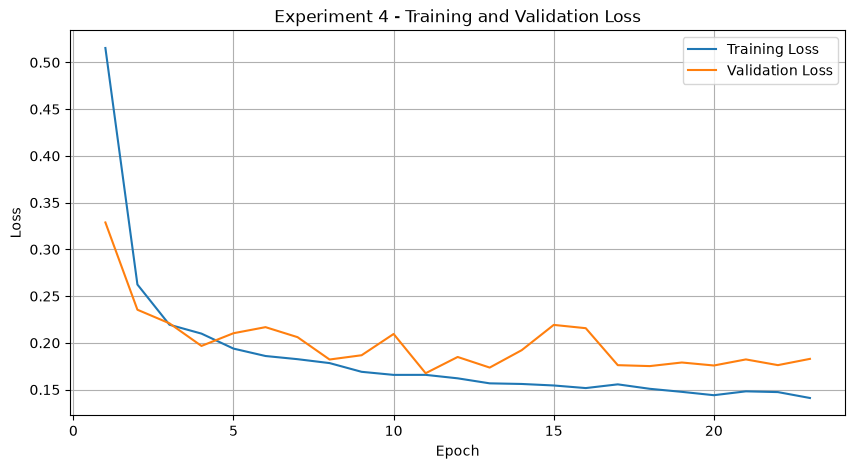

EXPERIMENT 4 LOSS ANALYSIS
----------------------------------------
Initial Training Loss: 0.515405755089119
Final Training Loss: 0.1410174764217877
Initial Validation Loss: 0.3287917384049222
Final Validation Loss: 0.18287030477540772
Best Validation Loss: 0.1675189124731831
Best Validation Epoch: 11


In [200]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(forecast_train_losses_exp4) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    forecast_train_losses_exp4,
    label="Training Loss"
)

plt.plot(
    epochs,
    forecast_val_losses_exp4,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 4 - Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

best_epoch_exp4 = np.argmin(forecast_val_losses_exp4) + 1

print("EXPERIMENT 4 LOSS ANALYSIS")
print("-" * 40)

print("Initial Training Loss:", forecast_train_losses_exp4[0])
print("Final Training Loss:", forecast_train_losses_exp4[-1])

print("Initial Validation Loss:", forecast_val_losses_exp4[0])
print("Final Validation Loss:", forecast_val_losses_exp4[-1])

print("Best Validation Loss:", min(forecast_val_losses_exp4))
print("Best Validation Epoch:", best_epoch_exp4)

EXPERIMENT 5 - FEATURE CORRELATION ANALYSIS
------------------------------------------------------------
          Feature  Average Absolute Correlation
    PT08.S2(NMHC)                      0.611570
         C6H6(GT)                      0.601249
      PT08.S1(CO)                      0.585411
           CO(GT)                      0.575498
      PT08.S5(O3)                      0.563102
     PT08.S3(NOx)                      0.550278
     PT08.S4(NO2)                      0.532847
          NOx(GT)                      0.524108
          NO2(GT)                      0.518467
      Temperature                      0.295259
Absolute Humidity                      0.252512
Relative Humidity                      0.241159

Feature correlation analysis saved successfully!


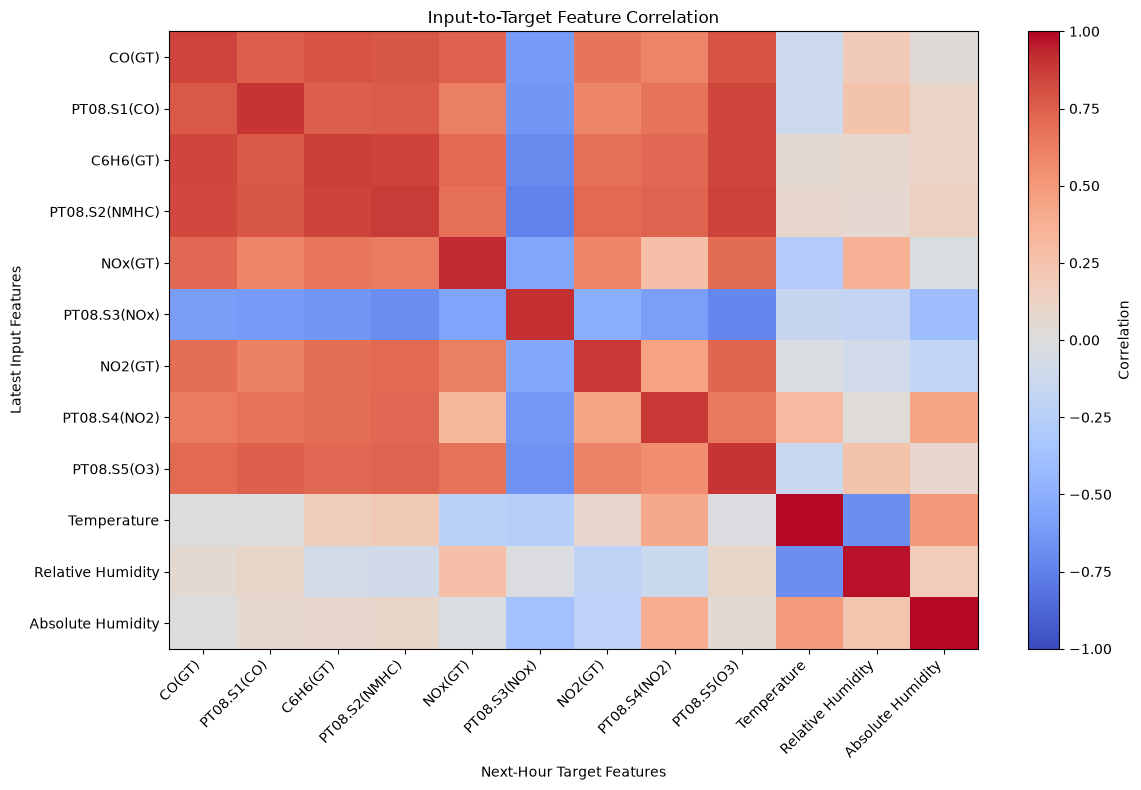

In [201]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load normalized training data
train_X_exp5 = np.load(
    "data/processed/normalized_12h/train_X.npy"
)

train_y_exp5 = np.load(
    "data/processed/normalized_12h/train_y.npy"
)

# Feature names
feature_names_exp5 = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "Temperature",
    "Relative Humidity",
    "Absolute Humidity"
]

# Use the most recent input reading from each 12-hour window
latest_input_exp5 = train_X_exp5[:, -1, :]

# Calculate correlation between latest input features
# and next-hour target features
correlation_matrix_exp5 = np.zeros((12, 12))

for i in range(12):
    for j in range(12):
        correlation_matrix_exp5[i, j] = np.corrcoef(
            latest_input_exp5[:, i],
            train_y_exp5[:, j]
        )[0, 1]

# Calculate average absolute correlation for each input feature
feature_scores_exp5 = np.mean(
    np.abs(correlation_matrix_exp5),
    axis=1
)

# Create results table
feature_analysis_exp5 = pd.DataFrame({
    "Feature": feature_names_exp5,
    "Average Absolute Correlation": feature_scores_exp5
})

feature_analysis_exp5 = feature_analysis_exp5.sort_values(
    by="Average Absolute Correlation",
    ascending=False
)

print("EXPERIMENT 5 - FEATURE CORRELATION ANALYSIS")
print("-" * 60)

print(feature_analysis_exp5.to_string(index=False))

# Save results
feature_analysis_exp5.to_csv(
    "evaluation/experiment_5_feature_correlation.csv",
    index=False
)

print("\nFeature correlation analysis saved successfully!")

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

plt.imshow(correlation_matrix_exp5, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(12), feature_names_exp5, rotation=45, ha="right")
plt.yticks(range(12), feature_names_exp5)

plt.xlabel("Next-Hour Target Features")
plt.ylabel("Latest Input Features")
plt.title("Input-to-Target Feature Correlation")

plt.tight_layout()
plt.show()

In [202]:

import numpy as np
import os

# Select top 9 features
selected_features_exp5 = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)"
]

# Find their original column positions
selected_indices_exp5 = [
    feature_names_exp5.index(feature)
    for feature in selected_features_exp5
]

# Create separate datasets
train_X_exp5_selected = train_X_exp5[:, :, selected_indices_exp5]
train_y_exp5_selected = train_y_exp5[:, selected_indices_exp5]

val_X_exp5 = np.load(
    "data/processed/normalized_12h/val_X.npy"
)[:, :, selected_indices_exp5]

val_y_exp5 = np.load(
    "data/processed/normalized_12h/val_y.npy"
)[:, selected_indices_exp5]

test_X_exp5 = np.load(
    "data/processed/normalized_12h/test_X.npy"
)[:, :, selected_indices_exp5]

test_y_exp5 = np.load(
    "data/processed/normalized_12h/test_y.npy"
)[:, selected_indices_exp5]

print("EXPERIMENT 5 DATASET")
print("-" * 40)

print("Selected features:", len(selected_indices_exp5))
print("Training input:", train_X_exp5_selected.shape)
print("Training target:", train_y_exp5_selected.shape)
print("Validation input:", val_X_exp5.shape)
print("Test input:", test_X_exp5.shape)

print("\nSelected-feature dataset prepared!")


FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/normalized_12h/val_X.npy'

In [203]:
import os

folder = "data/processed/normalized_12h"

print("Checking folder:", os.path.abspath(folder))

if os.path.exists(folder):
    print("\nFiles available:")
    for file in os.listdir(folder):
        print(file)
else:
    print("\nFolder does not exist!")
    

Checking folder: C:\Users\malav\OneDrive\Documents\SLM_AirQuality_New\data\processed\normalized_12h

Files available:
test_X.npy
test_y.npy
train_X.npy
train_y.npy
validation_X.npy
validation_y.npy


In [204]:
import numpy as np

# Load validation data using the correct filenames
val_X_exp5 = np.load(
    "data/processed/normalized_12h/validation_X.npy"
)[:, :, selected_indices_exp5]

val_y_exp5 = np.load(
    "data/processed/normalized_12h/validation_y.npy"
)[:, selected_indices_exp5]

# Load test data
test_X_exp5 = np.load(
    "data/processed/normalized_12h/test_X.npy"
)[:, :, selected_indices_exp5]

test_y_exp5 = np.load(
    "data/processed/normalized_12h/test_y.npy"
)[:, selected_indices_exp5]

print("EXPERIMENT 5 DATASET")
print("-" * 40)

print("Selected features:", len(selected_indices_exp5))
print("Training input:", train_X_exp5_selected.shape)
print("Training target:", train_y_exp5_selected.shape)
print("Validation input:", val_X_exp5.shape)
print("Validation target:", val_y_exp5.shape)
print("Test input:", test_X_exp5.shape)
print("Test target:", test_y_exp5.shape)

print("\nSelected-feature dataset prepared successfully!")

EXPERIMENT 5 DATASET
----------------------------------------
Selected features: 9
Training input: (1914, 12, 9)
Training target: (1914, 9)
Validation input: (281, 12, 9)
Validation target: (281, 9)
Test input: (871, 12, 9)
Test target: (871, 9)

Selected-feature dataset prepared successfully!


In [205]:
import torch
import torch.nn as nn

class AirSenseTransformerExp5(nn.Module):

    def __init__(
        self,
        input_features=9,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_features, d_model)

        self.position_embedding = nn.Parameter(
            torch.randn(1, 12, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        self.output_layer = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, input_features)
        )

    def forward(self, x):

        x = self.input_projection(x)
        x = x + self.position_embedding

        x = self.transformer(x)

        x = x[:, -1, :]

        return self.output_layer(x)


# Create Experiment 5 model
forecast_model_exp5 = AirSenseTransformerExp5().to(device)

# Check parameters
total_params_exp5 = sum(
    p.numel() for p in forecast_model_exp5.parameters()
)

# Test model
sample_input_exp5 = torch.randn(1, 12, 9).to(device)

with torch.no_grad():
    sample_output_exp5 = forecast_model_exp5(sample_input_exp5)

print("EXPERIMENT 5 MODEL")
print("-" * 40)
print("Architecture: Transformer")
print("Input features: 9")
print("Input window: 12 hours")
print("Output features: 9")
print("Parameters:", total_params_exp5)
print("Input shape:", sample_input_exp5.shape)
print("Output shape:", sample_output_exp5.shape)

EXPERIMENT 5 MODEL
----------------------------------------
Architecture: Transformer
Input features: 9
Input window: 12 hours
Output features: 9
Parameters: 110857
Input shape: torch.Size([1, 12, 9])
Output shape: torch.Size([1, 9])


In [206]:
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
train_X_tensor_exp5 = torch.tensor(
    train_X_exp5_selected, dtype=torch.float32
)
train_y_tensor_exp5 = torch.tensor(
    train_y_exp5_selected, dtype=torch.float32
)

val_X_tensor_exp5 = torch.tensor(
    val_X_exp5, dtype=torch.float32
)
val_y_tensor_exp5 = torch.tensor(
    val_y_exp5, dtype=torch.float32
)

test_X_tensor_exp5 = torch.tensor(
    test_X_exp5, dtype=torch.float32
)
test_y_tensor_exp5 = torch.tensor(
    test_y_exp5, dtype=torch.float32
)

# Create datasets
train_dataset_exp5 = TensorDataset(
    train_X_tensor_exp5, train_y_tensor_exp5
)

val_dataset_exp5 = TensorDataset(
    val_X_tensor_exp5, val_y_tensor_exp5
)

test_dataset_exp5 = TensorDataset(
    test_X_tensor_exp5, test_y_tensor_exp5
)

# Create DataLoaders
train_loader_exp5 = DataLoader(
    train_dataset_exp5, batch_size=32, shuffle=True
)

val_loader_exp5 = DataLoader(
    val_dataset_exp5, batch_size=32, shuffle=False
)

test_loader_exp5 = DataLoader(
    test_dataset_exp5, batch_size=32, shuffle=False
)

print("EXPERIMENT 5 DATALOADERS")
print("-" * 40)
print("Training batches:", len(train_loader_exp5))
print("Validation batches:", len(val_loader_exp5))
print("Testing batches:", len(test_loader_exp5))
print("\nDataLoaders created successfully!")

EXPERIMENT 5 DATALOADERS
----------------------------------------
Training batches: 60
Validation batches: 9
Testing batches: 28

DataLoaders created successfully!


In [207]:
import torch
import torch.nn as nn
import copy

# Loss function
criterion_exp5 = nn.MSELoss()

# Optimizer
optimizer_exp5 = torch.optim.AdamW(
    forecast_model_exp5.parameters(),
    lr=0.0003,
    weight_decay=0.05
)

# Training settings
epochs_exp5 = 100
patience_exp5 = 12

best_val_loss_exp5 = float("inf")
early_stop_counter_exp5 = 0

forecast_train_losses_exp5 = []
forecast_val_losses_exp5 = []

best_model_weights_exp5 = None

print("EXPERIMENT 5 TRAINING SETUP")
print("-" * 40)
print("Optimizer: AdamW")
print("Learning rate: 0.0003")
print("Weight decay: 0.05")
print("Dropout: 0.2")
print("Loss function: MSE")
print("Maximum epochs:", epochs_exp5)
print("Early stopping patience:", patience_exp5)

print("\nTraining setup completed!")

EXPERIMENT 5 TRAINING SETUP
----------------------------------------
Optimizer: AdamW
Learning rate: 0.0003
Weight decay: 0.05
Dropout: 0.2
Loss function: MSE
Maximum epochs: 100
Early stopping patience: 12

Training setup completed!


In [208]:
import os
import copy
import torch

# Create separate folder
os.makedirs("model/experiment_5", exist_ok=True)

for epoch in range(epochs_exp5):

    # Training
    forecast_model_exp5.train()
    total_train_loss = 0

    for batch_X, batch_y in train_loader_exp5:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_exp5.zero_grad()

        predictions = forecast_model_exp5(batch_X)
        loss = criterion_exp5(predictions, batch_y)

        loss.backward()
        optimizer_exp5.step()

        total_train_loss += loss.item() * batch_X.size(0)

    avg_train_loss = (
        total_train_loss / len(train_loader_exp5.dataset)
    )

    # Validation
    forecast_model_exp5.eval()
    total_val_loss = 0

    with torch.no_grad():

        for batch_X, batch_y in val_loader_exp5:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = forecast_model_exp5(batch_X)
            loss = criterion_exp5(predictions, batch_y)

            total_val_loss += loss.item() * batch_X.size(0)

    avg_val_loss = (
        total_val_loss / len(val_loader_exp5.dataset)
    )

    forecast_train_losses_exp5.append(avg_train_loss)
    forecast_val_losses_exp5.append(avg_val_loss)

    # Save best model
    if avg_val_loss < best_val_loss_exp5:

        best_val_loss_exp5 = avg_val_loss

        best_model_weights_exp5 = copy.deepcopy(
            forecast_model_exp5.state_dict()
        )

        early_stop_counter_exp5 = 0

        torch.save(
            best_model_weights_exp5,
            "model/experiment_5/airsense_exp5_best.pt"
        )

    else:
        early_stop_counter_exp5 += 1

    # Print progress
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs_exp5}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Validation Loss: {avg_val_loss:.6f}"
        )

    # Early stopping
    if early_stop_counter_exp5 >= patience_exp5:

        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best model
forecast_model_exp5.load_state_dict(
    best_model_weights_exp5
)

# Save final model
torch.save(
    forecast_model_exp5.state_dict(),
    "model/experiment_5/airsense_exp5_final.pt"
)

print("\nEXPERIMENT 5 TRAINING COMPLETED")
print("-" * 40)
print("Best validation loss:", best_val_loss_exp5)
print("Total epochs completed:", len(forecast_train_losses_exp5))
print("Best model saved successfully!")

Epoch [10/100] Train Loss: 0.188801 Validation Loss: 0.212684
Epoch [20/100] Train Loss: 0.165856 Validation Loss: 0.190094
Epoch [30/100] Train Loss: 0.146083 Validation Loss: 0.185404
Epoch [40/100] Train Loss: 0.135725 Validation Loss: 0.184015

Early stopping at epoch 46

EXPERIMENT 5 TRAINING COMPLETED
----------------------------------------
Best validation loss: 0.17871826351537398
Total epochs completed: 46
Best model saved successfully!


In [209]:
forecast_model_exp5.eval()

predictions_exp5 = []
actual_exp5 = []

with torch.no_grad():
    for batch_X, batch_y in test_loader_exp5:

        batch_X = batch_X.to(device)

        predictions = forecast_model_exp5(batch_X)

        predictions_exp5.append(predictions.cpu())
        actual_exp5.append(batch_y)

predictions_exp5 = torch.cat(predictions_exp5).numpy()
actual_exp5 = torch.cat(actual_exp5).numpy()

print("EXPERIMENT 5 TEST PREDICTIONS")
print("-" * 40)
print("Actual shape:", actual_exp5.shape)
print("Predicted shape:", predictions_exp5.shape)
print("NaN values:", predictions_exp5.isnan().sum() if False else __import__('numpy').isnan(predictions_exp5).sum())
print("Predictions generated successfully!")

EXPERIMENT 5 TEST PREDICTIONS
----------------------------------------
Actual shape: (871, 9)
Predicted shape: (871, 9)
NaN values: 0
Predictions generated successfully!


In [210]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae_exp5 = mean_absolute_error(actual_exp5, predictions_exp5)
mse_exp5 = mean_squared_error(actual_exp5, predictions_exp5)
rmse_exp5 = np.sqrt(mse_exp5)

print("EXPERIMENT 5 EVALUATION RESULTS")
print("-" * 45)
print(f"MAE:  {mae_exp5:.6f}")
print(f"MSE:  {mse_exp5:.6f}")
print(f"RMSE: {rmse_exp5:.6f}")

EXPERIMENT 5 EVALUATION RESULTS
---------------------------------------------
MAE:  0.354461
MSE:  0.235766
RMSE: 0.485558


In [211]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select the same 9 features from Experiment 3
actual_exp3_selected = actual_exp3[:, selected_indices_exp5]
predictions_exp3_selected = predictions_exp3[:, selected_indices_exp5]

# Experiment 3 metrics on the selected features
mae_exp3_selected = mean_absolute_error(
    actual_exp3_selected, predictions_exp3_selected
)

mse_exp3_selected = mean_squared_error(
    actual_exp3_selected, predictions_exp3_selected
)

rmse_exp3_selected = np.sqrt(mse_exp3_selected)

# Persistence baseline for the same 9 features
baseline_exp5 = test_X_exp5[:, -1, :]

mae_baseline_exp5 = mean_absolute_error(actual_exp5, baseline_exp5)
mse_baseline_exp5 = mean_squared_error(actual_exp5, baseline_exp5)
rmse_baseline_exp5 = np.sqrt(mse_baseline_exp5)

# Comparison table
comparison_exp5 = pd.DataFrame({
    "Model": [
        "Experiment 3 - Transformer (9 features)",
        "Experiment 5 - Feature Selection Transformer",
        "Persistence Baseline"
    ],
    "MAE": [
        mae_exp3_selected, mae_exp5, mae_baseline_exp5
    ],
    "MSE": [
        mse_exp3_selected, mse_exp5, mse_baseline_exp5
    ],
    "RMSE": [
        rmse_exp3_selected, rmse_exp5, rmse_baseline_exp5
    ]
})

print("EXPERIMENT 5 MODEL COMPARISON")
print("-" * 65)
display(comparison_exp5.round(6))

NameError: name 'predictions_exp3' is not defined

In [212]:
print("EXPERIMENT 3 VARIABLES")
print("-" * 40)

for name in globals():
    if "exp3" in name.lower() or "prediction" in name.lower():
        print(name)

EXPERIMENT 3 VARIABLES
----------------------------------------
sample_prediction
predictions
test_predictions
baseline_predictions
reconstructed_predictions
test_predictions_12h
baseline_predictions_12h
prediction_bias_12h
forecast_model_12h_exp3
total_params_exp3
criterion_exp3
optimizer_exp3
scheduler_exp3
epochs_exp3
best_val_loss_exp3
patience_exp3
forecast_train_losses_exp3
forecast_val_losses_exp3
test_predictions_exp3
actual_exp3
predicted_exp3
mae_exp3
mse_exp3
rmse_exp3
baseline_predictions_exp3
mae_baseline_exp3
mse_baseline_exp3
rmse_baseline_exp3
comparison_exp3
feature_results_exp3
feature_comparison_exp3
bias_exp3
bias_baseline_exp3
bias_results_exp3
best_epoch_exp3
loss_analysis_exp3
predictions_exp4
predictions_exp5
actual_exp3_selected


In [213]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select the same 9 features from Experiment 3
actual_exp3_selected = actual_exp3[:, selected_indices_exp5]
predictions_exp3_selected = predicted_exp3[:, selected_indices_exp5]

# Experiment 3 metrics
mae_exp3_selected = mean_absolute_error(
    actual_exp3_selected, predictions_exp3_selected
)

mse_exp3_selected = mean_squared_error(
    actual_exp3_selected, predictions_exp3_selected
)

rmse_exp3_selected = np.sqrt(mse_exp3_selected)

# Persistence baseline
baseline_exp5 = test_X_exp5[:, -1, :]

mae_baseline_exp5 = mean_absolute_error(actual_exp5, baseline_exp5)
mse_baseline_exp5 = mean_squared_error(actual_exp5, baseline_exp5)
rmse_baseline_exp5 = np.sqrt(mse_baseline_exp5)

# Comparison table
comparison_exp5 = pd.DataFrame({
    "Model": [
        "Experiment 3 - Transformer (9 features)",
        "Experiment 5 - Feature Selection Transformer",
        "Persistence Baseline"
    ],
    "MAE": [
        mae_exp3_selected, mae_exp5, mae_baseline_exp5
    ],
    "MSE": [
        mse_exp3_selected, mse_exp5, mse_baseline_exp5
    ],
    "RMSE": [
        rmse_exp3_selected, rmse_exp5, rmse_baseline_exp5
    ]
})

print("EXPERIMENT 5 MODEL COMPARISON")
print("-" * 65)
display(comparison_exp5.round(6))

EXPERIMENT 5 MODEL COMPARISON
-----------------------------------------------------------------


,Model,MAE,MSE,RMSE
0,Experiment 3 - Transformer (9 features),0.363763,0.240504,0.490412
1,Experiment 5 - Feature Selection Transformer,0.354461,0.235766,0.485558
2,Persistence Baseline,0.342071,0.245935,0.495918


In [214]:
comparison_exp5.to_csv(
    "evaluation/experiment_5_comparison.csv",
    index=False
)

print("Experiment 5 comparison saved successfully!")

Experiment 5 comparison saved successfully!


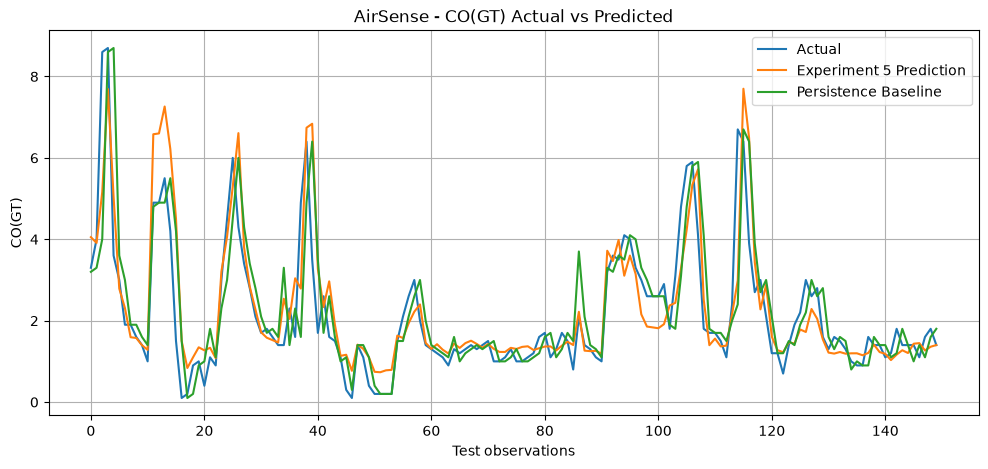

In [215]:
import matplotlib.pyplot as plt
import numpy as np

# Load normalization statistics
mean_values = np.load("data/processed/normalized/mean.npy")
std_values = np.load("data/processed/normalized/std.npy")

# CO(GT) is the first selected feature
feature_index = 0
original_index = selected_indices_exp5[feature_index]

# Convert normalized values back to original units
actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

# Plot first 150 test observations
plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - CO(GT) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("CO(GT)")
plt.legend()
plt.grid(True)
plt.show()

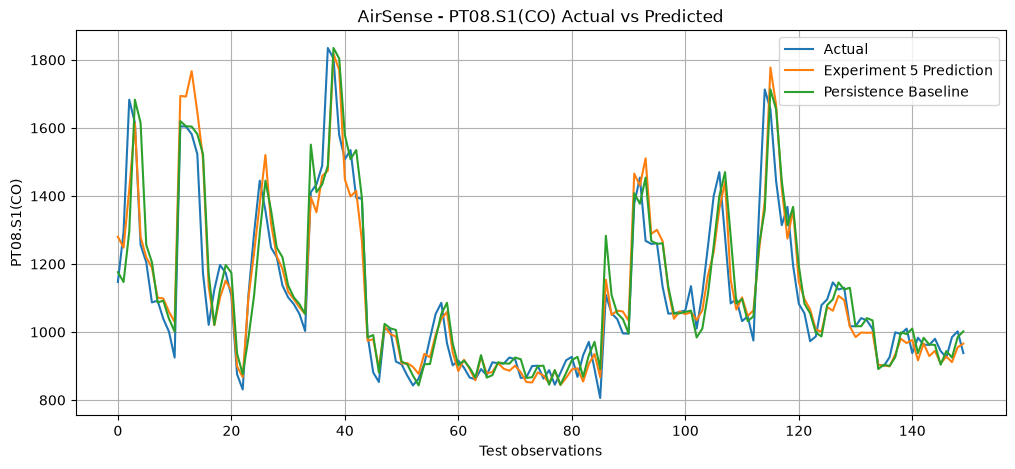

In [216]:
# PT08.S1(CO) is the second selected feature
feature_index = 1
original_index = selected_indices_exp5[feature_index]

# Convert normalized values to original units
actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

# Plot
plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - PT08.S1(CO) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("PT08.S1(CO)")
plt.legend()
plt.grid(True)
plt.show()

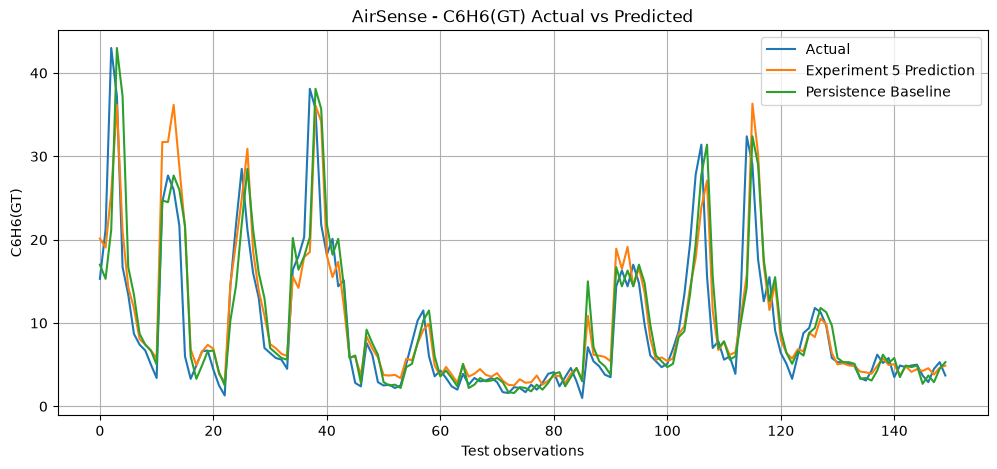

In [217]:
# C6H6(GT) is the third selected feature
feature_index = 2
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - C6H6(GT) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("C6H6(GT)")
plt.legend()
plt.grid(True)
plt.show()

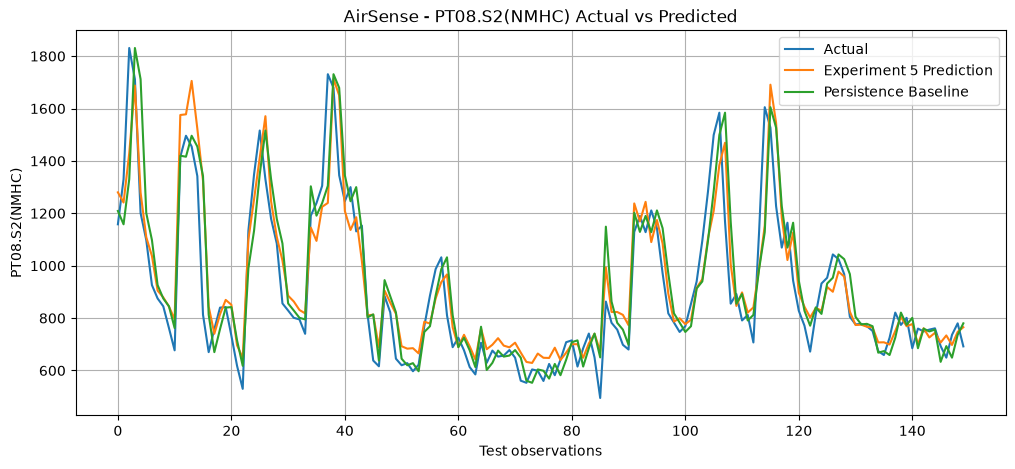

In [218]:
feature_index = 3
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - PT08.S2(NMHC) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("PT08.S2(NMHC)")
plt.legend()
plt.grid(True)
plt.show()

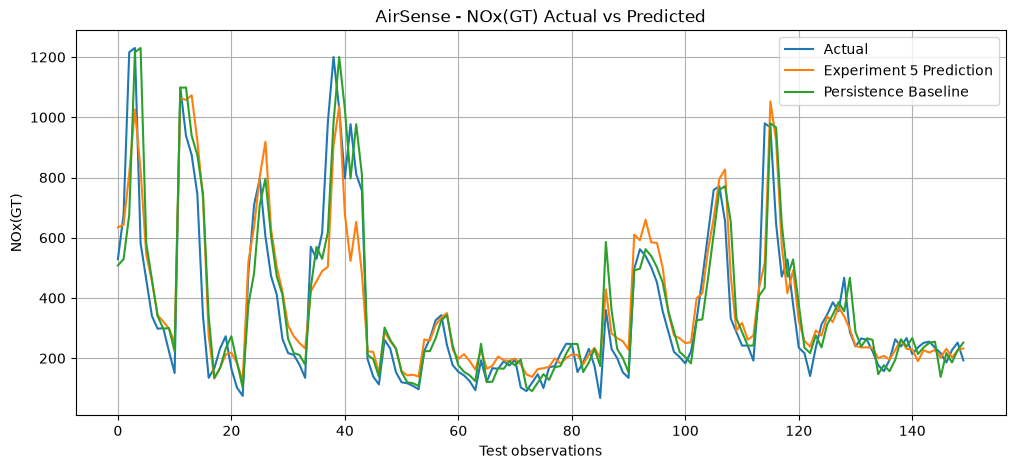

In [219]:
feature_index = 4
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - NOx(GT) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("NOx(GT)")
plt.legend()
plt.grid(True)
plt.show()

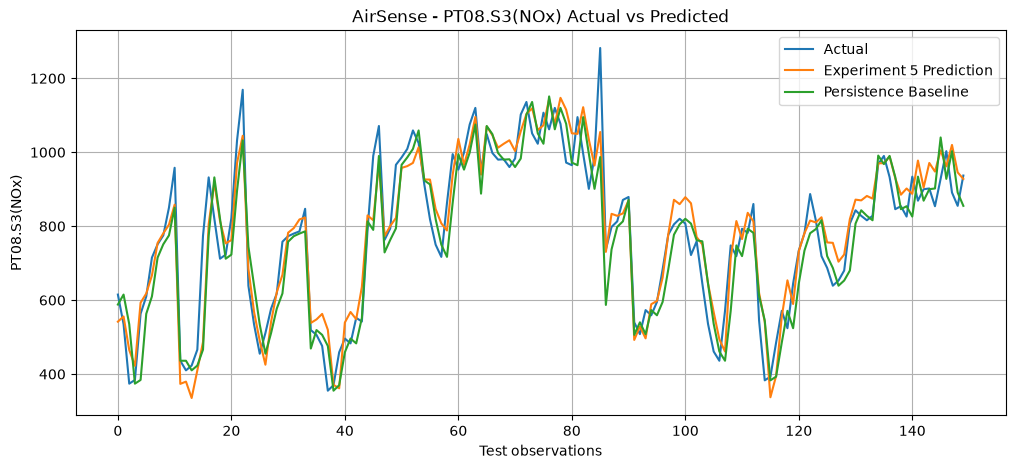

In [220]:
feature_index = 5
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - PT08.S3(NOx) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("PT08.S3(NOx)")
plt.legend()
plt.grid(True)
plt.show()

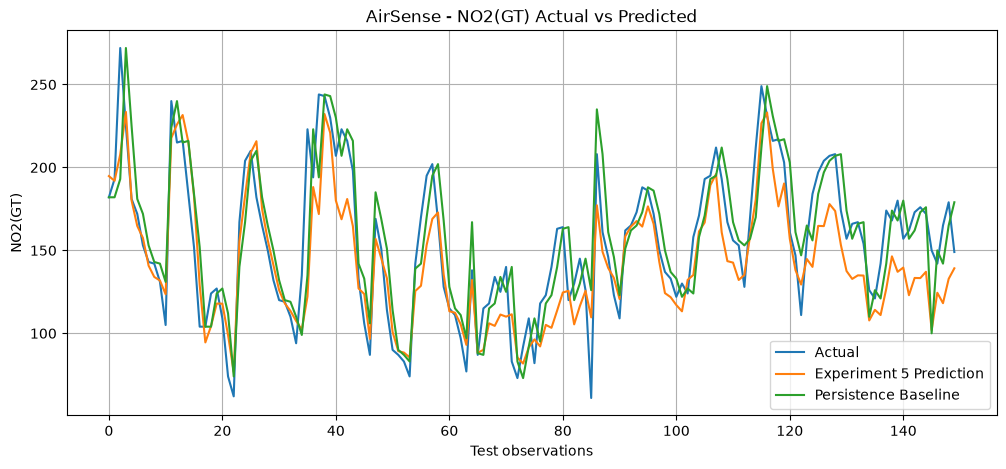

In [221]:
feature_index = 6
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - NO2(GT) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("NO2(GT)")
plt.legend()
plt.grid(True)
plt.show()

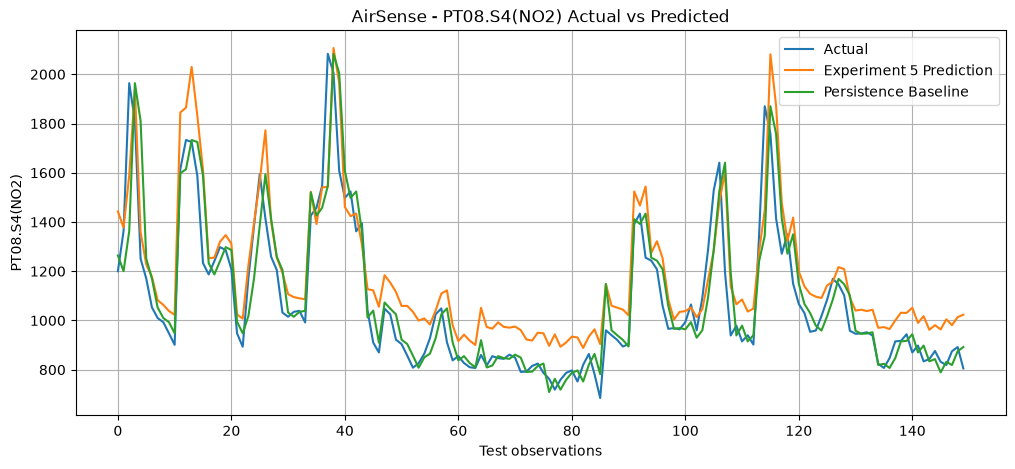

In [222]:
feature_index = 7
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - PT08.S4(NO2) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("PT08.S4(NO2)")
plt.legend()
plt.grid(True)
plt.show()

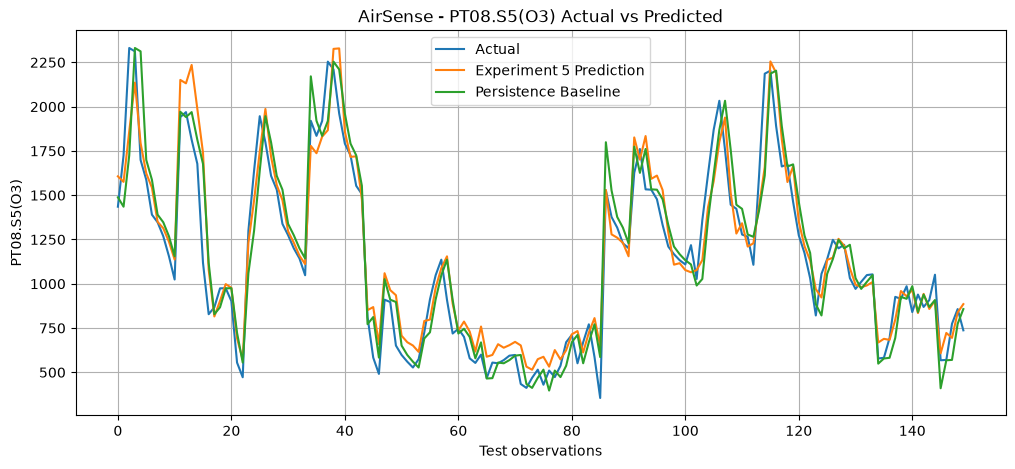

In [223]:
feature_index = 8
original_index = selected_indices_exp5[feature_index]

actual_original = (
    actual_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

predicted_original = (
    predictions_exp5[:, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

baseline_original = (
    test_X_exp5[:, -1, feature_index] * std_values[original_index]
    + mean_values[original_index]
)

plt.figure(figsize=(12, 5))

plt.plot(actual_original[:150], label="Actual")
plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
plt.plot(baseline_original[:150], label="Persistence Baseline")

plt.title("AirSense - PT08.S5(O3) Actual vs Predicted")
plt.xlabel("Test observations")
plt.ylabel("PT08.S5(O3)")
plt.legend()
plt.grid(True)
plt.show()


In [224]:
import os

os.makedirs("evaluation/graphs", exist_ok=True)

print("Graph folder created successfully!")

Graph folder created successfully!


In [225]:
feature_names = [
    "CO_GT",
    "PT08_S1_CO",
    "C6H6_GT",
    "PT08_S2_NMHC",
    "NOx_GT",
    "PT08_S3_NOx",
    "NO2_GT",
    "PT08_S4_NO2",
    "PT08_S5_O3"
]

for i, feature_name in enumerate(feature_names):

    original_index = selected_indices_exp5[i]

    actual_original = (
        actual_exp5[:, i] * std_values[original_index]
        + mean_values[original_index]
    )

    predicted_original = (
        predictions_exp5[:, i] * std_values[original_index]
        + mean_values[original_index]
    )

    baseline_original = (
        test_X_exp5[:, -1, i] * std_values[original_index]
        + mean_values[original_index]
    )

    plt.figure(figsize=(12, 5))

    plt.plot(actual_original[:150], label="Actual")
    plt.plot(predicted_original[:150], label="Experiment 5 Prediction")
    plt.plot(baseline_original[:150], label="Persistence Baseline")

    plt.title(f"AirSense - {feature_name} Actual vs Predicted")
    plt.xlabel("Test observations")
    plt.ylabel(feature_name)
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"evaluation/graphs/{feature_name}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("All 9 graphs saved successfully!")

All 9 graphs saved successfully!


In [226]:
import torch

checkpoint = torch.load(
    "model/experiment_5/airsense_exp5_best.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Checkpoint contents:", checkpoint.keys())

Checkpoint loaded successfully!
Checkpoint contents: odict_keys(['position_embedding', 'input_projection.weight', 'input_projection.bias', 'transformer.layers.0.self_attn.in_proj_weight', 'transformer.layers.0.self_attn.in_proj_bias', 'transformer.layers.0.self_attn.out_proj.weight', 'transformer.layers.0.self_attn.out_proj.bias', 'transformer.layers.0.linear1.weight', 'transformer.layers.0.linear1.bias', 'transformer.layers.0.linear2.weight', 'transformer.layers.0.linear2.bias', 'transformer.layers.0.norm1.weight', 'transformer.layers.0.norm1.bias', 'transformer.layers.0.norm2.weight', 'transformer.layers.0.norm2.bias', 'transformer.layers.1.self_attn.in_proj_weight', 'transformer.layers.1.self_attn.in_proj_bias', 'transformer.layers.1.self_attn.out_proj.weight', 'transformer.layers.1.self_attn.out_proj.bias', 'transformer.layers.1.linear1.weight', 'transformer.layers.1.linear1.bias', 'transformer.layers.1.linear2.weight', 'transformer.layers.1.linear2.bias', 'transformer.layers.1.nor

In [227]:
import torch
import torch.nn as nn

class AirSenseTransformerExp5(nn.Module):
    def __init__(self):
        super().__init__()

        self.input_projection = nn.Linear(9, 64)
        self.position_embedding = nn.Parameter(
            torch.zeros(1, 12, 64)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.output_layer = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 9)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = x + self.position_embedding
        x = self.transformer(x)
        x = x[:, -1, :]
        return self.output_layer(x)


print("AirSense model architecture recreated!")

AirSense model architecture recreated!


In [229]:
model_exp5 = AirSenseTransformerExp5()

model_exp5.load_state_dict(checkpoint)

model_exp5.eval()

print("Trained AirSense model loaded successfully!")
print("Model is ready for predictions.")

RuntimeError: Error(s) in loading state_dict for AirSenseTransformerExp5:
	size mismatch for output_layer.0.weight: copying a param with shape torch.Size([128, 64]) from checkpoint, the shape in current model is torch.Size([64, 64]).
	size mismatch for output_layer.0.bias: copying a param with shape torch.Size([128]) from checkpoint, the shape in current model is torch.Size([64]).
	size mismatch for output_layer.3.weight: copying a param with shape torch.Size([9, 128]) from checkpoint, the shape in current model is torch.Size([9, 64]).

In [230]:
class AirSenseTransformerExp5(nn.Module):
    def __init__(self):
        super().__init__()

        self.input_projection = nn.Linear(9, 64)
        self.position_embedding = nn.Parameter(
            torch.zeros(1, 12, 64)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.output_layer = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 9)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = x + self.position_embedding
        x = self.transformer(x)
        x = x[:, -1, :]
        return self.output_layer(x)


print("Corrected AirSense architecture created!")

Corrected AirSense architecture created!


In [231]:
model_exp5 = AirSenseTransformerExp5()

model_exp5.load_state_dict(checkpoint)

model_exp5.eval()

print("Trained AirSense model loaded successfully!")
print("Model is ready for predictions.")


Trained AirSense model loaded successfully!
Model is ready for predictions.


In [232]:
sample_input = torch.tensor(
    test_X_exp5[0:1],
    dtype=torch.float32
)

with torch.no_grad():
    prediction = model_exp5(sample_input)

print("Input shape:", sample_input.shape)
print("Prediction shape:", prediction.shape)
print("\nPredicted normalized values:")
print(prediction.numpy())

Input shape: torch.Size([1, 12, 9])
Prediction shape: torch.Size([1, 9])

Predicted normalized values:
[[ 1.0775211   0.56714576  0.9735971   0.9497712   1.9348818  -1.1550958
   2.1195219  -0.6568434   1.3339318 ]]


In [233]:
import numpy as np

original_indices = selected_indices_exp5

predicted_original = (
    prediction.numpy()[0] *
    std_values[original_indices]
    + mean_values[original_indices]
)

selected_feature_names = [
    "CO(GT)",
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)"
]

print("NEXT-HOUR PREDICTIONS")
print("-" * 40)

for name, value in zip(selected_feature_names, predicted_original):
    print(f"{name}: {value:.3f}")

NEXT-HOUR PREDICTIONS
----------------------------------------
CO(GT): 4.052
PT08.S1(CO): 1280.142
C6H6(GT): 20.140
PT08.S2(NMHC): 1280.089
NOx(GT): 634.857
PT08.S3(NOx): 541.710
NO2(GT): 194.777
PT08.S4(NO2): 1442.952
PT08.S5(O3): 1606.479


In [234]:
airsense_knowledge = {
    "CO(GT)": "Carbon Monoxide. A harmful gas produced by incomplete combustion.",
    "PT08.S1(CO)": "Sensor response associated with carbon monoxide.",
    "C6H6(GT)": "Benzene concentration, a volatile organic compound.",
    "PT08.S2(NMHC)": "Sensor response associated with non-methane hydrocarbons.",
    "NOx(GT)": "Nitrogen oxides, a group of gases including nitric oxide and nitrogen dioxide.",
    "PT08.S3(NOx)": "Sensor response associated with nitrogen oxides.",
    "NO2(GT)": "Nitrogen dioxide, an air pollutant that can affect respiratory health.",
    "PT08.S4(NO2)": "Sensor response associated with nitrogen dioxide.",
    "PT08.S5(O3)": "Sensor response associated with ozone-related measurements."
}

print("AirSense knowledge base created!")
print("Number of entries:", len(airsense_knowledge))

AirSense knowledge base created!
Number of entries: 9


In [235]:
def airsense_chatbot(question):

    question = question.lower()

    for feature, explanation in airsense_knowledge.items():

        if feature.lower() in question:
            return f"{feature}: {explanation}"

    keywords = {
        "carbon monoxide": "CO(GT)",
        "benzene": "C6H6(GT)",
        "nitrogen oxides": "NOx(GT)",
        "nitrogen dioxide": "NO2(GT)",
        "ozone": "PT08.S5(O3)"
    }

    for keyword, feature in keywords.items():
        if keyword in question:
            return f"{feature}: {airsense_knowledge[feature]}"

    return "I don't have enough information to answer that question yet."


print("AirSense chatbot function created!")

AirSense chatbot function created!


In [236]:
questions = [
    "What is carbon monoxide?",
    "Explain NOx",
    "What is benzene?",
    "What does PT08.S1(CO) measure?",
    "What is nitrogen dioxide?"
]

for question in questions:
    print("\nYou:", question)
    print("AirSense:", airsense_chatbot(question))


You: What is carbon monoxide?
AirSense: CO(GT): Carbon Monoxide. A harmful gas produced by incomplete combustion.

You: Explain NOx
AirSense: I don't have enough information to answer that question yet.

You: What is benzene?
AirSense: C6H6(GT): Benzene concentration, a volatile organic compound.

You: What does PT08.S1(CO) measure?
AirSense: PT08.S1(CO): Sensor response associated with carbon monoxide.

You: What is nitrogen dioxide?
AirSense: NO2(GT): Nitrogen dioxide, an air pollutant that can affect respiratory health.


In [237]:
def airsense_chatbot(question):

    question = question.lower()

    keywords = {
        "carbon monoxide": "CO(GT)",
        "co": "CO(GT)",
        "nox": "NOx(GT)",
        "nitrogen oxides": "NOx(GT)",
        "benzene": "C6H6(GT)",
        "c6h6": "C6H6(GT)",
        "nitrogen dioxide": "NO2(GT)",
        "no2": "NO2(GT)",
        "ozone": "PT08.S5(O3)",
        "pt08.s1": "PT08.S1(CO)",
        "pt08.s2": "PT08.S2(NMHC)",
        "pt08.s3": "PT08.S3(NOx)",
        "pt08.s4": "PT08.S4(NO2)",
        "pt08.s5": "PT08.S5(O3)"
    }

    for keyword, feature in keywords.items():
        if keyword in question:
            return f"{feature}: {airsense_knowledge[feature]}"

    return "I don't have enough information to answer that question yet."


print("AirSense chatbot updated successfully!")

AirSense chatbot updated successfully!


In [238]:
test_questions = [
    "What is carbon monoxide?",
    "Explain NOx",
    "What is benzene?",
    "What is NO2?",
    "What does PT08.S5 measure?"
]

for question in test_questions:
    print("\nYou:", question)
    print("AirSense:", airsense_chatbot(question))


You: What is carbon monoxide?
AirSense: CO(GT): Carbon Monoxide. A harmful gas produced by incomplete combustion.

You: Explain NOx
AirSense: NOx(GT): Nitrogen oxides, a group of gases including nitric oxide and nitrogen dioxide.

You: What is benzene?
AirSense: C6H6(GT): Benzene concentration, a volatile organic compound.

You: What is NO2?
AirSense: NO2(GT): Nitrogen dioxide, an air pollutant that can affect respiratory health.

You: What does PT08.S5 measure?
AirSense: PT08.S5(O3): Sensor response associated with ozone-related measurements.


In [239]:
def airsense_predict_next_hour(input_data):

    input_tensor = torch.tensor(
        input_data,
        dtype=torch.float32
    ).unsqueeze(0)

    model_exp5.eval()

    with torch.no_grad():
        output = model_exp5(input_tensor)

    predicted_values = (
        output.numpy()[0] *
        std_values[selected_indices_exp5]
        + mean_values[selected_indices_exp5]
    )

    results = {}

    for name, value in zip(
        selected_feature_names,
        predicted_values
    ):
        results[name] = round(float(value), 3)

    return results


print("AirSense prediction function created!")

AirSense prediction function created!


In [240]:
def airsense_chatbot(question):

    question = question.lower()

    keywords = {
        "carbon monoxide": "CO(GT)",
        "co": "CO(GT)",
        "nox": "NOx(GT)",
        "nitrogen oxides": "NOx(GT)",
        "benzene": "C6H6(GT)",
        "c6h6": "C6H6(GT)",
        "nitrogen dioxide": "NO2(GT)",
        "no2": "NO2(GT)",
        "ozone": "PT08.S5(O3)",
        "pt08.s1": "PT08.S1(CO)",
        "pt08.s2": "PT08.S2(NMHC)",
        "pt08.s3": "PT08.S3(NOx)",
        "pt08.s4": "PT08.S4(NO2)",
        "pt08.s5": "PT08.S5(O3)"
    }

    for keyword, feature in keywords.items():
        if keyword in question:
            return f"{feature}: {airsense_knowledge[feature]}"

    return "I'm sorry, I don't know or I'm not aware of that information."


print("AirSense fallback response updated!")

AirSense fallback response updated!


In [241]:
test_questions = [
    "What is NOx?",
    "What is benzene?",
    "Who invented the telephone?",
    "What is the capital of Japan?"
]

for question in test_questions:
    print("\nYou:", question)
    print("AirSense:", airsense_chatbot(question))


You: What is NOx?
AirSense: NOx(GT): Nitrogen oxides, a group of gases including nitric oxide and nitrogen dioxide.

You: What is benzene?
AirSense: C6H6(GT): Benzene concentration, a volatile organic compound.

You: Who invented the telephone?
AirSense: I'm sorry, I don't know or I'm not aware of that information.

You: What is the capital of Japan?
AirSense: I'm sorry, I don't know or I'm not aware of that information.


In [242]:
def airsense_predict_next_hour(input_data):

    input_tensor = torch.tensor(
        input_data,
        dtype=torch.float32
    ).unsqueeze(0)

    model_exp5.eval()

    with torch.no_grad():
        output = model_exp5(input_tensor)

    predicted_values = (
        output.numpy()[0] *
        std_values[selected_indices_exp5]
        + mean_values[selected_indices_exp5]
    )

    results = {}

    for name, value in zip(
        selected_feature_names,
        predicted_values
    ):
        results[name] = round(float(value), 3)

    return results


print("AirSense prediction function created!")

AirSense prediction function created!


In [243]:
sample_data = test_X_exp5[0]

predictions = airsense_predict_next_hour(sample_data)

print("AIRSENSE NEXT-HOUR FORECAST")
print("-" * 40)

for feature, value in predictions.items():
    print(f"{feature}: {value}")

AIRSENSE NEXT-HOUR FORECAST
----------------------------------------
CO(GT): 4.052
PT08.S1(CO): 1280.142
C6H6(GT): 20.14
PT08.S2(NMHC): 1280.089
NOx(GT): 634.857
PT08.S3(NOx): 541.71
NO2(GT): 194.777
PT08.S4(NO2): 1442.952
PT08.S5(O3): 1606.479


In [244]:
def airsense_assistant(question):

    question_lower = question.lower()

    prediction_keywords = [
        "predict",
        "prediction",
        "forecast",
        "next hour",
        "future reading"
    ]

    if any(word in question_lower for word in prediction_keywords):

        results = airsense_predict_next_hour(
            test_X_exp5[0]
        )

        response = "AirSense Next-Hour Forecast:\n"

        for feature, value in results.items():
            response += f"\n{feature}: {value}"

        response += "\n\nNote: These are model-generated estimates, not live sensor measurements."

        return response

    return airsense_chatbot(question)


print("AirSense conversational assistant created!")

AirSense conversational assistant created!


In [245]:
test_questions = [
    "What is carbon monoxide?",
    "Explain nitrogen dioxide",
    "Predict the next hour's air quality",
    "Who invented the telephone?"
]

for question in test_questions:
    print("\nYou:", question)
    print("AirSense:", airsense_assistant(question))
    print("-" * 50)


You: What is carbon monoxide?
AirSense: CO(GT): Carbon Monoxide. A harmful gas produced by incomplete combustion.
--------------------------------------------------

You: Explain nitrogen dioxide
AirSense: NO2(GT): Nitrogen dioxide, an air pollutant that can affect respiratory health.
--------------------------------------------------

You: Predict the next hour's air quality
AirSense: AirSense Next-Hour Forecast:

CO(GT): 4.052
PT08.S1(CO): 1280.142
C6H6(GT): 20.14
PT08.S2(NMHC): 1280.089
NOx(GT): 634.857
PT08.S3(NOx): 541.71
NO2(GT): 194.777
PT08.S4(NO2): 1442.952
PT08.S5(O3): 1606.479

Note: These are model-generated estimates, not live sensor measurements.
--------------------------------------------------

You: Who invented the telephone?
AirSense: I'm sorry, I don't know or I'm not aware of that information.
--------------------------------------------------


In [246]:
def airsense_assistant(question, input_data=None):

    question_lower = question.lower()

    prediction_keywords = [
        "predict",
        "prediction",
        "forecast",
        "next hour",
        "future reading"
    ]

    if any(word in question_lower for word in prediction_keywords):

        if input_data is None:
            return "Please provide 12 hours of air-quality readings first."

        results = airsense_predict_next_hour(input_data)

        response = "AirSense Next-Hour Forecast:\n"

        for feature, value in results.items():
            response += f"\n{feature}: {value}"

        response += "\n\nThese are model-generated estimates, not live measurements."

        return response

    return airsense_chatbot(question)


print("User-input forecasting enabled!")

User-input forecasting enabled!


In [247]:
import pandas as pd

input_template = pd.DataFrame(columns=selected_feature_names)

input_template.to_csv(
    "airsense_input_template.csv",
    index=False
)

print("CSV template created successfully!")
print("Required rows: 12")
print("Required columns:", selected_feature_names)

CSV template created successfully!
Required rows: 12
Required columns: ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)']


In [248]:
def airsense_load_csv(file_path):

    data = pd.read_csv(file_path)

    if list(data.columns) != selected_feature_names:
        raise ValueError("CSV columns do not match the required format.")

    if data.shape[0] != 12:
        raise ValueError("CSV must contain exactly 12 hourly readings.")

    if data.isnull().values.any():
        raise ValueError("CSV contains missing values.")

    if not data.apply(lambda col: pd.to_numeric(col, errors="coerce").notna().all()).all():
        raise ValueError("All readings must be numeric.")

    readings = data.astype(float).values

    # Normalize using the original training statistics
    normalized_readings = (
        readings - mean_values[selected_indices_exp5]
    ) / std_values[selected_indices_exp5]

    print("CSV loaded and validated successfully!")

    return normalized_readings.astype("float32")


print("AirSense CSV loader is ready!")

AirSense CSV loader is ready!


In [249]:
# Load the CSV file
user_readings = airsense_load_csv("airsense_input_template.csv")

# Generate forecast
forecast = airsense_predict_next_hour(user_readings)

print("\nAIRSENSE FORECAST")
for feature, value in forecast.items():
    print(f"{feature}: {value}")

ValueError: CSV must contain exactly 12 hourly readings.

In [250]:
sample_readings = pd.DataFrame(
    test_X_exp5[0] * std_values[selected_indices_exp5]
    + mean_values[selected_indices_exp5],
    columns=selected_feature_names
)

sample_readings.to_csv(
    "airsense_input_template.csv",
    index=False
)

print("Sample CSV created!")
print(sample_readings)

Sample CSV created!
    CO(GT)  PT08.S1(CO)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  \
0      0.7        837.0       1.1          512.0     95.0        1228.0   
1      0.5        795.0       1.0          504.0     94.0        1258.0   
2      0.7        874.0       1.6          552.0    121.0        1162.0   
3      1.0        920.0       3.2          667.0    131.0        1005.0   
4      3.0       1257.0      15.9         1176.0    552.0         612.0   
5      4.1       1222.0      18.0         1239.0    614.0         574.0   
6      3.1       1196.0      14.7         1139.0    530.0         617.0   
7      3.8       1214.0      15.1         1153.0    721.0         612.0   
8      2.7       1149.0      13.4         1096.0    474.0         639.0   
9      3.1       1166.0      14.5         1134.0    514.0         603.0   
10     3.1       1170.0      14.7         1138.0    504.0         611.0   
11     3.2       1176.0      17.0         1209.0    508.0         588.0   

    

In [251]:
# Load and normalize the CSV
user_readings = airsense_load_csv("airsense_input_template.csv")

# Generate next-hour forecast
forecast = airsense_predict_next_hour(user_readings)

print("\n========== AIRSENSE FORECAST ==========")

for feature, value in forecast.items():
    print(f"{feature}: {value}")

print("\nForecast generated successfully!")

CSV loaded and validated successfully!

========== AIRSENSE FORECAST ==========
CO(GT): 4.052
PT08.S1(CO): 1280.142
C6H6(GT): 20.14
PT08.S2(NMHC): 1280.089
NOx(GT): 634.857
PT08.S3(NOx): 541.71
NO2(GT): 194.777
PT08.S4(NO2): 1442.952
PT08.S5(O3): 1606.479

Forecast generated successfully!


In [252]:
import importlib.util

if importlib.util.find_spec("streamlit"):
    print("Streamlit is already installed!")
else:
    print("Streamlit needs to be installed.")

Streamlit needs to be installed.


In [253]:
%pip install streamlit


  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 1.9 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/11.2 MB 1.9 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/11.2 MB 1.9 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/11.2 MB 1.9 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/11.2 MB 1.9 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/11.2 MB 1.9 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/11.2 MB 1.9 MB/s eta 0:00:05
   ------------- -------------------------- 3.7/11.2 MB 2.0 MB/s eta 0:00:04
   -------------- ------------------------- 4.2/11.2 MB 2.1 MB/s eta 0:00:04
   ---------------- -


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [254]:
import os
import streamlit

print("Streamlit version:", streamlit.__version__)
print("Current project folder:", os.getcwd())

Streamlit version: 1.67.0
Current project folder: C:\Users\malav\OneDrive\Documents\SLM_AirQuality_New


In [255]:
import os

required_files = [
    "model/experiment_5/airsense_exp5_best.pt",
    "data/processed/normalized_12h/mean.npy",
    "data/processed/normalized_12h/std.npy"
]

for file in required_files:
    print(file, "—", "FOUND" if os.path.exists(file) else "NOT FOUND")

model/experiment_5/airsense_exp5_best.pt — FOUND
data/processed/normalized_12h/mean.npy — NOT FOUND
data/processed/normalized_12h/std.npy — NOT FOUND


In [256]:
import os

for file in [
    "data/processed/normalized/mean.npy",
    "data/processed/normalized/std.npy"
]:
    print(file, "—", "FOUND" if os.path.exists(file) else "NOT FOUND")

data/processed/normalized/mean.npy — FOUND
data/processed/normalized/std.npy — FOUND


In [257]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

# -----------------------------
# PAGE CONFIGURATION
# -----------------------------

st.set_page_config(
    page_title="AirSense",
    page_icon="🌍",
    layout="wide"
)

st.title("🌍 AirSense")
st.subheader("AI-powered Air Quality Understanding and Forecasting")

st.write(
    "Ask questions about air-quality measurements "
    "or upload readings to generate a next-hour forecast."
)

# -----------------------------
# FEATURE INFORMATION
# -----------------------------

features = [
    "CO(GT)", "PT08.S1(CO)", "C6H6(GT)",
    "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)",
    "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)"
]

knowledge = {
    "CO(GT)": "Carbon monoxide. A harmful gas produced by incomplete combustion.",
    "PT08.S1(CO)": "Sensor response associated with carbon monoxide.",
    "C6H6(GT)": "Benzene concentration, a volatile organic compound.",
    "PT08.S2(NMHC)": "Sensor response associated with non-methane hydrocarbons.",
    "NOx(GT)": "Nitrogen oxides, a group of gases including nitric oxide and nitrogen dioxide.",
    "PT08.S3(NOx)": "Sensor response associated with nitrogen oxides.",
    "NO2(GT)": "Nitrogen dioxide, an air pollutant that can affect respiratory health.",
    "PT08.S4(NO2)": "Sensor response associated with nitrogen dioxide.",
    "PT08.S5(O3)": "Sensor response associated with ozone-related measurements."
}

# -----------------------------
# CHATBOT
# -----------------------------

def airsense_chatbot(question):

    q = question.lower()

    keywords = {
        "carbon monoxide": "CO(GT)",
        "benzene": "C6H6(GT)",
        "nitrogen oxides": "NOx(GT)",
        "nox": "NOx(GT)",
        "nitrogen dioxide": "NO2(GT)",
        "no2": "NO2(GT)",
        "ozone": "PT08.S5(O3)",
        "pt08.s1": "PT08.S1(CO)",
        "pt08.s2": "PT08.S2(NMHC)",
        "pt08.s3": "PT08.S3(NOx)",
        "pt08.s4": "PT08.S4(NO2)",
        "pt08.s5": "PT08.S5(O3)"
    }

    for keyword, feature in keywords.items():
        if keyword in q:
            return f"{feature}: {knowledge[feature]}"

    return "I'm sorry, I don't know or I'm not aware of that information."

# -----------------------------
# FORECASTING MODEL
# -----------------------------

class AirSenseTransformerExp5(nn.Module):

    def __init__(self):
        super().__init__()

        self.input_projection = nn.Linear(9, 64)
        self.position_embedding = nn.Parameter(torch.zeros(1, 12, 64))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.output_layer = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 9)
        )

    def forward(self, x):

        x = self.input_projection(x)
        x = x + self.position_embedding
        x = self.transformer(x)
        x = x[:, -1, :]

        return self.output_layer(x)


@st.cache_resource
def load_airsense_model():

    model = AirSenseTransformerExp5()

    checkpoint = torch.load(
        "model/experiment_5/airsense_exp5_best.pt",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint)
    model.eval()

    mean = np.load("data/processed/normalized/mean.npy")
    std = np.load("data/processed/normalized/std.npy")

    return model, mean, std


# -----------------------------
# APPLICATION TABS
# -----------------------------

chat_tab, forecast_tab = st.tabs(
    ["💬 Ask AirSense", "📊 Air Quality Forecast"]
)

# CHAT TAB

with chat_tab:

    st.subheader("Ask an Air Quality Question")

    question = st.text_input(
        "Enter your question:"
    )

    if st.button("Ask AirSense"):

        if question.strip():
            st.info(airsense_chatbot(question))
        else:
            st.warning("Please enter a question.")


# FORECAST TAB

with forecast_tab:

    st.subheader("Next-Hour Air Quality Forecast")

    st.write(
        "Upload a CSV containing exactly 12 hourly readings "
        "for the nine required features."
    )

    uploaded_file = st.file_uploader(
        "Upload your CSV file",
        type=["csv"]
    )

    if uploaded_file is not None:

        try:

            data = pd.read_csv(uploaded_file)

            if list(data.columns) != features:
                st.error("CSV columns do not match the required format.")

            elif data.shape[0] != 12:
                st.error("CSV must contain exactly 12 hourly readings.")

            else:

                data = data.apply(
                    pd.to_numeric,
                    errors="coerce"
                )

                if data.isnull().values.any() or not np.isfinite(data.values).all():

                    st.error("CSV contains missing or invalid numerical values.")

                else:

                    st.success("CSV uploaded and validated successfully!")

                    st.dataframe(data)

                    if st.button("Generate Forecast"):

                        model, mean, std = load_airsense_model()

                        selected_indices = np.arange(9)

                        normalized = (
                            data.values - mean[selected_indices]
                        ) / std[selected_indices]

                        input_tensor = torch.tensor(
                            normalized,
                            dtype=torch.float32
                        ).unsqueeze(0)

                        with torch.no_grad():
                            output = model(input_tensor)

                        predictions = (
                            output.numpy()[0] *
                            std[selected_indices] +
                            mean[selected_indices]
                        )

                        st.subheader("Predicted Next-Hour Readings")

                        results = pd.DataFrame({
                            "Feature": features,
                            "Predicted Value": np.round(predictions, 3)
                        })

                        st.dataframe(
                            results,
                            use_container_width=True
                        )

                        st.caption(
                            "These are model-generated estimates, "
                            "not live sensor measurements or health assessments."
                        )

        except Exception as e:

            st.error(f"An error occurred: {e}")


st.divider()

st.caption(
    "AirSense | Academic project prototype | "
    "Forecasting model and rule-based conversational assistant"
)

Writing app.py


In [258]:
cd "C:\Users\malav\OneDrive\Documents\SLM_AirQuality_New"

C:\Users\malav\OneDrive\Documents\SLM_AirQuality_New
